# Оценка качества интернет-соединения

## Описание исследования<a id="p00"></a>

Для понимания качества и стабильности интернет-соединения необходимо провести сбор, анализ и оценку данных его ключевых метрик: скорости скачивания и загрузки, времени задержки (пинга), стабильности соединения и прочих.

### Цель исследования<a id="p01"></a>

Провести оценку стабильности и качества интернет-соединения путем сбора, анализа и оценки данных его ключевых метрик:
- скорость скачивания и загрузки,
- пинг,
- джиттер,
- потеря пакетов,
- частота обрывов.

Дополнительно проверим гипотезу:
1. Скорость интернет-соединения зависит от времени суток.

И ответим на вопросы:
- В какое время суток, час, день недели показатели метрик самые высокие и низкие соответственно?

### Объект исследования <a id="p02"></a>

Будем исследовать метрики гигабитного тарифа с заявленной скоростью 1000 Мбит/с, и проводным Ethernet типом подключения.

### Входные данные <a id="p03"></a>

Данные метрик интернет-соединения представлены в формате `.csv` в файле `internet_speed.csv`.

### Ход исследования <a id="p04"></a>

Исследование будет проходит в несколько этапов:

1. **Сбор данных**. Автоматизируем процесс сбора и соберем необходимые для анализа данные.
2. **Обзор данных**.
   Составим первое представление о собранных данных и сделаем выводы о необходимости их предобработки.
3. **Предобработка данных**.
   Оценим влияние выявленных ошибок на исследование и найдем возможность их исправить.
4. **Расчет и анализ метрик**.
5. **Оценка качества и стабильности интернет-соединения**.
6. **Итоги исследования**.

## Содержание

**[Описание исследования](#p00)**
    <br>[Цель исследования](#p01)
    <br>[Объект исследования](#p02)
    <br>[Входные данные](#p03)
    <br>[Ход исследования](#p04)
1. **[Сбор данных](#p1)**
2. **[Обзор данных](#p2)**
3. **[Предобработка данных](#p3)**
    <br>3.1. [Замена типов и оптимизация данных](#p31)
    <br>3.2. [Удаление неявных дубликатов](#p32)
    <br>3.3. [Расчет вспомогательных параметров](#p33)
    <br>3.4. [Заполнение пропусков](#p34)
    <br>3.5. [Устанение аномалий и выбросов](#p35)
    <br>3.6. [Категоризация данных](#p36)
5. **[Анализ метрик](#p4)**
    <br>4.1. [Общая описательная статистика](#p41)
    <br>4.2. [Скорость скачивания (Download, D) и загрузки (Upload, U)](#p42)
    <br>4.3. [Пинг (Ping, P) и Джиттер (Jitter, J)](#p43)
    <br>4.4. [Потеря пакетов (Loss, L) и Частота обрывов (Disconnects, Dc)](#p44)
    <br>4.5. [Проверка гипотез](#p45)
6. **[Оценка качества и стабильности интернет-соединения](#p5)**
    <br>5.1. [Нормализация показателей](#p51)
    <br>5.2. [Оценка качества соединения](#p52)

**[Итоги исследования](#conclusion)**


## Библиотеки

In [1]:
import traceback
# from rich.traceback import install
# install(show_locals=True)
try:
    # Импорт библиотек
    import pandas as pd
    import numpy as np
    # from json import dumps
    # import warnings

    import sys
    sys.path.append('..')
    from lib.analytics import *
    
    # Настройки
    # pd.set_option('display.max_columns', 100)
    # pd.set_option('display.max_rows', 100)
    pd.options.display.max_columns = None
    pd.set_option('display.float_format', '{:.2f}'.format)
    # Graphics in svg format are more sharp and legible
    # %config InlineBackend.figure_format = 'svg' 
    %config InlineBackend.figure_format = 'jpeg'
    # Graphics in retina format are more sharp and legible
    # %config InlineBackend.figure_format = 'retina'
    # Suppress the specific FutureWarning
    # warnings.filterwarnings('ignore', category=FutureWarning, module='seaborn')
    
    print('Библиотеки импортированы. Статус: OK')
    print_env_info()
except Exception:
    print('Ошибка импорта')
    traceback.print_exc()

Библиотеки импортированы. Статус: OK
Python    : 3.14.2
Jupyter   : 7.5.6
pandas    : 3.0.1
matplotlib: 3.10.8
seaborn   : 0.13.2


### Вспомогательные функции

In [2]:
def get_metric(m=None, p=None, only_key=False):
    '''
    Возвращает параметр, словарь параметров метрик(и) или список ключей метрик.
    
    :param str|None m: Ключ метрики
    :param str|None p: Ключ параметра
    :param bool only_key: Флаг «только ключи» — выводит список названий (ключей) метрик

    :example:
    `get_metric()` //=> 
    `{'download':{…}, 'upload':{…}, 'ping':{…}, …}`
    `get_metric('ping')` //=> 
    `{ 'title': 'Ping', 'ylabel': 'Пинг, ms', 'info': 'Время задержки' }`
    `get_metric('ping', 'info')` //=> 
    `Время задержки`
    `get_metric(only_key=True)` //=> 
    `['download', 'upload', 'ping', …]`
    '''
    metrics = {
        'download': { 'title': 'Скорость Download', 'ylabel': 'Скорость, Мбит/с', 'info': 'Скорость скачивания' }, 
        'upload': { 'title': 'Скорость Upload', 'ylabel': 'Скорость, Мбит/с', 'info': 'Скорость загрузки' }, 
        'ping': { 'title': 'Ping', 'ylabel': 'Пинг, ms', 'info': 'Время задержки' }, 
        'jitter': { 'title': 'Jitter', 'ylabel': 'Джиттер, ms', 'info': 'Колебания пинга' }, 
        'packet_loss': { 'title': 'Packet Loss', 'ylabel': 'Потеря пакетов, %', 'info': 'Процент потери пакетов' }, 
        'connection_lost': { 'title': 'Connection Lost', 'ylabel': 'Кол-во', 'info': 'Обрывы соединения' }
    }

    if only_key:
        return list(get_metric().keys())
    
    if p:
        return metrics.get(m).get(p) if m and metrics.get(m) else None

    return metrics.get(m) if m else metrics


def get_metrics_table(data, **kwargs):
    # Аргументы по-умолчанию
    return get_desc_stat_table(data, **({
        'metrics': get_metric(only_key=True), 
        'stat_fn': {'connection_lost': ['sum']},
        'stat_fn_def': ['min', 'max', 'mean', 'median', 'mode', 'count'],
        # 'query': good_data_query,
    } | kwargs))
    
def get_metrics_per_period_table(data, **kwargs):
    # Аргументы по-умолчанию
    return get_desc_stat_per_period_table(data, **({
        'metrics': get_metric(only_key=True), 
        'stat_fn': {'connection_lost': ['sum']},
        'stat_fn_def': ['min', 'max', 'mean', 'median', 'mode', 'count'],
        'group_index': 'time_period',
        'set_axis': 'time',
        'reindex': {'new_idx': [], 'level': ''},
        # 'query': good_data_query,
    } | kwargs))
    
def get_metrics_chart(data, **kwargs):
    # Аргументы по-умолчанию
    kwargs = deep_merge_dicts({'chart_kws': {
            'title': ['Скорость ↓', 'Скорость ↑', 'Частота обрывов', 'Пинг', 'Джиттер'], #'Потери пакетов',
            'ylabel': ['Скорость, Мбит/с', 'Скорость, Мбит/с', 'Количество', 'Пинг, ms', 'Джиттер, ms'],
            'legend_patch': [{'patch_color': 2, 'patch_edge': None, 'label': 'count'}],
            'color': {'packet_loss': 2, 'connection_lost': 2},
        },                                     
        'stat_fn_def': ['min', 'max'],
        'stat_fn': {'connection_lost': ['sum']},                             
        'axhline_def': ['mode', 'mean', 'median'], 
        'axhline': {'connection_lost': [], 'packet_loss': []},                          
        'metrics': ['download', 'upload', 'connection_lost', 'ping', 'jitter'], #, 'packet_loss'                                 
        'kinds': 'bar',
        'tpl': 'sbplot_01',
        'cls': '10x2.5 t-os sp-ws0.55' # t-tr t-oxs
    }, kwargs)
    
    return desc_stat_charts(data, **kwargs)

## 1. Сбор данных <a id="p1"></a>

На данном этапе собрали все необходимые для анализа данные, написав модуль автоматизирующий их сбор. Модуль с указанной периодичностью, в фоновом режиме, производил замеры необходимых  метрик, и сохранял данные с указанием времени в `csv`-файл. Выбор такого формата хранения в рамках данного проекта был обусловлен небольшим объемом данных. Данные собирались в течении 1 месяца, с периодичностью в 5 минут.

Сбор данных завершен. Переходим к обзору собранных данных.

## 2. Обзор данных <a id="p2"></a>

Составим первое представление о собранных данных и сделаем выводы о необходимости их предобработки. Загрузим файл с датасетом для первичного ознакомления

### Загрузка данных

In [3]:
try:
    df = load_dataset([f'assets/internet_speed_p{i}.csv' for i in range(1, 6)], parse_dates=['timestamp'])
    
    print('Файлы с данными считаны в датафрейм')
except:
    print('Файлы с данными не найдены')

Файлы с данными считаны в датафрейм


### Общая информация

In [4]:
print_rows(df, 3, mode='headtail')
print_counts(df)
# print_all_rows(df)

,timestamp,ping,jitter,download,upload,packet_loss,connection_lost,connection_recovered,connection_error,server_id,server_name,server_city,server_sponsor,server_host,server_distance
0,2025-06-11 14:32:24,5.08,1.11,839.52,720.94,0,False,False,Ok,25330,Yekaterinburg,Yekaterinburg,TTK Ural,speedtest.uralttk.ru:8080,4.37
1,2025-06-11 14:37:55,4.82,1.08,704.23,611.95,0,False,False,Ok,25330,Yekaterinburg,Yekaterinburg,TTK Ural,speedtest.uralttk.ru:8080,4.37
2,2025-06-11 14:43:09,4.09,0.65,847.74,889.70,0,False,False,Ok,25330,Yekaterinburg,Yekaterinburg,TTK Ural,speedtest.uralttk.ru:8080,4.37
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8662,2025-07-13 01:11:45,4.01,0.47,885.91,261.95,0,False,False,Ok,5681,Ekaterinburg,Ekaterinburg,MOTIV,speedtest.motivtelecom.ru:8080,4.37
8663,2025-07-13 01:17:59,4.07,0.37,911.82,900.68,0,False,False,Ok,5681,Ekaterinburg,Ekaterinburg,MOTIV,speedtest.motivtelecom.ru:8080,4.37
8664,2025-07-13 01:24:10,4.34,0.80,843.55,863.28,0,False,False,Ok,6616,Ekaterinburg,Ekaterinburg,t2 Russia,ekt1.companion.t2.ru:8080,4.37


Всего 8665 строк и 15 столбцов


Таблица с данными включает поля:
* `timestamp` – дата и время замера в формате `ГГГГ-ММ-ДД ЧЧ:ММ:СС`;
* `ping` – время задержки (латентность) в ms (среднее значение из нескольких измерений);
* `jitter` – разброс значений `ping` (разница между максимальным и минимальным `ping`) в ms;
* `download` – скорость скачивания в Мегабитах в секунду (Mbps)
* `upload` – скорость загрузки в Мегабитах в секунду (Mbps)
* `packet_loss` – процент потери пакетов (0-100%)
* `connection_lost` – флаг обрыва соединения (`True/False`):
    * `True` – соединение отсутствовало во время замера;
    * `False` – соединение было стабильным.
* `connection_recovered` – флаг восстановления соединения (`True/False`):
    * `True` – соединение восстановилось после предыдущего обрыва;
    * `False` – состояние соединения не изменилось.
* `connection_error` – текст ошибки при обрыве соединения;
* `server_id` - ID используемого сервера;
* `server_name` - название сервера;
* `server_city` - город расположения сервера;
* `server_sponsor` - компания, которой принадлежит сервер;
* `server_host` - адрес сервера;
* `server_distance` - расстояние до сервера.

Примечания:
* Поле `packet_loss` принимает значение `100%` при `connection_lost=True`;
* Поля `ping`, `jitter`, `download`, `upload` могут содержать `None` при обрыве соединения.

Выведем общую информацию о данных в таблице

In [5]:
print_info(df)

<class 'pandas.DataFrame'>
RangeIndex: 8665 entries, 0 to 8664
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   timestamp             8665 non-null   datetime64[us]
 1   ping                  8665 non-null   float64       
 2   jitter                8665 non-null   float64       
 3   download              8665 non-null   float64       
 4   upload                8665 non-null   float64       
 5   packet_loss           8665 non-null   int64         
 6   connection_lost       8665 non-null   bool          
 7   connection_recovered  8665 non-null   bool          
 8   connection_error      8665 non-null   str           
 9   server_id             8665 non-null   int64         
 10  server_name           8665 non-null   str           
 11  server_city           8665 non-null   str           
 12  server_sponsor        8665 non-null   str           
 13  server_host           8665 no

Посмотрим названия столбцов

In [6]:
print_columns(df)

Таблица включает столбцы:
---
timestamp
ping
jitter
download
upload
packet_loss
connection_lost
connection_recovered
connection_error
server_id
server_name
server_city
server_sponsor
server_host
server_distance


**В названиях столбцов отсутствуют нарушения стиля.**

### Проверка типов данных

In [7]:
print_dtype_counts(df)

Всего 8665 строк и 15 столбцов.
Из них типов данных:
---
float64           5
str               5
int64             2
bool              2
datetime64[us]    1


**Отсутствует несоответствие типа данных в столбцах.**

### Пропуски

In [8]:
print_gap_counts(df)

Количество пропусков:
---
timestamp               0
ping                    0
jitter                  0
download                0
upload                  0
packet_loss             0
connection_lost         0
connection_recovered    0
connection_error        0
server_id               0
server_name             0
server_city             0
server_sponsor          0
server_host             0
server_distance         0
dtype: int64


In [9]:
print_perc_gap_counts(df, out_zero=False)

Количество пропусков: 0


**В данных отсутствуют пропуски.**

### Дубликаты

Проверим на явные дубликаты

In [10]:
print_duplicated(df)

Количество явных дубликатов: 0


**Явные дубликаты отсутствуют.**

In [11]:
display_grid(
    [
        print_value_counts(df, ['server_name', 'server_city'], to_html=True, cut_last=True),
        print_value_counts(df, 'server_distance', to_html=True, cut_last=True, sort_index=True),
        print_value_counts(df, 'server_sponsor', to_html=True, cut_last=True)
    ],
    grid=[1, 3],
    title='НЕЯВНЫЕ ДУБЛИКАТЫ',
    format=True,
    vspace=35
)

В столбцах `server_name` и `server_city` присутствуют неявные дубликаты, вызванные разным написанием названия города `Екатеринбург`. В столбце `server_distance` также присутствуют неявные дубликаты.

**Присутствуют неявные дубликаты.**

### Характерные значения

Посмотрим характерные значения из числового описания данных в таблице

In [12]:
print_describe(df, column=['ping', 'jitter', 'download', 'upload', 'packet_loss'])

,ping,jitter,download,upload,packet_loss
count,8665.00,8665.00,8665.00,8665.00,8665.00
mean,6.00,4.00,794.00,786.00,0.00
std,9.00,25.00,113.00,156.00,2.00
min,3.00,0.00,46.00,0.00,0.00
25%,4.00,1.00,743.00,765.00,0.00
50%,5.00,1.00,832.00,860.00,0.00
75%,5.00,1.00,873.00,878.00,0.00
max,339.00,837.00,931.00,913.00,100.00


**Количество значений одинаково во всех столбцах. Присутствуют аномалии.**

### Выбросы

Посмотрим выбросы, расчитаем глобальный IQR для временного ряда

In [13]:
print_outlier_desc(df[['download', 'upload', 'ping', 'jitter']])

,download,upload,ping,jitter
min,46.47,0.00,2.85,0.05
max,930.82,912.61,339.34,837.32
Q1,743.33,764.64,4.14,0.70
Q3,872.93,877.71,5.01,1.28
IQR,129.60,113.07,0.87,0.58
lower_c,548.93,595.03,2.83,-0.17
upper_c,1 067.33,1 047.32,6.32,2.15
lower,549.19,595.07,2.85,0.05
upper,930.82,912.61,6.31,2.15
lower_cnt,313,967,0,0


**Присутствует большое количество выбросов, которые могут быть связаны с сетевыми аномалиями или ошибками измерений**

### Распределение

In [14]:
# Ключи метрик ['download', 'upload', 'ping', 'jitter', …]
metric_lst = get_metric(only_key=True)
# Распределение
for m in metric_lst:
    print_distr_desc(df[m], metric=m, show_help=1)


| download |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | left skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | -1.96 |
| Kurtosis (эксцесс) | 8.45 |
    


| upload |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | left skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | -2.23 |
| Kurtosis (эксцесс) | 7.87 |
    


| ping |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | right skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | 14.87 |
| Kurtosis (эксцесс) | 389.97 |
    


| jitter |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | right skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | 17.73 |
| Kurtosis (эксцесс) | 422.46 |
    


| packet_loss |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | right skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | 65.80 |
| Kurtosis (эксцесс) | 4330.50 |
    


| connection_lost |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | right skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | 65.80 |
| Kurtosis (эксцесс) | 4330.50 |
    

### Разрывы во времени

Проверим есть ли в собранных данных большие временные разрывы, например, более 12 минут

In [15]:
print_gap_in_time_series(df['timestamp'], '12m')

Пробелы не найдены


**Значительные разрывы данных отсутствуют.**

### Выводы

1. Данные представлены одной таблицей. В таблице `n` строк и `15` столбцов. Из них `1` с типом `datetime64[ns]` , `5` с типом данных `object`, `2` с типом `bool`, `2` с типом `int64` и `5` с типом `float64`.
2. В каждой строке таблицы данные характеризующие качество интернет соединения — метрики `ping`, скорость загрузки (`download`) и отдачи (`upload`), `jitter` (разница между максимальным и минимальным `ping`), `packet loss` (потеря пакетов), флаги обрыва соединения и восстановления и т.д.
3. В названиях столбцов отсутствуют нарушения стиля.
4. В данных отсутствуют пропуски.
5. В данных встречаются аномалии, неявные дубликаты.
6. Явные дубликаты отсутствуют.
7. Присутствуют выбросы.
8. Разрывы данных с интервалом более 15 минут отсутствуют.

Предварительно можно утверждать, что данных достаточно для исследования. Но, чтобы двигаться дальше, необходимо проанализировать и устранить проблемы в данных.

Переходим к этапу предобработки данных.

## 3. Предобработка данных <a id="p3"></a>

План действий:

1. Заменим типы и оптимизируем данные.
2. Удалим неявные дубликаты.
3. Рассчитаем вспомогательные параметры.
4. Заполним пропущенные значения.
5. Устраним аномалии и выбросы.
6. Категоризируем данные.

### 3.1. Замена типов и оптимизация данных <a id="p31"></a>

In [16]:
print_dtype(df, to_html=True)

In [17]:
# df = df_to_date(df, 'timestamp', '%Y-%m-%d %H:%M:%S') #2025-06-10 17:16:57

Оптимизируем данные снижением излишней размерности.

Значения дистанции до сервера `server_distance` округлим до 3 знаков

In [18]:
df['server_distance'] = df['server_distance'].round(2)

Для удобства расчетов значения типа `bool` на `int` 0-1

In [19]:
df = df_to_int(df, 'connection_lost')
df['connection_lost'].value_counts()

В столбце `connection_lost` тип данных заменен на `int`


connection_lost
0    8663
1       2
Name: count, dtype: int64

#### Выводы

- Значения дистанции до сервера `server_distance` округлили до 3 знаков.

### 3.2. Удаление неявных дубликатов<a id="p32"></a>

Столбцы `server_name` и `server_city` содержат неявные дубликаты полученные вследствие разного написания названия города. Приведем написание к единому виду 

In [20]:
for v in ['Екатеринбург', 'Yekaterinburg']:
    df['server_name'] = df['server_name'].str.replace(v, 'Ekaterinburg')
    df['server_city'] = df['server_city'].str.replace(v, 'Ekaterinburg')

display(df['server_name'].unique().tolist())

['Ekaterinburg',
 'Moscow',
 'Nizhny Tagil',
 'Chelyabinsk',
 'Pervouralsk',
 'Snezhinsk',
 'Asbest',
 'Tyumen']

In [21]:
display(df['server_sponsor'].unique().tolist())

['TTK Ural',
 'MOTIV',
 'Yota',
 'DOM.RU',
 'team-host ltd',
 't2 Russia',
 'Convex Nizhny Tagil',
 'GreenLine',
 'MegaFon',
 'Beeline Mobile',
 'Interra Ltd',
 'Rostelecom',
 'Aeza.net',
 'IS-Telecom',
 'Starlink',
 'Марьино.net',
 'Beeline',
 'Vega-Service, LLC',
 'Convex',
 'OOO Pozitiv Telecom',
 'Polycomm']

В названии `Convex Nizhny Tagil` дублируется город. Поправим

In [22]:
df.loc[df.query('server_sponsor == "Convex Nizhny Tagil"').index, 'server_sponsor'] = 'Convex'

Некоторые расстояния до сервера имеют незначительные различия. Например, `4.36` и `4.37`. Объеденим их

In [23]:
df.loc[df.query('server_distance == 4.37').index, 'server_distance'] = 4.36

In [24]:
print_value_counts(df, 'server_distance', to_html=True, cut_last=True, sort_index=True)

#### Выводы

- Привели к единому написанию значения в столбцах `server_name` и `server_city`, исключив неявные дубликаты.
- Объеденили расстояния до сервера `4.36` и `4.37`.
- Удалили дублирование города в названии компании `Convex Nizhny Tagil`

### 3.3. Расчет вспомогательных параметров <a id="p3"></a>

Добавим в таблицу новые столбцы со вспомогательными параметрами, необходимыми для исследования:

1. Дата:
    - день,
    - месяц,
    - год,
    - день недели (Понедельник-Воскресенье),
    - день недели сокр. (пн-вс),
    - день недели (0-6, где 0 - пн, а 6 - вс),
    - флаг выходного дня (0-1, где 0 - нет, а 1 - да)
    - час.

In [25]:
new_cols = extract_date_features(df, col_name='timestamp', add_features='hour')
print_rows(df, 2, ['timestamp'] + new_cols)

,timestamp,day,month,year,day_name,day_name_abbr,weekday,is_weekend,hour
0,2025-06-11 14:32:24,11,6,2025,Среда,ср,2,0,14
1,2025-06-11 14:37:55,11,6,2025,Среда,ср,2,0,14


### 3.4. Заполнение пропусков <a id="p34"></a>

Посчитаем, сколько в таблице пропущенных значений.

In [26]:
print_perc_gap_counts(df, out_zero=False)

Количество пропусков: 0


**Пропуски отсутствуют.**

### 3.5. Устранение аномалий и выбросов <a id="p35"></a>

**Характерные значения**

In [27]:
full_desc = []
for m in metric_lst[:-1]:
    full_desc.append(print_full_describe(df, m, 2, cut_last=True, to_html=True))

display_grid(
    full_desc,
    grid=[1,len(full_desc)],
    title='ХАРАКТЕРНЫЕ ЗНАЧЕНИЯ',
    caption=metric_lst[:-1],
    vspace=25
)

У `download` и `upload` среднее меньше медианы. Значит в распределении присутствуют небольшие значения, влияющие на среднее, но не на медиану. Стандартные отклонения велики, в выборке присутствуют выбросы.

У `upload` минимальное значение равно 0. Нулевое значение соответствует разрыву соединения.

Для `ping` и `jitter` характерны аномально большие максимальные значения. Эти значения влияют на среднее, но не на медиану — среднее больше медианы, стандартные отклонения велики.

In [28]:
# Распределение
full_desc = []
for m in metric_lst:
    full_desc.append(print_distr_desc(df[m], metric=m, show_help=1, to_html=True))

display_grid(
    full_desc,
    grid=[1,len(full_desc)],
    title='РАСПРЕДЕЛЕНИЕ',
    vspace=25
)

<div style="font-size: 0.8em; padding: 1.2em 0 0.8em; font-weight: 700; text-align: center">РАСПРЕДЕЛЕНИЕ</div><div style="display:flex"><div style="margin: 0px 0 0 0px">


| download |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | left skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | -1.96 |
| Kurtosis (эксцесс) | 8.45 |
    

</div><div style="margin: 0px 0 0 25px">


| upload |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | left skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | -2.23 |
| Kurtosis (эксцесс) | 7.87 |
    

</div><div style="margin: 0px 0 0 25px">


| ping |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | right skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | 14.87 |
| Kurtosis (эксцесс) | 389.97 |
    

</div><div style="margin: 0px 0 0 25px">


| jitter |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | right skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | 17.73 |
| Kurtosis (эксцесс) | 422.46 |
    

</div><div style="margin: 0px 0 0 25px">


| packet_loss |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | right skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | 65.80 |
| Kurtosis (эксцесс) | 4330.50 |
    

</div><div style="margin: 0px 0 0 25px">


| connection_lost |  |
|:---|:---|
| Распределение | не нормальное |
| Тип распределения | right skewed, heavy tailed |
| D'Agostino K² p-value | 0.0000 |
| K-S test p-value | 0.0000 |
| Skewness (асимметрия) | 65.80 |
| Kurtosis (эксцесс) | 4330.50 |
    

</div></div>

Визуализируем распределение и разброс


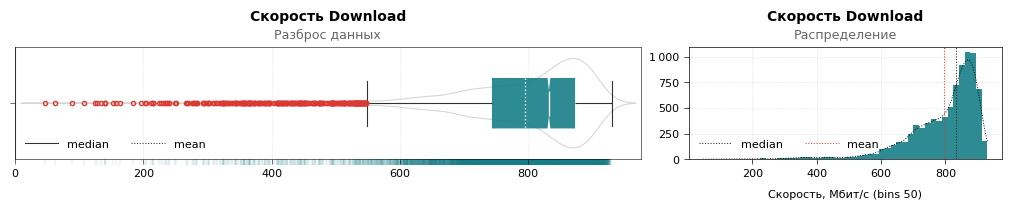

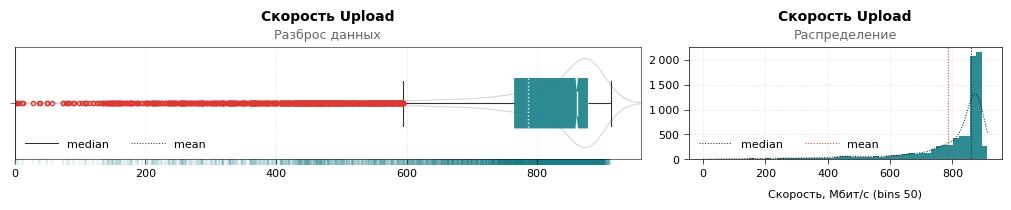

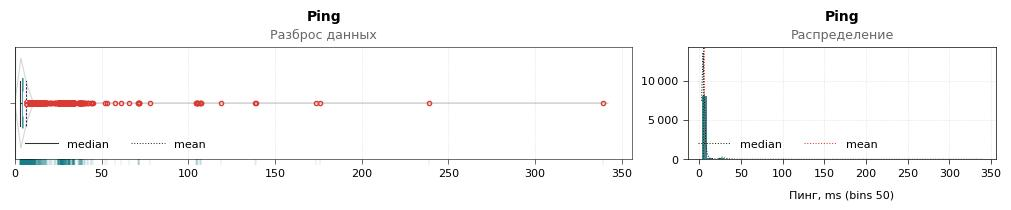

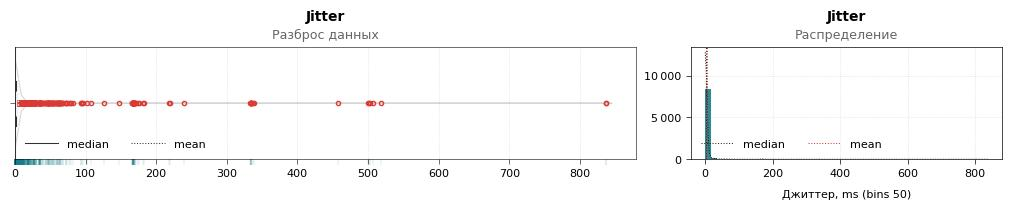

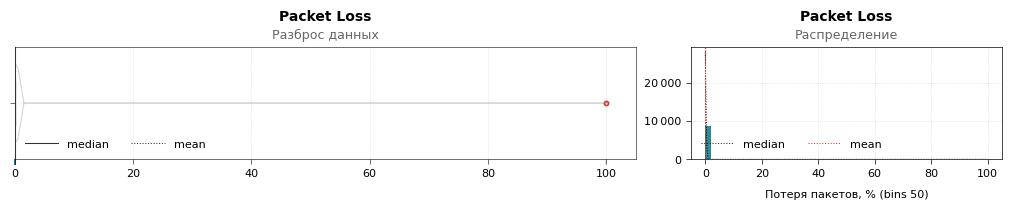

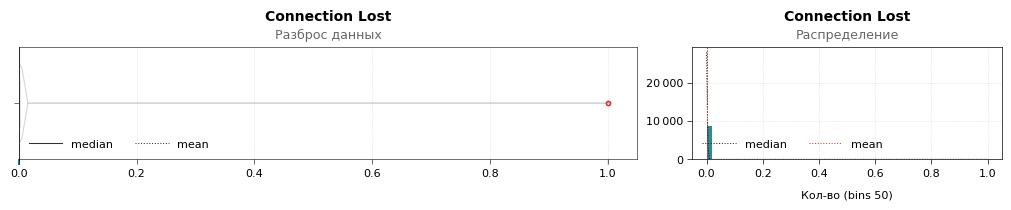

In [29]:
for m in metric_lst:
    gsubplots(
        data=[
            [{'data': df, 
             'x': m,  
             'axvline': [{'linestyle': '-', 'label': 'median', 'color': 3}, {'label': 'mean', 'color': 3}],
             'xlim': (0, None),
             'tpl': 'box_01 box_c30f lg_01h',
             'cls': '0x0 y1-n ntch ax-lws bxp:ln-a09 t-o4m t-m2.4 lg-ptm fig-n'
            }, {
             # Фильтруем лишние значения, чтобы не выходили за границы
             'data': df,
             'x': m,
             'xlabel': False,
             'tpl': 'rug_01',
             'cls': '0x0 ax-a09 ln-c0 z-1 clp-n hgt-0.05 fig-n', #ytl-ln yt-n
            }, {'data': df,
             'x': m, 
             'title': get_metric(m, 'title'),
             'suptitle': 'Разброс данных', 
             'orient':'h',
             'inner': None,
             'tpl':'viol_01 lg_01h', 
             'cls':'0x0 gr-x qntl-n t-o4m t-m2.4 ln-a02 ln-cn ln-lc3 lg-ptm z-1 fig-n'
            }, 
            ],
            {'data': df[m],
             'xlabel': get_metric(m, 'ylabel'), 
             'title': get_metric(m, 'title'),
             'suptitle': 'Распределение',
             'axvline': [{'x': df[m].median(), 'label': 'median', 'color': 14}, {'x': df[m].mean(), 'label': 'mean', 'color': 1}],
             'tpl': 'hist_01 lg_01h',
             # 'cls': '0x0 bns50 kde fig-n'
             'cls': '0x0 gr y-ths ax-lws ln-a09 t-o4m t-m2.4 bns50 kde lg-ptm fig-n', # bnsw0.15 stt-d lg-ptlw2xs ln-c1 
            },
        ],
        kinds=[['sboxplot', 'rugplot', 'sviolinplot'], 'shist'], #'sstripplot'
        frame=[1, 3],
        frame_cells=[[0, [0, 2]], [0, 2]],
        cls='10x2'
    )

Графики подтверждают наличие лево и правосторонних перекосов, и длинных хвостов с низкими и высокими значениями выбросов, влияющих на среднее.

Расчитаем выбросы

In [30]:
# Выбросы
outliers = get_outlier(df[metric_lst])

# Таблица
print_outlier_desc(df[metric_lst])

,download,upload,ping,jitter,packet_loss,connection_lost
min,46.47,0.00,2.85,0.05,0,0
max,930.82,912.61,339.34,837.32,100,1
Q1,743.33,764.64,4.14,0.70,0.00,0.00
Q3,872.93,877.71,5.01,1.28,0.00,0.00
IQR,129.60,113.07,0.87,0.58,0.00,0.00
lower_c,548.93,595.03,2.83,-0.17,0.00,0.00
upper_c,1 067.33,1 047.32,6.32,2.15,0.00,0.00
lower,549.19,595.07,2.85,0.05,0,0
upper,930.82,912.61,6.31,2.15,0,0
lower_cnt,313,967,0,0,0,0


Увеличим масштаб графиков, оставив нормальные значения расчитанного характерного разброса.

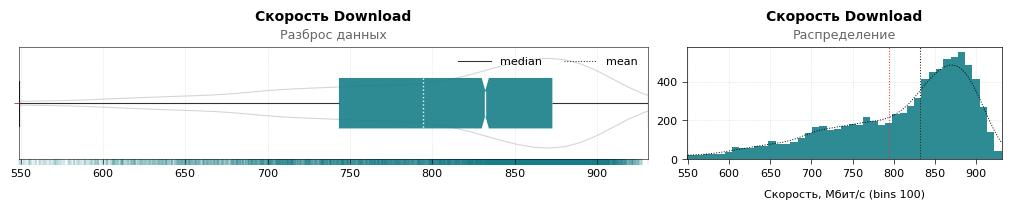

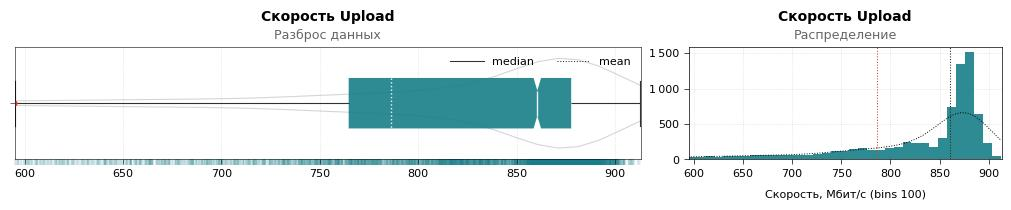

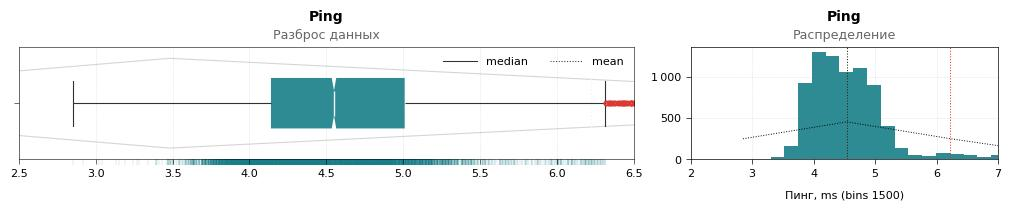

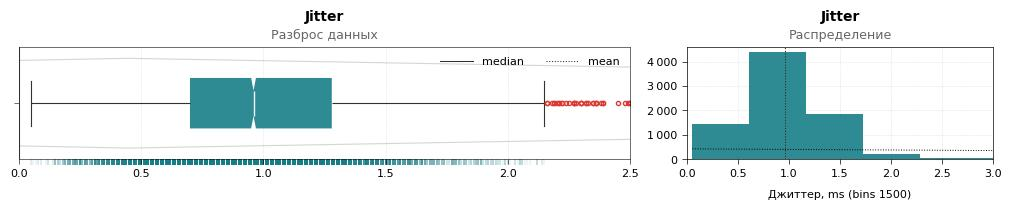

In [31]:
for i, m in enumerate(metric_lst[:-2]):
    gsubplots(
        data=[
            [{'data': df, 
             'x': m, 
             'axvline': [{'linestyle': '-', 'label': 'median', 'color': 3}, {'label': 'mean', 'color': 3}],
             'range': round_range(outliers[m]['lower'], outliers[m]['upper']),
             'xlim': (0, None),
             'tpl': 'box_01 box_c30f lg_01h',
             'cls': '0x0 y1-n ntch bxp:ln-a09 ax-lws t-o4m t-m2.4 lg-ptm fig-n'
            }, {
             # Фильтруем лишние значения, чтобы не выходили за границы
             'data': df[m][df[m].between(outliers[m]['lower'], outliers[m]['upper'])],
             'xlabel': False,
             # 'range': round_range(outliers[m]['lower'], outliers[m]['upper']),
             'tpl': 'rug_01',
             'cls': '0x0 ax-a09 ln-c0 z-1 clp-n hgt-0.05 fig-n', #ytl-ln yt-n
            }, {'data': df,
             'x': m, 
             'title': get_metric(m, 'title'),
             'suptitle': 'Разброс данных', 
             'orient':'h',
             'inner': None,
             'range': round_range(outliers[m]['lower'], outliers[m]['upper']),
             'tpl':'viol_01 lg_n',
             'cls':'0x0 gr-x qntl-n t-o4m t-m2.4 ln-a02 ln-cn ln-lc3 lg-ptm z-1 fig-n'
            }],
            {'data': df[m],
             # 'columns': 'ping', 
             'bins': 1500 if i > 1 else 100,
             'title': get_metric(m, 'title'),
             'suptitle': 'Распределение',
             'xlabel': get_metric(m, 'ylabel'), 
             'range': round_range(outliers[m]['lower'], outliers[m]['upper'], 0), 
             'axvline': [{'x': df[m].median(), 'label': 'median', 'color': 14}, {'x': df[m].mean(), 'label': 'mean', 'color': 1}],
             'tpl': 'hist_01 lg_n',
             # '0x0 bns50 bns1500 kde'
             'cls': '0x0 gr y-ths ax-lws ln-a09 t-o4m t-m2.4 lg-n kde fig-n', # bnsw0.15 stt-d lg-ptlw2xs ln-c1
            },
        ],
        kinds=[['sboxplot', 'rugplot', 'sviolinplot'], 'shist'],
        frame=[1, 3],
        frame_cells=[[0, [0, 2]], [0, 2]],
        cls='10x2'
    )

    metric_distr = get_distr_param(clean_outliers(df, column=m, outliers=outliers)[m])
    
    display_grid(
        [
        print_to(f'Большая часть значений лежит в диапазоне {outliers[m]['Q1']}-{outliers[m]['Q3']}. Нижний ус упирается в значение {outliers[m]['lower']}. Верхний около {outliers[m]['upper']}. Это граница нормального размаха. Все что выше, ниже — выбросы. Выбросов много, но медиана не стремиться к хвосту значений выбросов. Выбросы подтверждают высокое среднее отклонение.', to_html=True),
        print_to(f'Распределение {'нормальное' if metric_distr['is_normal'] else 'не нормальное'}. Тип распределения {', '.join(metric_distr['distr_type'])}. Чаще всего встречаются значения {round(df[m].mode()[0])} ms.', to_html=True)
        ],
        grid=[1,2],
        vspace=35
    )

Изучим детальнее выбросы метрик и избавимся от них.

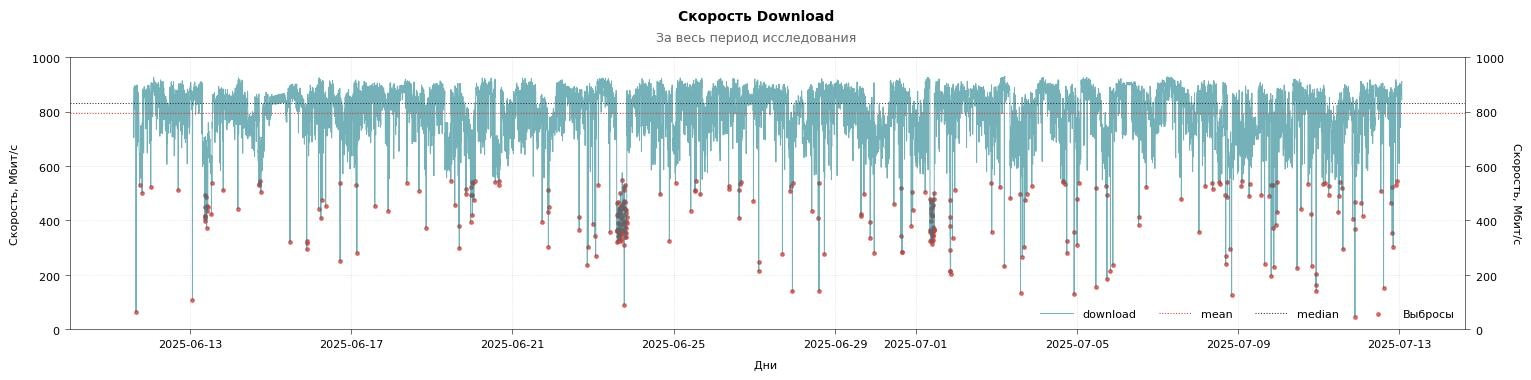

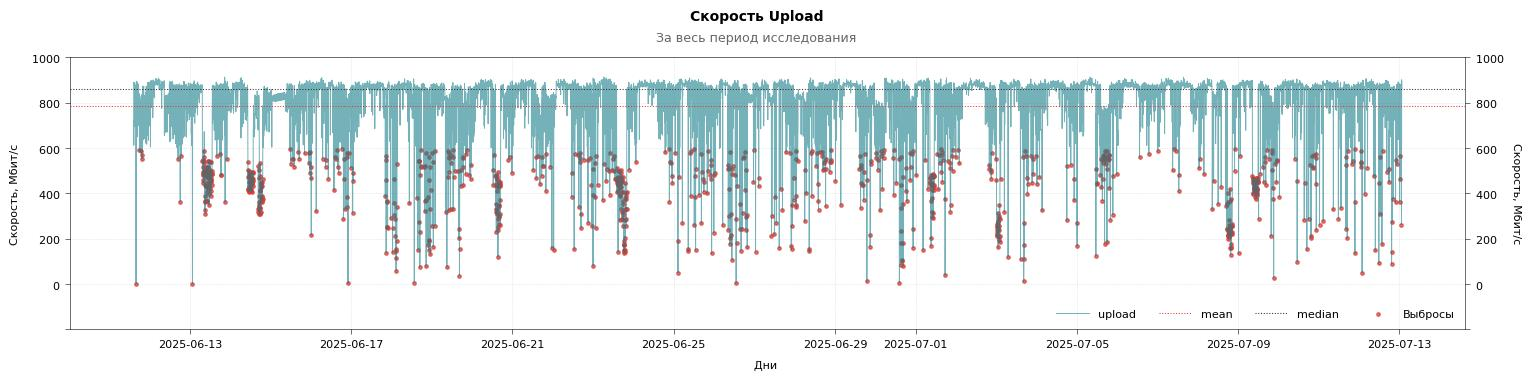

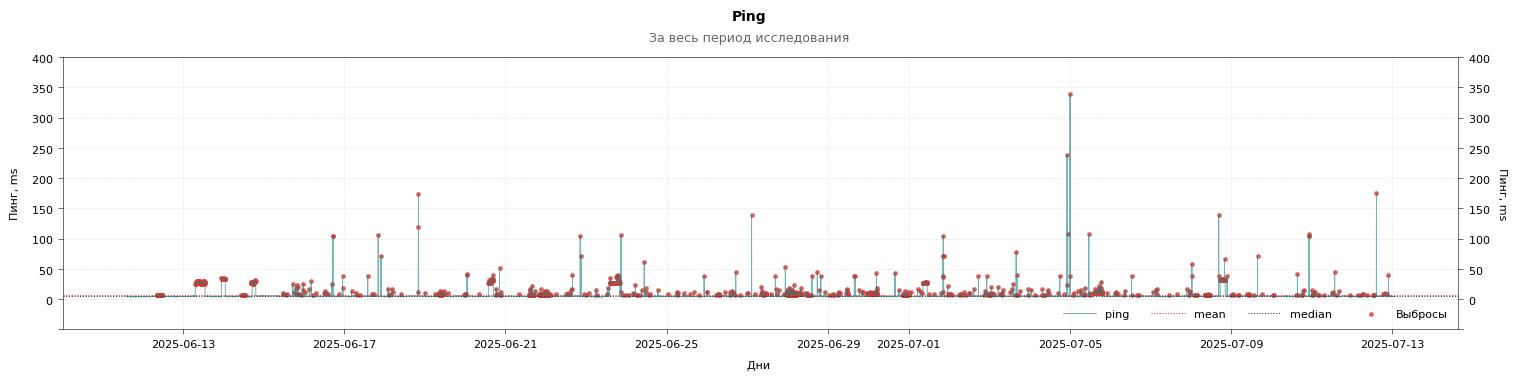

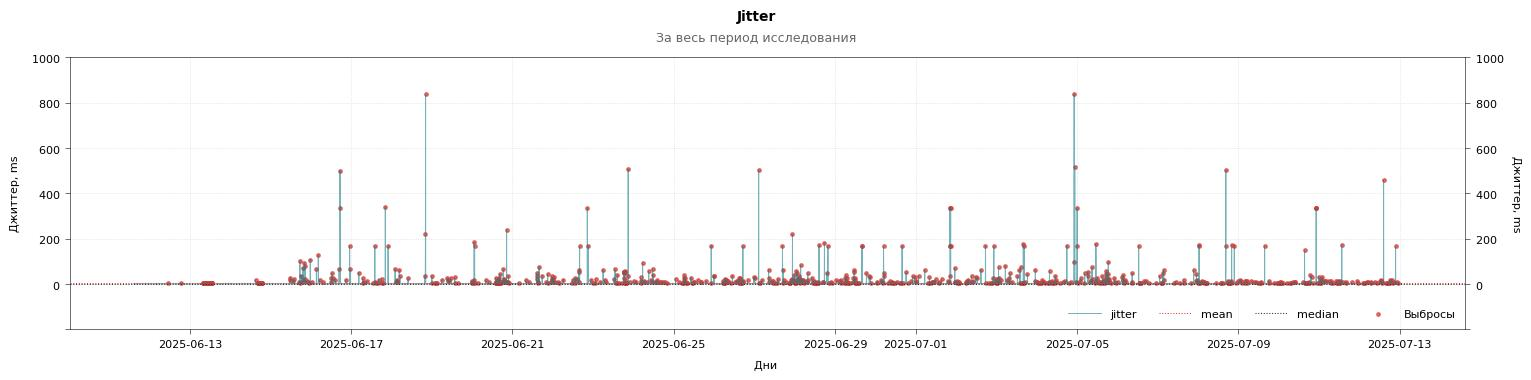

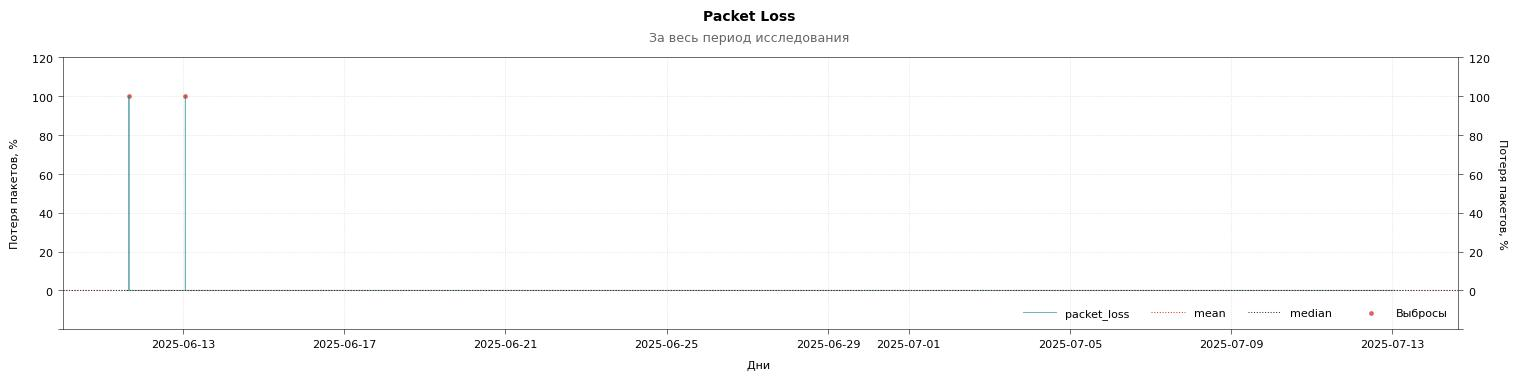

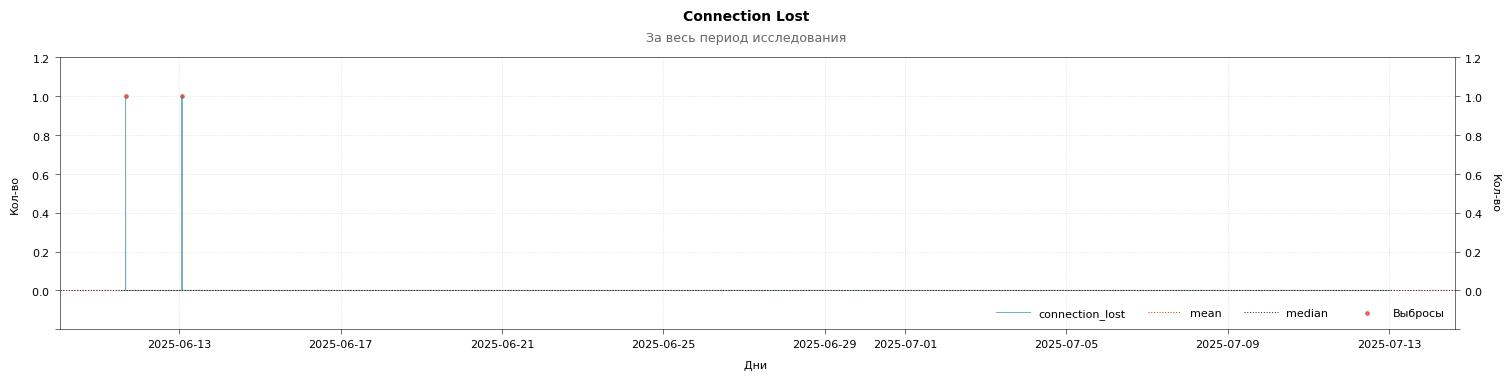

In [32]:
# Визуализация
for m in metric_lst:
    ax = plot(
        df, 
        y=m, 
        x='timestamp',
        xlabel='Дни', 
        ylabel=get_metric(m, 'ylabel'), 
        axhline=[{'y': df[m].mean(), 'label': 'mean', 'color': 1}, {'y': df[m].median(), 'label': 'median', 'color': 3}],
        cls='ln-a06 ln-s x-date y-ths hln-xs fig-n', 
    )
    scatter(
        df.loc[outliers[m]['outlier_mask']['is_outlier']][[m, 'timestamp']], 
        x='timestamp', 
        y=m, 
        ax=ax,
        suptitle='За весь период исследования', 
        title=get_metric(m, 'title'),
        xlabel='Дни', 
        ylabel=get_metric(m, 'ylabel'), 
        label='Выбросы', 
        tpl='plot_01a lg_01g',
        cls='18x4 gr ytl-0 y-sci t-on ln-s6 ln-c1 ln-a07 lg-ptm',
    )

Изучим выбросы скорости с показателями менее 100 Мбит/с

In [33]:
df.query('download < 100')

,timestamp,ping,jitter,download,upload,packet_loss,connection_lost,connection_recovered,connection_error,server_id,server_name,server_city,server_sponsor,server_host,server_distance,day,month,year,day_name,day_name_abbr,weekday,is_weekend,hour
16,2025-06-11 15:57:05,3.81,0.85,63.08,0.00,100,1,False,Unknown,25330,Ekaterinburg,Ekaterinburg,TTK Ural,speedtest.uralttk.ru:8080,4.36,11,6,2025,Среда,ср,2,0,15
3366,2025-06-23 18:34:57,36.96,26.39,89.47,149.71,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,18
8356,2025-07-11 21:29:31,4.47,0.65,46.47,134.94,0,0,False,Ok,69510,Ekaterinburg,Ekaterinburg,Beeline Mobile,speedtest.ekaterinburg.gldn.net:8080,4.36,11,7,2025,Пятница,пт,4,0,21


Одно значение это аномалия связанная с разрывом соединения. Нас интересует аномалия связаная с сервером находящимся в Москве на расстоянии 1419 км. Выведем показатели скорости данного сервера.

In [34]:
df.query('server_id == 23499')

,timestamp,ping,jitter,download,upload,packet_loss,connection_lost,connection_recovered,connection_error,server_id,server_name,server_city,server_sponsor,server_host,server_distance,day,month,year,day_name,day_name_abbr,weekday,is_weekend,hour
3349,2025-06-23 17:05:16,26.98,2.70,404.45,407.31,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,17
3350,2025-06-23 17:10:32,26.47,1.15,455.20,316.56,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,17
3351,2025-06-23 17:15:48,26.81,0.75,547.68,454.91,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,17
3352,2025-06-23 17:21:01,26.63,0.88,575.64,285.40,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,17
3353,2025-06-23 17:26:16,26.58,0.69,451.66,285.62,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,17
3354,2025-06-23 17:31:32,26.74,1.30,420.96,351.43,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,17
3355,2025-06-23 17:36:48,26.60,1.66,388.98,407.67,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,17
3356,2025-06-23 17:42:05,26.18,0.71,444.84,470.75,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,17
3357,2025-06-23 17:47:19,26.69,0.82,361.80,317.17,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,17
3358,2025-06-23 17:52:37,26.77,1.37,445.92,302.06,0,0,False,Ok,23499,Moscow,Moscow,Марьино.net,speedtest.maryno.net:8080,1419.61,23,6,2025,Понедельник,пн,0,0,17


В выбросы попали почти все показатели данного сервера, т.к. глобальные выбросы не учитывают различия между серверами. Однако низкие показатели скорости могут быть связаны с большим расстоянием до сервера, и это нужно учитывать. Сгруппируем данные по серверам и расчитаем по ним выбросы

In [35]:
gr_outliers = get_outlier_param(df[metric_lst + ['server_id']], gr_column='server_id', is_gr_combine=True, param='outlier_mask')
print_outlier_desc(df[metric_lst + ['server_id']], gr_column='server_id')

,download,upload,ping,jitter,packet_loss,connection_lost
group_cnt,23,23,23,23,23,23
lower_cnt,384,942,67,0,0,0
upper_cnt,4,8,734,692,2,2
lower_share,4.4%,10.9%,0.8%,0.0%,0.0%,0.0%
upper_share,0.0%,0.1%,8.5%,8.0%,0.0%,0.0%


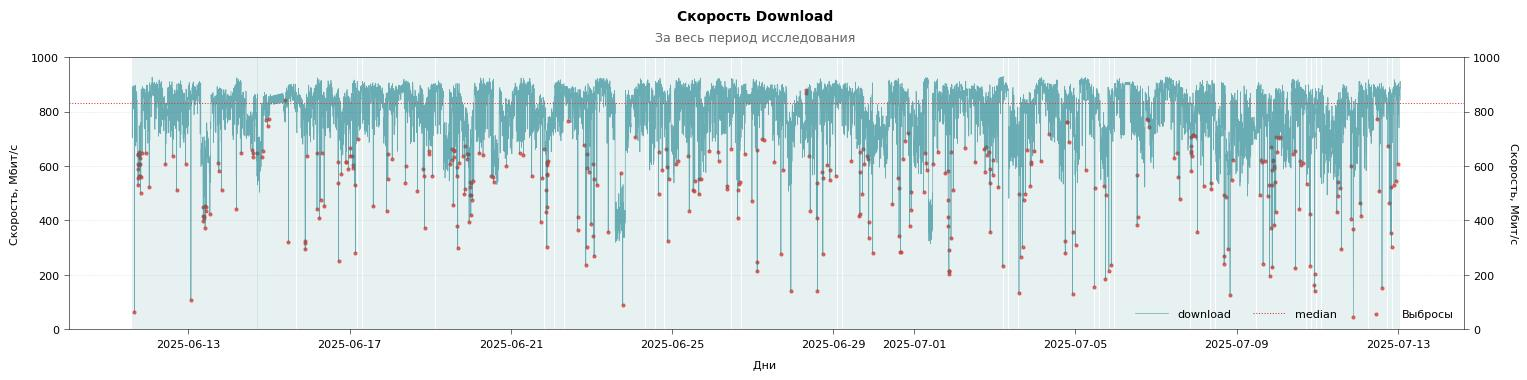

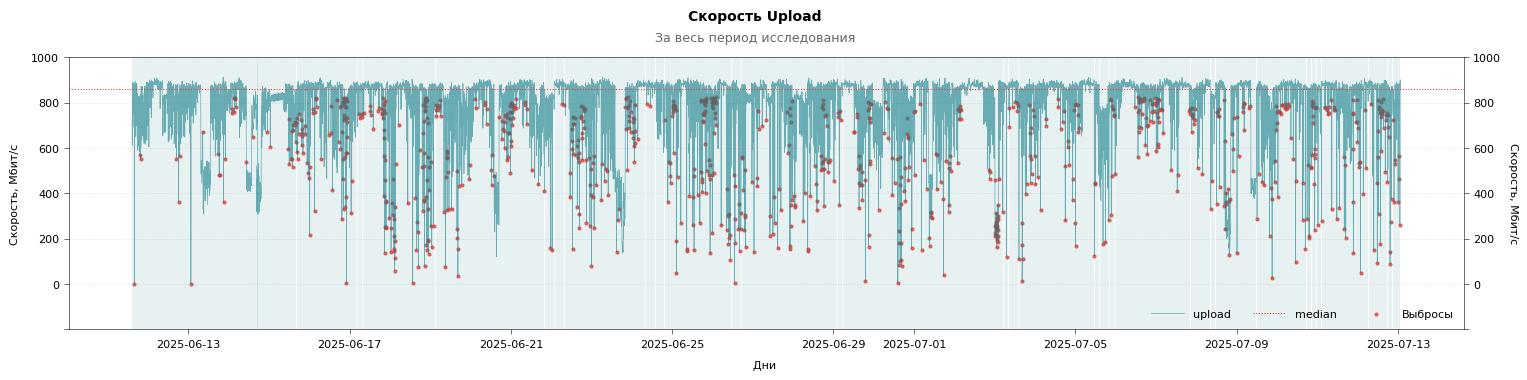

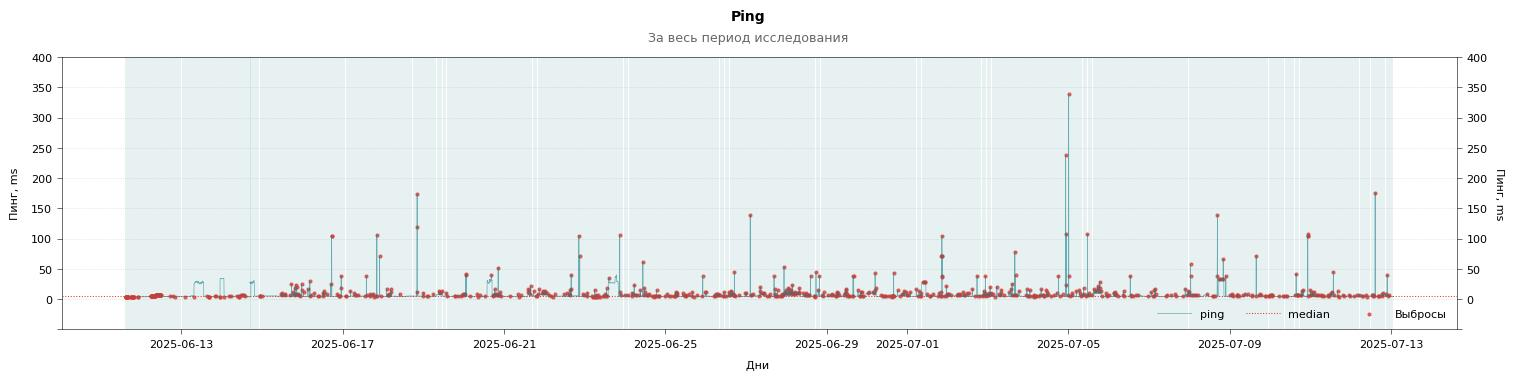

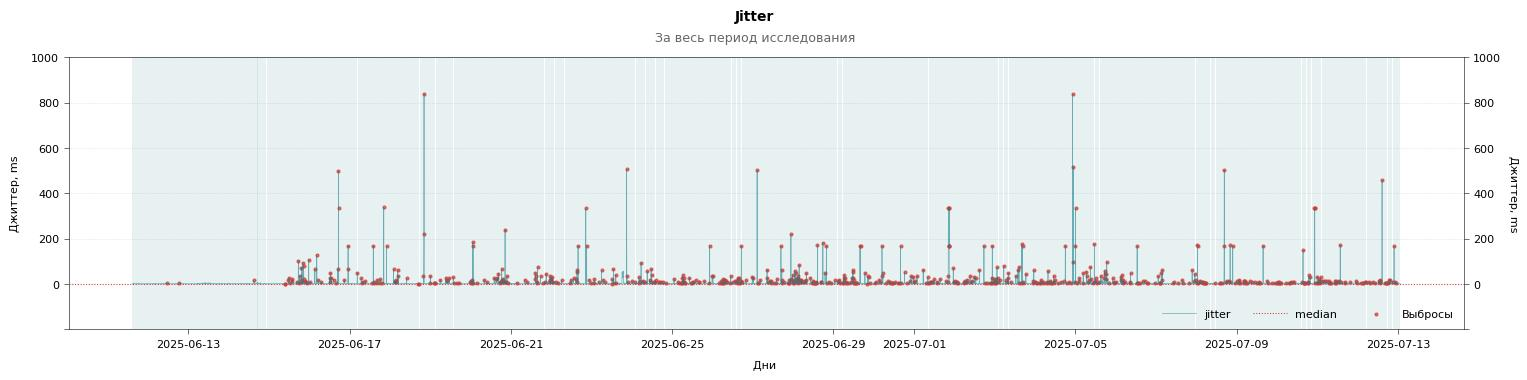

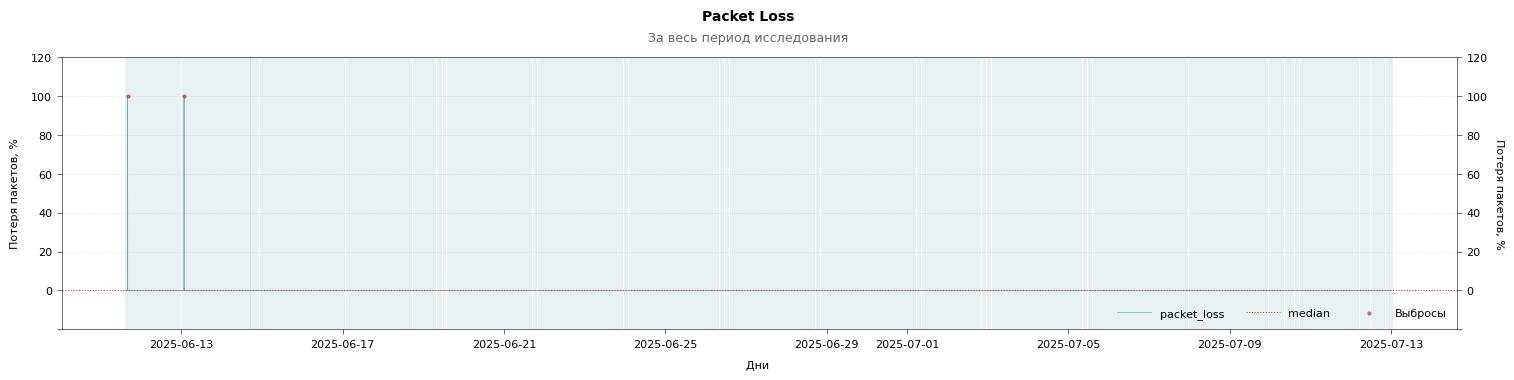

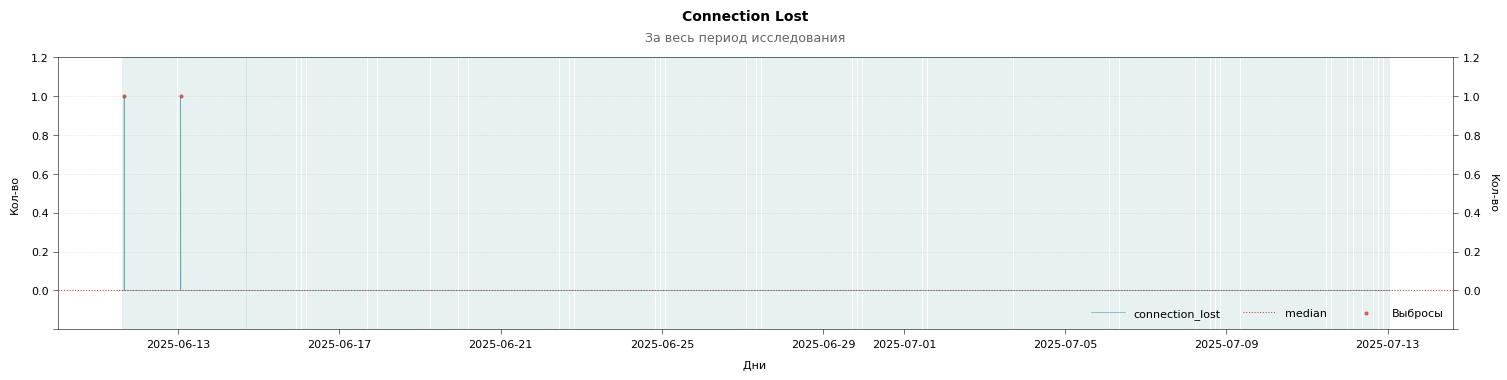

In [36]:
for m in metric_lst:
    ax=plot(
        df,
        x='timestamp',
        y=m,
        xlabel='Дата', 
        ylabel=get_metric(m, 'ylabel'), 
        axhline={'y': df[m].median(), 'label': 'median'},
        axvgroup={'group': 'server_id', 'ts': 'timestamp'},
        # tpl='plot_01a',
        cls='x-date ln-2xs ln-a06 hln-c1 hln-m vg-tf vg-cw vg-fc0 vg-fa01 fig-n'
    )
    scatter(
        df.loc[gr_outliers[m]['is_outlier']][[m, 'timestamp']], 
        x='timestamp', 
        y=m, 
        ax=ax,
        title=get_metric(m, 'title'),
        suptitle='За весь период исследования', 
        xlabel='Дни', 
        ylabel=get_metric(m, 'ylabel'), 
        label='Выбросы', 
        tpl='plot_01a lg_01g',
        cls='18x4 ytl-0 t-on ln-s4 ln-c1 ln-a07 lg-ptm',
    )

Хорошо. Но в выбросы попадают «хорошие» данные. Добавим пороговые значения из глобальных выбросов

In [37]:
gr_outliers_fix = get_outlier_param(df[metric_lst + ['server_id']], gr_column='server_id', is_gr_combine=True, param='outlier_mask', upper_threshold=get_nested_value(outliers, 'upper'), lower_threshold=get_nested_value(outliers, 'lower'))
print_outlier_desc(df[metric_lst + ['server_id']], gr_column='server_id', upper_threshold=get_nested_value(outliers, 'upper'), lower_threshold=get_nested_value(outliers, 'lower'))

,download,upload,ping,jitter,packet_loss,connection_lost
group_cnt,23,23,23,23,23,23
lower_cnt,185,480,0,0,0,0
upper_cnt,0,0,461,672,2,2
lower_share,2.1%,5.5%,0.0%,0.0%,0.0%,0.0%
upper_share,0.0%,0.0%,5.3%,7.8%,0.0%,0.0%


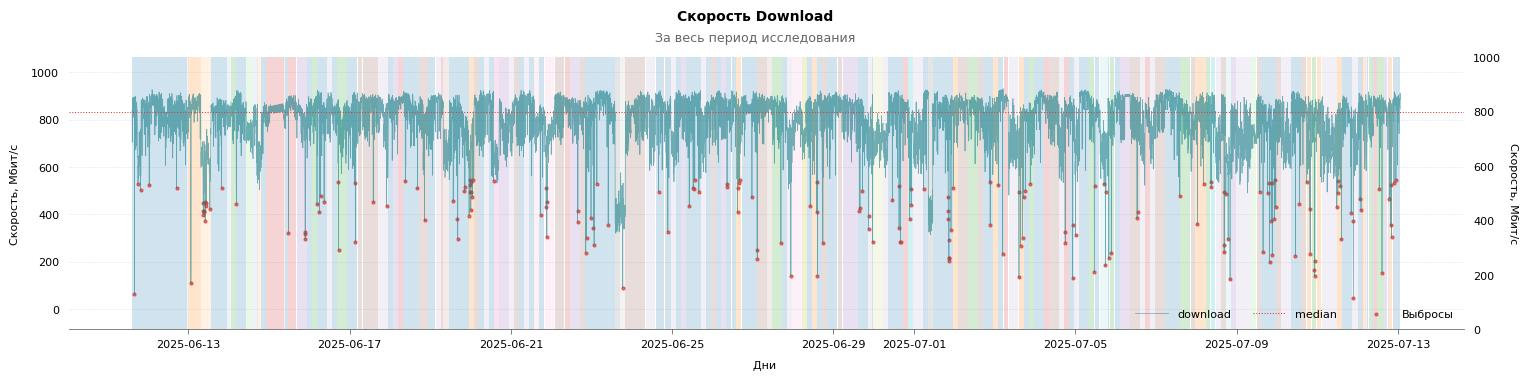

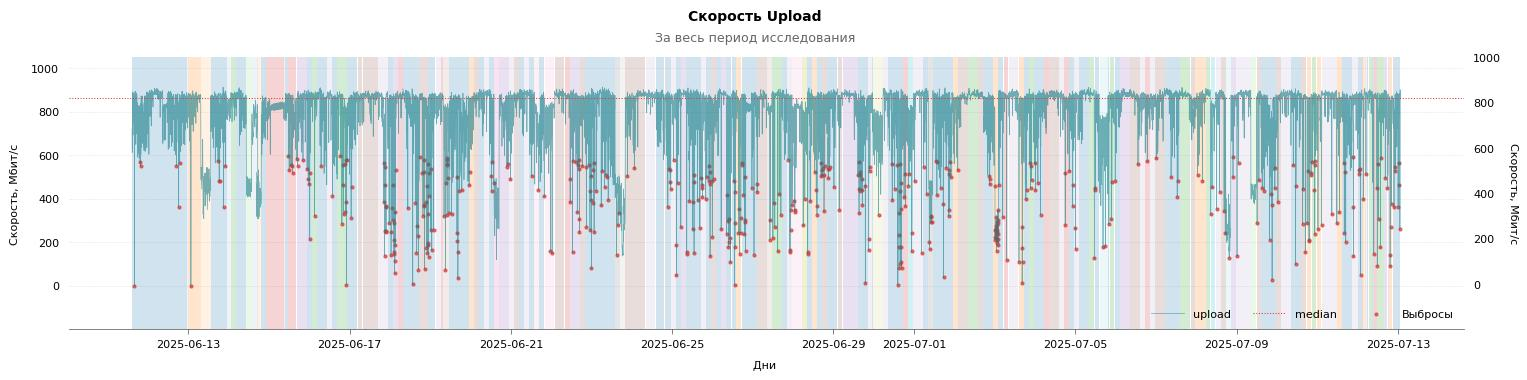

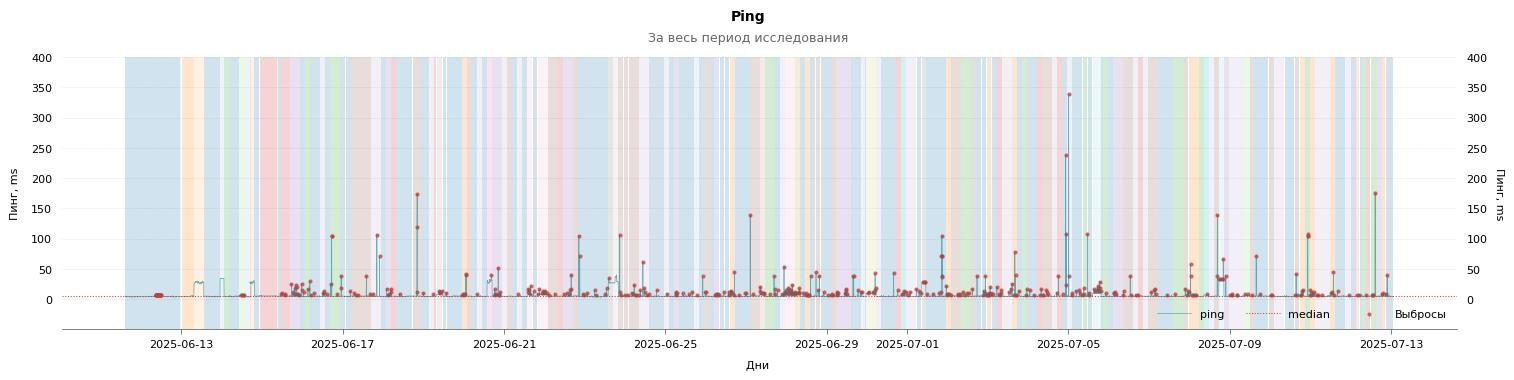

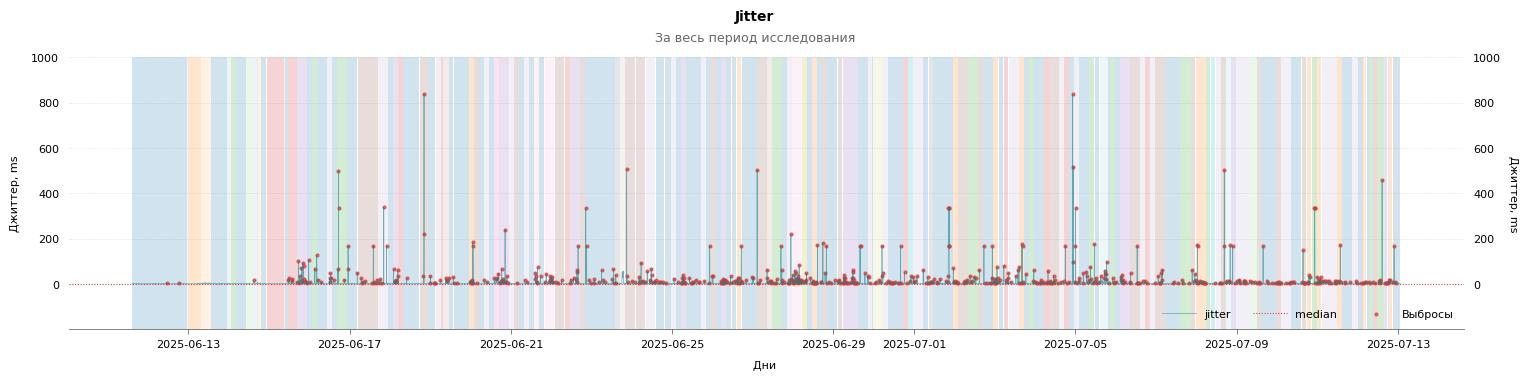

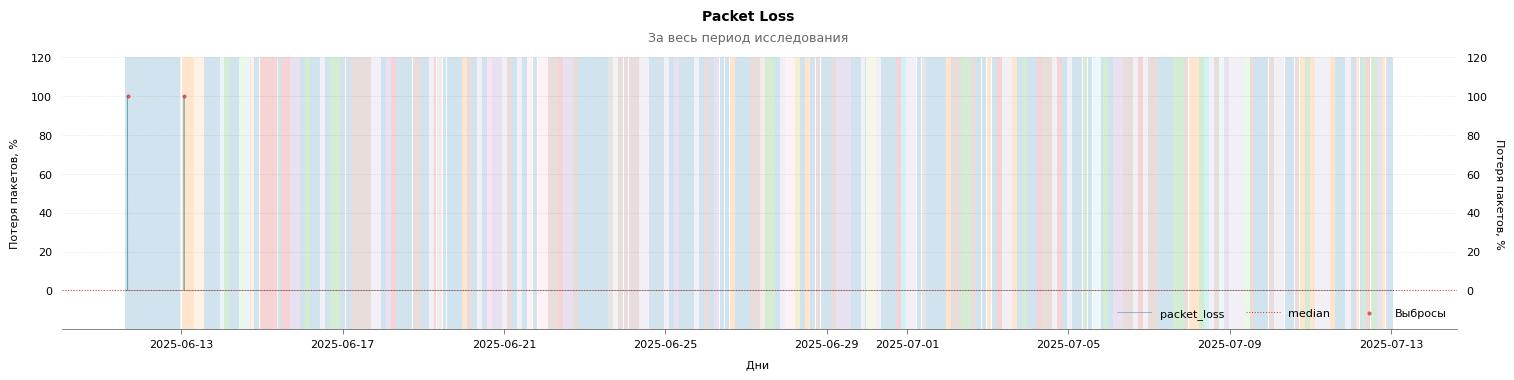

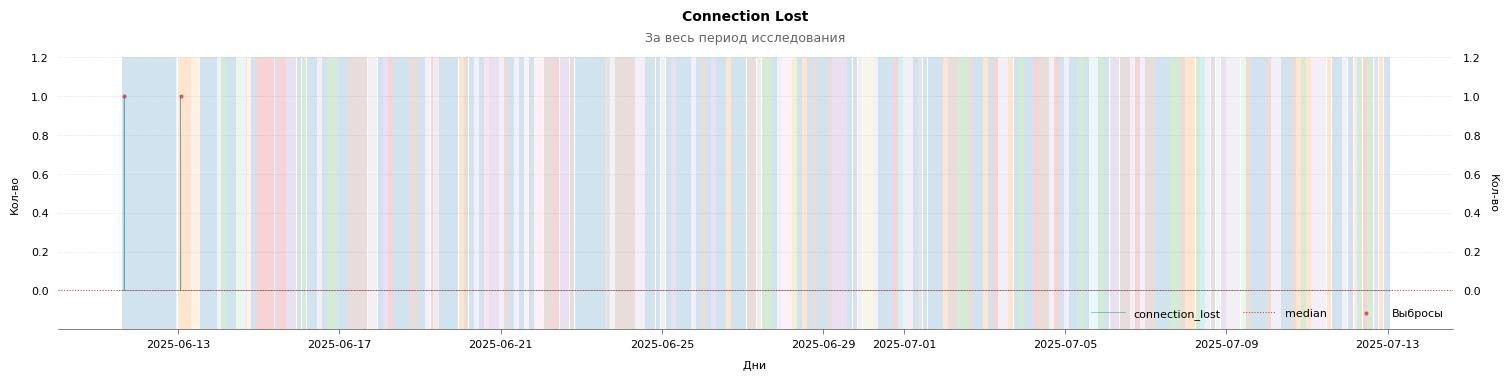

In [38]:
for m in metric_lst:
    ax = plot(
        df,
        x='timestamp',
        y=m,
        xlabel='Дата', 
        ylabel=get_metric(m, 'ylabel'), 
        axhline={'y': df[m].median(), 'label': 'median'},
        axvgroup={'group': 'server_id', 'ts': 'timestamp'},
        cls='18x4 ytl-0 ymg-15 x-date t-on ln-2xs ln-a06 hln-c1 vg-tc vg-cw vg-fc0 vg-fa02 fig-n',
    )
    scatter(
        df.loc[gr_outliers_fix[m]['is_outlier']][[m, 'timestamp']], 
        x='timestamp', 
        y=m, 
        ax=ax,
        title=get_metric(m, 'title'),
        suptitle='За весь период исследования', 
        xlabel='Дни', 
        ylabel=get_metric(m, 'ylabel'), 
        label='Выбросы', 
        tpl='plot_02a lg_01g',
        cls='18x4 ytl-0 t-on ln-s4 ln-c1 ln-a07 lg-ptm',
    )

Визуализируем очищенные данные.

Глобальные выбросы

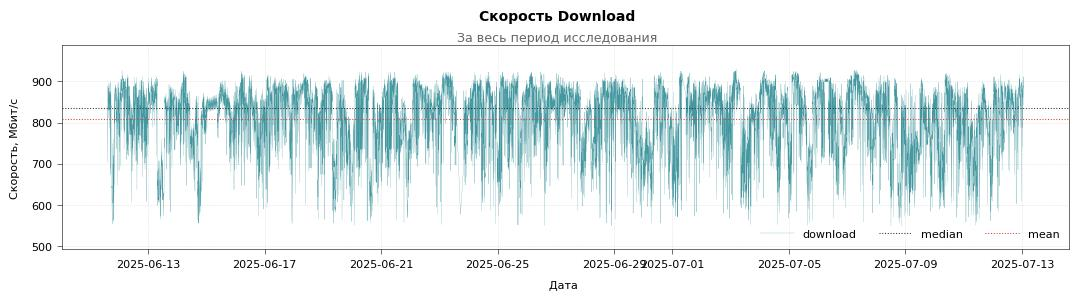

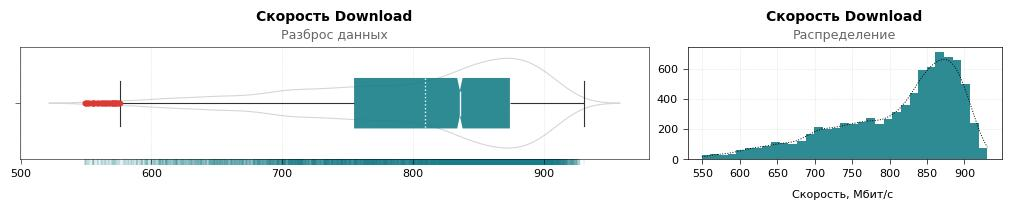

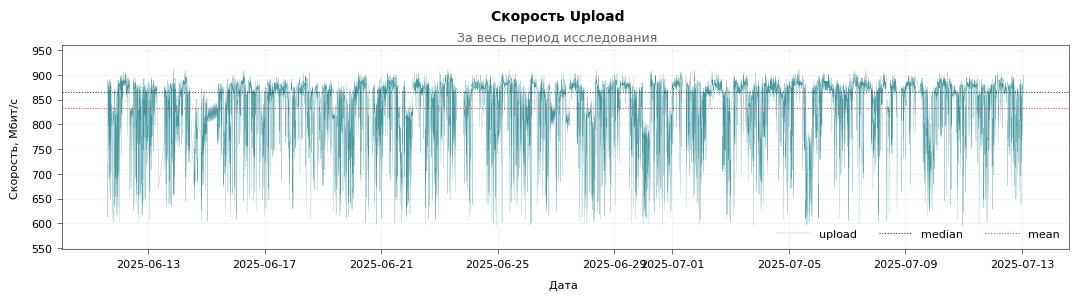

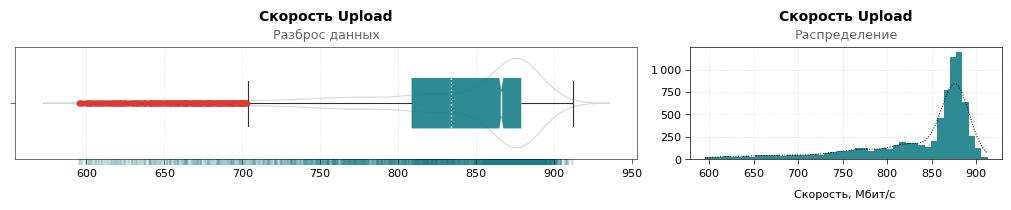

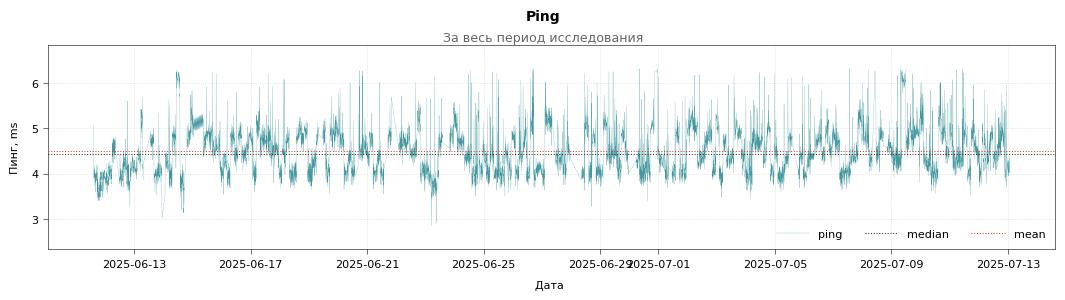

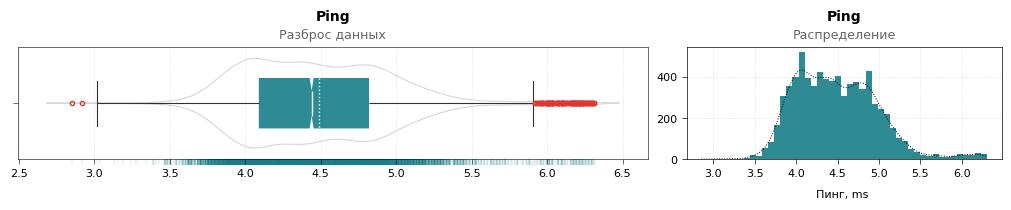

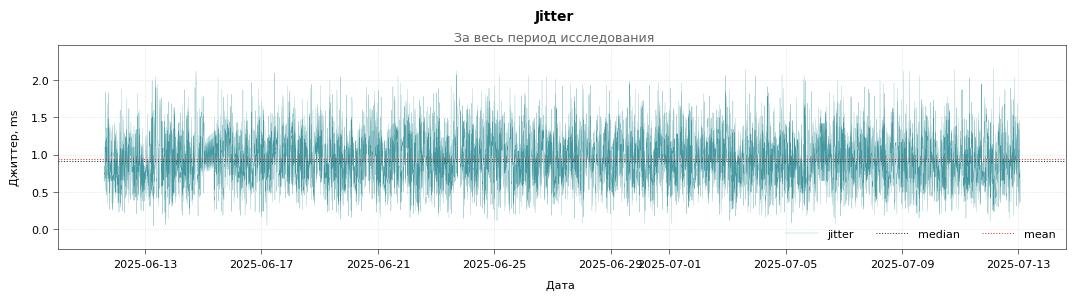

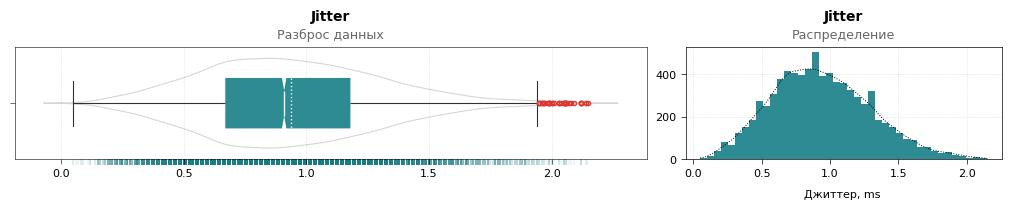

In [39]:
for i, m in enumerate(metric_lst[:-2]):
    df_cleaned = clean_outliers(df, column=m, outliers=outliers)
    ax = plot(
        df_cleaned,
        x='timestamp',
        y=m,
        xlabel='Дата', 
        ylabel=get_metric(m, 'ylabel'), 
        title=get_metric(m, 'title'),
        suptitle='За весь период исследования', 
        axhline=[{'y': df_cleaned[m].median(), 'label': 'median', 'color': 3}, {'y': df_cleaned[m].mean(), 'label': 'mean', 'color': 1}],
        # tpl='plot_02a',
        tpl='plot_01 lg_01g',
        cls='13x3 gr ytl-0 ymg-15 x-date t-on ln-5xs ln-a08 hln-c1 vg-tf vg-cw vg-fc0 vg-fa01 lg-ptm',
    )
    
    gsubplots(
        data=[
            [{'data': df_cleaned, 
             'x': m, 
             'tpl': 'box_01 box_c30f lg_01h',
             'cls': '0x0 y1-n ntch ax-lws bxp:ln-a09 t-o4m t-m2.4 lg-ptm fig-n'
            }, {
             # Фильтруем лишние значения, чтобы не выходили за границы
             'data': df_cleaned[m],
             'xlabel': False,
             # 'range': round_range(outliers[m]['lower'], outliers[m]['upper']),
             'tpl': 'rug_01',
             'cls': '0x0 ax-a09 ln-c0 z-1 clp-n hgt-0.05 fig-n', #ytl-ln yt-n
            }, {'data': df_cleaned,
             'x': m, 
             'title': get_metric(m, 'title'),
             'suptitle': 'Разброс данных', 
             'orient':'h',
             'inner': None,
             'tpl':'viol_01',
             'cls':'0x0 gr-x qntl-n t-o4m t-m2.4 ln-a02 ln-cn ln-lc3 lg-ptm z-1 fig-n'
            }],
            {'data': df_cleaned[m],
             # 'bins': 100 if i > 1 else 100,
             'title': get_metric(m, 'title'),
             'suptitle': 'Распределение',
             'xlabel': get_metric(m, 'ylabel'), 
             'tpl': 'hist_01 lg_n',
             # '0x0 bns50 bns1500 kde'
             'cls': '0x0 gr y-ths ax-lws ln-a09 t-o4m t-m2.4 lg-n kde fig-n',
            },
        ],
        kinds=[['sboxplot', 'rugplot', 'sviolinplot'], 'shist'],
        frame=[1, 3],
        frame_cells=[[0, [0, 2]], [0, 2]],
        cls='10x2'
    )

Выбросы с учетом серверов

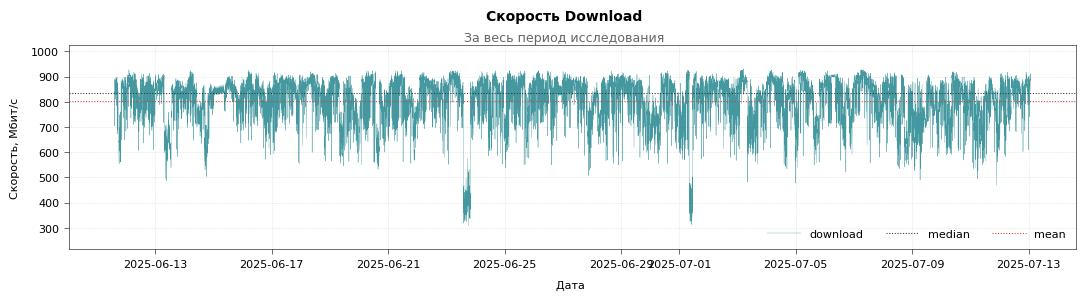

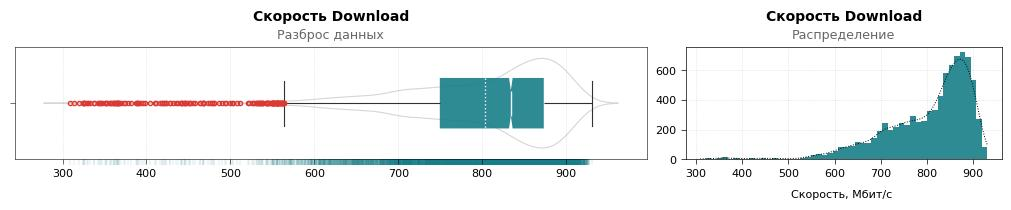

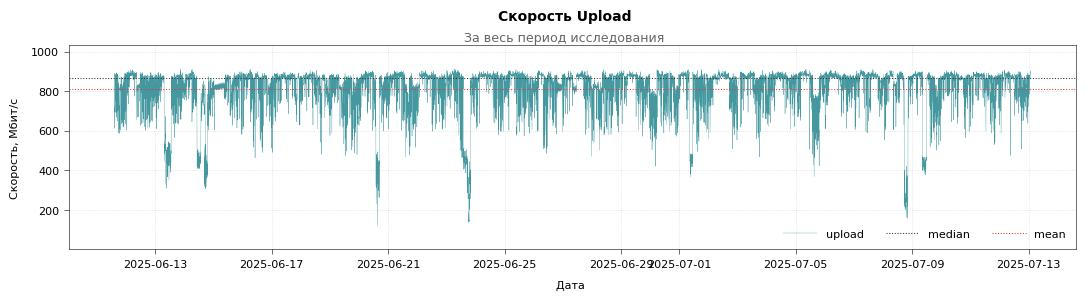

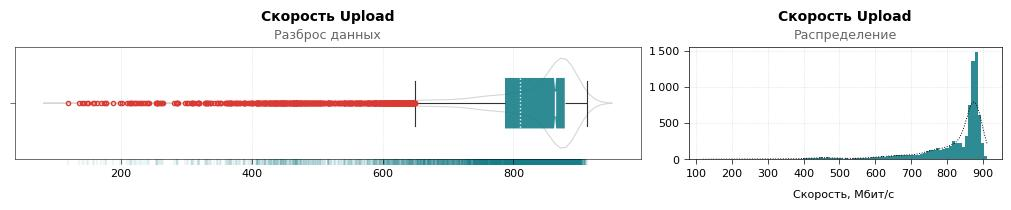

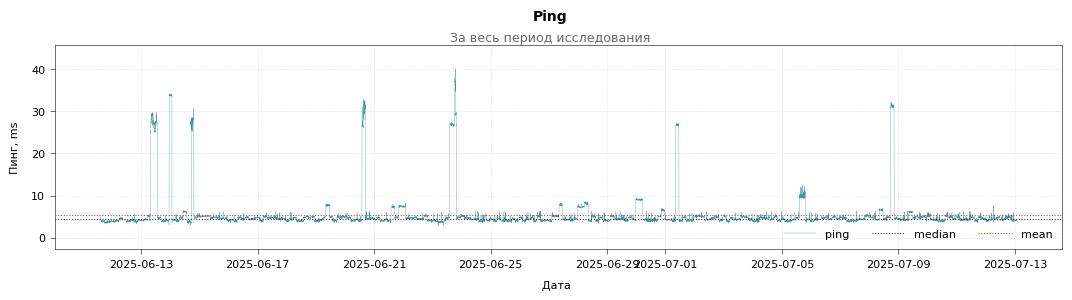

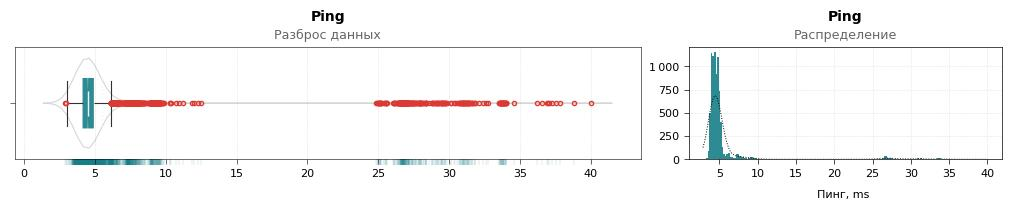

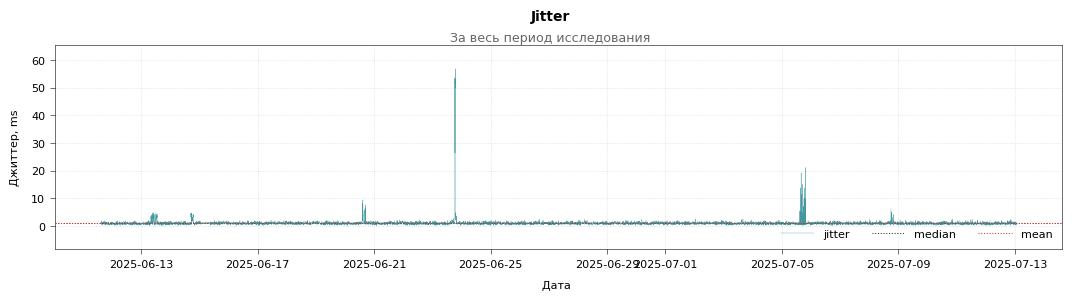

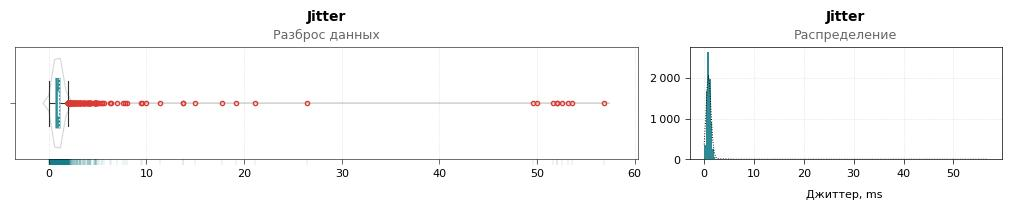

In [40]:
for i, m in enumerate(metric_lst[:-2]):
    df_cleaned = clean_outliers(df, mask=gr_outliers_fix[m])
    ax = plot(
        df_cleaned,
        x='timestamp',
        y=m,
        xlabel='Дата', 
        ylabel=get_metric(m, 'ylabel'), 
        title=get_metric(m, 'title'),
        suptitle='За весь период исследования', 
        axhline=[{'y': df_cleaned[m].median(), 'label': 'median', 'color': 3}, {'y': df_cleaned[m].mean(), 'label': 'mean', 'color': 1}],
        tpl='plot_01 lg_01g',
        cls='13x3 gr ytl-0 ymg-15 x-date t-on ln-4xs ln-a08 hln-c1 vg-tf vg-cw vg-fc0 vg-fa01 lg-ptm',
    )
    
    gsubplots(
        data=[
            [{'data': df_cleaned, 
             'x': m, 
             'tpl': 'box_01 box_c30f lg_01h',
             'cls': '0x0 y1-n ntch ax-lws bxp:ln-a09 t-o4m t-m2.4 lg-ptm fig-n'
            }, {
             # Фильтруем лишние значения, чтобы не выходили за границы
             'data': df_cleaned[m],
             'xlabel': False,
             # 'range': round_range(outliers[m]['lower'], outliers[m]['upper']),
             'tpl': 'rug_01',
             'cls': '0x0 ax-a09 ln-c0 z-1 clp-n hgt-0.05 fig-n', #ytl-ln yt-n
            }, {'data': df_cleaned,
             'x': m,  
             'title': get_metric(m, 'title'),
             'suptitle': 'Разброс данных', 
             'orient':'h',
             'inner': None,
             'tpl':'viol_01',
             'cls':'0x0 gr-x qntl-n t-o4m t-m2.4 ln-a02 ln-cn ln-lc3 lg-ptm z-1 fig-n'
            }],
            {'data': df_cleaned[m],
             # 'bins': 100 if i > 1 else 100,
             'title': get_metric(m, 'title'),
             'suptitle': 'Распределение',
             'xlabel': get_metric(m, 'ylabel'), 
             'tpl': 'hist_01 lg_n',
             # '0x0 bns50 bns1500 kde'
             'cls': '0x0 gr y-ths ax-lws ln-a09 t-o4m t-m2.4 lg-n kde fig-n', # bnsw0.15 stt-d lg-ptlw2xs ln-c1
            },
        ],
        kinds=[['sboxplot', 'rugplot', 'sviolinplot'], 'shist'],
        frame=[1, 3],
        frame_cells=[[0, [0, 2]], [0, 2]],
        cls='10x2'
    )

#### Выводы

- Столбцы `ping`, `jitter`, `download`, `upload` содержат аномалии и выбросы.
- Расчитали глобальные выбросы и выбросы с учетом серверов.
- Создали маски для очистки выборки от выбросов.

### 3.6. Категоризация данных<a id="p36"></a>

Добавим категории времени суток:

- `с 22:00 по 4:59` — Ночь
- `с 5:00 по 11:59` — Утро
- `с 12:00 по 16:59` – День
- `с 17:00 по 21:59` — Вечер.

In [41]:
extract_time_period_features(df, col_name='timestamp')
print_rows(df, 2, ['timestamp', 'time_period', 'time_period_num'])

,timestamp,time_period,time_period_num
0,2025-06-11 14:32:24,День,3
1,2025-06-11 14:37:55,День,3


Добавим оценки метрик скорости, задержки и стабильности:

1. Оценки скорости:
   - `<50` – Плохо 
   - `50–200` – Неудовлетворительно
   - `200–300` – Удовлетворительно
   - `300–500` – Хорошо
   - `500–800` – Отлично
   - `800–1000` – Идеально
   - `>1000` – Супер

2. Оценки задержек (пинг):
   - `<2 ms` – Супер
   - `2-10 ms` – Идеально
   - `10–25 ms` – Отлично
   - `25–50 ms` – Хорошо
   - `50–90 ms` – Удовлетворительно
   - `90–150 ms` – Неудовлетворительно
   - `>150 ms` – Плохо

3. Оценки джиттера (колебаний пинга):
   - `<1 ms` – Супер
   - `1-3 ms` – Идеально
   - `3-5 ms` – Отлично
   - `5-10 ms` – Хорошо
   - `10–20 ms` – Удовлетворительно
   - `20–50 ms` – Неудовлетворительно
   - `> 50 ms` – Плохо

4. Оценки потери пакетов (Packet Loss):
    - `0%` – Идеально
    - `0-0.5%` – Отлично
    - `0.5-1%` – Хорошо
    - `1–2%` – Удовлетворительно
    - `2-5%` – Плохо
    - `5-10%` – Критично
    - `>10%` – Неприемлемо

5. Оценки частоты обрывов за 24 часа (Disconnects):
    - `0` – Идеально
    - `1-2` – Отлично
    - `2-3` – Хорошо
    - `3–5` – Удовлетворительно
    - `5-8` – Неудовлетворительно
    - `8-15` – Плохо
    - `>15` – Критично

In [42]:
_rating_data = {
    'speed': {
        50: { # < 50
           'id': 1,
           'name': 'Плохо',
           'desc': 'Минимальная скорость. Базовый сёрфинг, 1–3 устройства, возможны лаги'
        },
        200: { # 50–200
           'id': 2,
           'name': 'Неудовлетворительно',
           'desc': 'Базовая, низкая скорость. Онлайн-игры, 3–7 устройств' 
        },
        300: { # 200–300
           'id': 3,
           'name': 'Удовлетворительно',
           'desc': 'Средняя скорость. Комфортный 4K-стриминг, 10–15 устройств' 
        },
        500: { # 300–500
           'id': 4,
           'name': 'Хорошо',
           'desc': 'Комфортная, быстрая скорость.  Стабильный 4K/60FPS, 20+ устройств, быстрая загрузка файлов больших объемов' 
        },
        800: { # 500–800
           'id': 5,
           'name': 'Отлично',
           'desc': 'Очень быстрая скорость. 8K-стриминг, онлайн-игры на максималках, резервное копирование в облако без задержек' 
        },
        1000: { # 800–1000
           'id': 6,
           'name': 'Идеально',
           'desc': 'Профессиональная скорость. VR-стриминг, киберспорт, видеомонтаж в облаке, 50+ устройств, NAS' 
        },
        1001: { # > 1000
           'id': 7,
           'name': 'Супер',
           'desc': 'Экстремальная скорость. Дата-центры, высоконагруженные серверы, одновременная работа с Terabyte-данными' 
        },
    },
    'ping': {
        2: { # < 2 ms
           'id': 1,
           'name': 'Супер',
           'desc': 'Экстремальный пинг. Профессиональные задачи'
        },
        10: { # 2-10 ms
           'id': 2,
           'name': 'Идеально',
           'desc': 'Минимальная задержка. Киберспорт, стриминг'
        },
        25: { # 10–25 ms
           'id': 3,
           'name': 'Отлично',
           'desc': 'Низкая задержка. Онлайн-игры, видеозвонки' 
        },
        50: { # 25–50 ms
           'id': 4,
           'name': 'Хорошо',
           'desc': 'Средняя задержка. HD-видео, онлайн-трансляции' 
        },
        90: { # 50–90 ms
           'id': 5,
           'name': 'Удовлетворительно',
           'desc': 'Большая задержка. Веб-серфинг, видео низкого разрешения' 
        },
        150: { # 90–150 ms
           'id': 6,
           'name': 'Неудовлетворительно',
           'desc': 'Очень большая задержка. Заметные лаги, не подходит для игр и VoIP' 
        },
        151: { # > 150 ms
           'id': 7,
           'name': 'Плохо',
           'desc': 'Задержки загрузки страниц' 
        },   
    },
    'jitter': {
        1: { # < 1 ms
           'id': 1,
           'name': 'Супер',
           'desc': 'Идеальный джиттер. Профессиональные задачи, киберспорт, 8K-стриминг'
        },
        3: { # 1-3 ms
           'id': 2,
           'name': 'Идеально',
           'desc': 'Минимальные колебания. Бесшовные онлайн-игры, 4K-видеозвонки, VR-стриминг'
        },
        5: { # 3-5 ms
           'id': 3,
           'name': 'Отлично',
           'desc': 'Низкий джиттер. Комфортные онлайн-игры, стриминг в 1080p, VoIP (Zoom/Skype)' 
        },
        10: { # 5-10 ms
           'id': 4,
           'name': 'Хорошо',
           'desc': 'Средние колебания. Просмотр YouTube/Netflix, HD-видео, онлайн-трансляции, умный дом, облачные сервисы, без лагов' 
        },
        20: { # 10–20 ms
           'id': 5,
           'name': 'Удовлетворительно',
           'desc': 'Большой джиттер. Веб-серфинг, заметны лаги в играх, возможны прерывания голоса в VoIP, задержки ответов' 
        },
        50: { # 20–50 ms
           'id': 6,
           'name': 'Неудовлетворительно',
           'desc': 'Очень большой джиттер. Рывки в видео, заикание звука, разрывы в онлайн-играх' 
        },
        51: { # > 50 ms
           'id': 7,
           'name': 'Плохо',
           'desc': 'Невозможность использовать VoIP, игры, видео. Только почта/веб-сёрфинг' 
        } 
    },
    'packet_loss': {
        0: { # 0%
           'id': 1,
           'name': 'Идеально',
           'desc': 'Нулевые потери. Безупречная работа любых приложений'
        },
        0.5: { # 0-0.5%
           'id': 2,
           'name': 'Отлично',
           'desc': 'Минимальные потери. Профессиональный киберспорт, 8K-стриминг'
        },
        1: { # 0.5–1%
           'id': 3,
           'name': 'Хорошо',
           'desc': 'Низкие потери. Минимальное влияние. Стабильное подключение, но возможны редкие артефакты в 4K-видео' 
        },
        2: { # 1–2%
           'id': 4,
           'name': 'Удовлетворительно',
           'desc': 'Средния потери. Незначительные проблемы с подключением. В онлайн-играх редкие подвисания, в VoIP возможны кратковременные обрывы' 
        },
        5: { # 2–5%
           'id': 5,
           'name': 'Плохо',
           'desc': 'Большие потери. Частые лаги в играх, рассыпающийся звук в Zoom, прерывания стримов' 
        },
        10: { # 5–10%
           'id': 6,
           'name': 'Критично',
           'desc': 'Очень большие потери. Значительные проблемы с подключением, заметные лаги, буферизация видео, не подходит для игр и VoIP' 
        },
        11: { # > 10%
           'id': 7,
           'name': 'Неприемлемо',
           'desc': 'Разрыв соединения, невозможность использовать VoIP/видео/игры' 
        } 
    },
    'connection_lost': {
        0: { # 0
           'id': 1,
           'name': 'Идеально',
           'desc': 'Без обрывов. Бесперебойная работа всех сервисов'
        },
        2: { # 1-2
           'id': 2,
           'name': 'Отлично',
           'desc': 'Минимальное количество обрывов. Почти незаметно, если длительность < 1 минуты'
        },
        3: { # 2–3
           'id': 3,
           'name': 'Хорошо',
           'desc': 'Минимальное влияние. Раздражает в онлайн-играх/VoIP, терпимо для веб-сёрфинга' 
        },
        5: { # 3–5
           'id': 4,
           'name': 'Удовлетворительно',
           'desc': 'Частые дисконнекты в играх, обрывы звонков. Не подходит для стримов' 
        },
        8: { # 5–8
           'id': 5,
           'name': 'Неудовлетворительно',
           'desc': 'Частые дисконнекты. Невозможность комфортно пользоваться интернетом' 
        },
        15: { # 8–15
           'id': 6,
           'name': 'Плохо',
           'desc': 'Большое количество обрывов. Серьёзные проблемы в работе' 
        },
        16: { # > 16
           'id': 7,
           'name': 'Критично',
           'desc': 'Фактически отсутствие стабильного интернета' 
        } 
    }
}

def get_rating(val, metric='speed', key='id'):
    for k, d in _rating_data.get(metric).items():
        if k == 0 and val == 0 or val < k:
            return d.get(key) or d

def get_rating_df():
    '''
    Создает таблицы с характеристиками рейтингов на основании словарей `_rating_data`
    :example:
    `get_rating_df()` //=>
    `{'ping': 
 	id	name	value	desc
     1	Супер	    2	Экстремальный пинг. Профессиональные задачи
     …
    '''
    _rating_df = {}
    for k, d in _rating_data.items():
        _rating_df[k] = pd.DataFrame(d.values())
        _rating_df[k].insert(2, 'value', d.keys())
        _rating_df[k] = _rating_df[k].reset_index(drop=True)
        # _rating_df[k]['value'] = d.keys()
    return _rating_df

def add_rating_cols(data, metrics=['download', 'upload', 'ping', 'jitter', 'packet_loss', 'connection_lost']):
    for v in metrics:
        data[f'{v}_rating'] = df[v].apply(get_rating, args=('speed' if v in ['download', 'upload'] else v,))
    return data

In [43]:
df = add_rating_cols(df)
print_rows(df, 2, ['download_rating', 'upload_rating', 'ping_rating', 'jitter_rating', 'packet_loss_rating', 'connection_lost_rating'])

,download_rating,upload_rating,ping_rating,jitter_rating,packet_loss_rating,connection_lost_rating
0,6,5,2.00,2.00,1.00,1
1,5,5,2.00,2.00,1.00,1


Создадим таблицы с оценками

In [44]:
_rating_df = get_rating_df()
display_grid(
    _rating_df.values(), 
    caption=list(_rating_df.keys()), 
    grid=[5,1], 
    format=True
)

,id,name,value,desc
0,1,Плохо,50,"Минимальная скорость. Базовый сёрфинг, 1–3 устройства, возможны лаги"
1,2,Неудовлетворительно,200,"Базовая, низкая скорость. Онлайн-игры, 3–7 устройств"
2,3,Удовлетворительно,300,"Средняя скорость. Комфортный 4K-стриминг, 10–15 устройств"
3,4,Хорошо,500,"Комфортная, быстрая скорость. Стабильный 4K/60FPS, 20+ устройств, быстрая загрузка файлов больших объемов"
4,5,Отлично,800,"Очень быстрая скорость. 8K-стриминг, онлайн-игры на максималках, резервное копирование в облако без задержек"
5,6,Идеально,1 000,"Профессиональная скорость. VR-стриминг, киберспорт, видеомонтаж в облаке, 50+ устройств, NAS"
6,7,Супер,1 001,"Экстремальная скорость. Дата-центры, высоконагруженные серверы, одновременная работа с Terabyte-данными"
,id,name,value,desc
0,1,Супер,2,Экстремальный пинг. Профессиональные задачи
1,2,Идеально,10,"Минимальная задержка. Киберспорт, стриминг"


#### Выводы

- Добавили категории времени суток
- Добавили оценки скорости, задержек и стабильности
- Создали таблицы с оценками

Теперь можно перейти к расчету и анализу метрик.

## 4. Анализ метрик <a id="p4"></a>

### 4.1. Общая описательная статистика<a id="p41"></a>

Основные метрики и их значение:

1. **Скорость скачивания (Download, D) и загрузки (Upload, U).**
   Измеряется в `Мбит/с`. Отражает, насколько быстро данные передаются `из` и `в` сеть соответственно.
2. **Пинг (Ping, P).**
   Измеряется в `ms`. Чем меньше, тем лучше. `Time to live` — время, необходимое, чтобы пакет данных достиг определенного сервера и вернулся обратно. Маленький пинг означает низкую задержку и хорошую скорость реакции. Пинг важнее скорости для real-time задач (игры, стримы, VoIP).
3. **Джиттер (Jitter, J).**
   Измеряется в `ms`. Чем меньше, тем лучше, тем стабильнее соединение. Колебание значений пинга в определённый промежуток времени. Означает, что пакеты данных могут приходить с разными задержками, даже если у них одинаковый маршрут. Чем больше джиттер, тем менее предсказуемой и стабильной будет интернет-соединение. Как и пинг джиттер важнее скорости для real-time задач. Даже при `1 Гбит/с` высокий джиттер (`>20 мс`) сделает соединение «мучительным». Оптимальные значения: игры/стримы `1–5 ms`, повседневные задачи `5–10 ms`, только сёрфинг до `50 ms`.
4. **Потеря пакетов (Loss, L).**
   Измеряется в `%`. Чем меньше (ближе к `0%`), тем лучше, тем стабильнее соединение. Процент данных, не дошедших до получателя.
5. **Частота обрывов (Disconnects, Dc).**
   Измеряется в количестве обрывов за определенный промежуток времени (например, за час или сутки). Полная потеря связи с интернетом на короткий или длительный период.

Исследуем ключевые метрики интернет-соединения составив таблицы с описательной статистикой, рассчитав медианные, средние, минимальные и максимальные значения, и построив графики.

Все результаты расчетов статистических значений метрик оформим в таблицу: 


- `time` — период,
- `metrics` — метрика,
- `min` — минимальное,
- `max` — максимальное,
- `mean` — среднее,
- `mode` — мода,
- `count` — количество строк.

Общие статистические данные. Для сравнения сделаем расчеты для сырых и очищенных данных

In [45]:
desc_stat_df = get_metrics_table(df) # | {'packet_loss': 'packet_loss > 0', 'connection_lost': 'connection_lost > 0'},
desc_stat_df_cleaned = get_metrics_table(df, outliers=outliers, skip_outliers=['packet_loss', 'connection_lost'])
desc_stat_df_gr_cleaned = get_metrics_table(df, mask=gr_outliers_fix, skip_outliers=['packet_loss', 'connection_lost'])

display_grid(
    [
        desc_stat_df,
        desc_stat_df_cleaned,
        desc_stat_df_gr_cleaned
    ],
    grid=[1, 3],
    # title='',
    caption='ОБЩАЯ СТАТИСТИКА',
    supcaption=['Сырые данные', 'Без выбросов (глобальных)', 'Без выбросов (по серверам)'],
    # caption=metric_lst[:-1],
    format=True,
    vspace=35
)

,min,max,mean,median,mode,count,sum
download,46.47,930.82,794.49,832.19,898.77,8 665,nan
upload,0.00,912.61,786.21,860.50,887.55,8 665,nan
ping,2.85,339.34,6.22,4.55,4.06,8 665,nan
jitter,0.05,837.32,3.90,0.96,0.79,8 665,nan
packet_loss,0.00,100.00,0.02,0.00,0.00,8 665,nan
connection_lost,0.00,1.00,0.00,0.00,0.00,8 665,2.00
,min,max,mean,median,mode,count,sum
download,549.19,930.82,808.91,835.92,898.77,8 352,nan
upload,595.07,912.61,833.70,866.31,887.55,7 698,nan
ping,2.85,6.31,4.49,4.44,4.06,7 512,nan


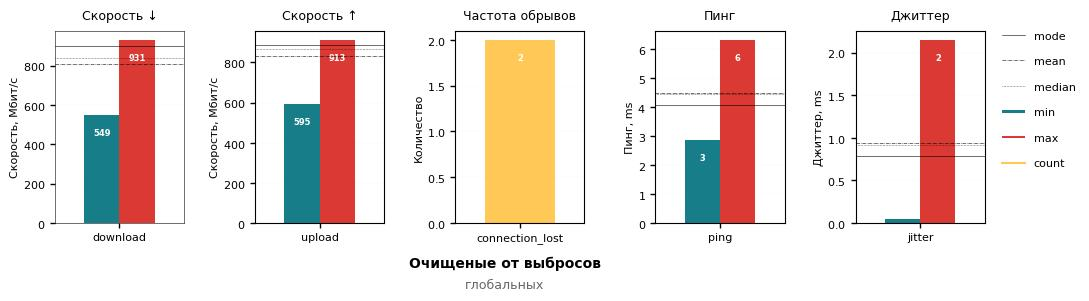

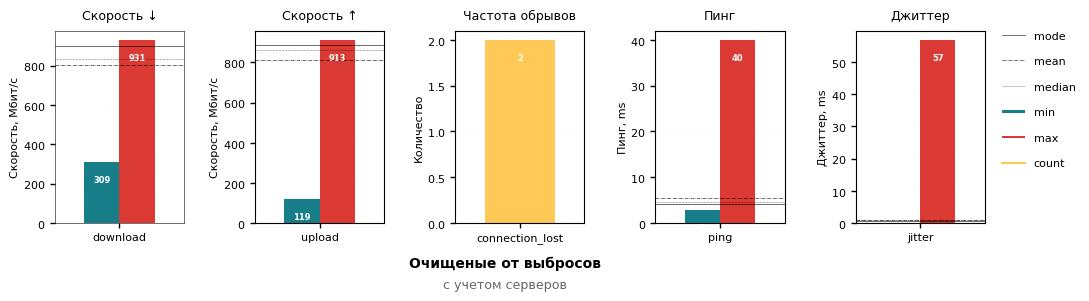

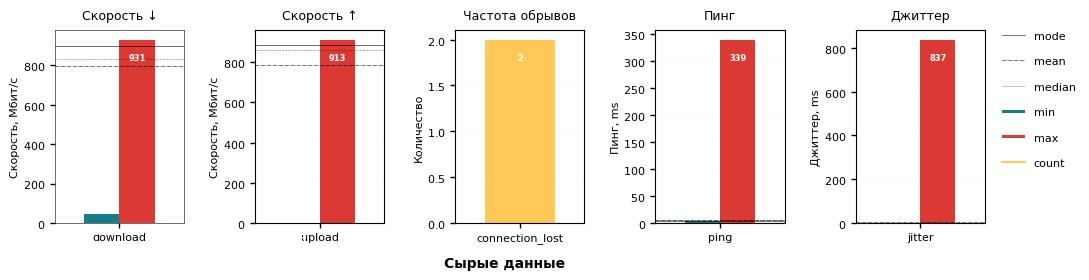

In [46]:
get_metrics_chart(
    desc_stat_df_cleaned, 
    title='Очищеные от выбросов',
    suptitle='глобальных',
    cls='12x2.5 t-o8xxs t-bc sp-ws0.55',
    chart_kws=dict(
        tpl='bar_00b lg_02f sbplot_bar_00', 
        # cls=''
    )
)
get_metrics_chart(
    desc_stat_df_gr_cleaned, 
    title='Очищеные от выбросов',
    suptitle='с учетом серверов',
    cls='12x2.5 t-o8xxs t-bc sp-ws0.55',
    chart_kws=dict(
        tpl='bar_00b lg_02f sbplot_bar_00', 
        # cls=''
    )
)
get_metrics_chart(
    desc_stat_df, 
    title='Сырые данные',
    suptitle='',
    cls='12x2.5 t-o8xxs t-bc sp-ws0.55',
    chart_kws=dict(
        tpl='bar_00b lg_02f sbplot_bar_00', 
        # cls=''
    )
)

Статистика по часам

In [47]:
desc_stat_per_hour_df_cleaned = get_metrics_per_period_table(df, group_index='hour', set_axis='hour', outliers=outliers, skip_outliers=['packet_loss', 'connection_lost'])
desc_stat_per_hour_df = get_metrics_per_period_table(df, group_index='hour', set_axis='hour')

display_grid(
    [desc_stat_per_hour_df_cleaned],
    grid=[1, 2],
    caption='ОБЩАЯ СТАТИСТИКА ПО ЧАСАМ',
    supcaption=['Без выбросов (глобальных)'],
    format=True,
    is_flat_th=True,
)

hour,metrics,min,max,mean,median,mode,count,sum
0,download,572.78,919.80,806.00,835.74,847.39,360,nan
0,upload,603.57,907.85,810.67,838.43,759.81,320,nan
0,ping,3.64,6.12,4.49,4.40,4.23,301,nan
0,jitter,0.09,1.95,0.96,0.93,0.49,324,nan
0,packet_loss,0.00,0.00,0.00,0.00,0.00,366,nan
0,connection_lost,0.00,0.00,0.00,0.00,0.00,366,0.00
1,download,550.33,916.82,811.00,838.12,811.87,351,nan
1,upload,601.61,900.68,822.74,851.21,753.03,324,nan
1,ping,3.54,6.02,4.44,4.38,4.06,301,nan
1,jitter,0.08,2.12,0.93,0.91,0.50,327,nan


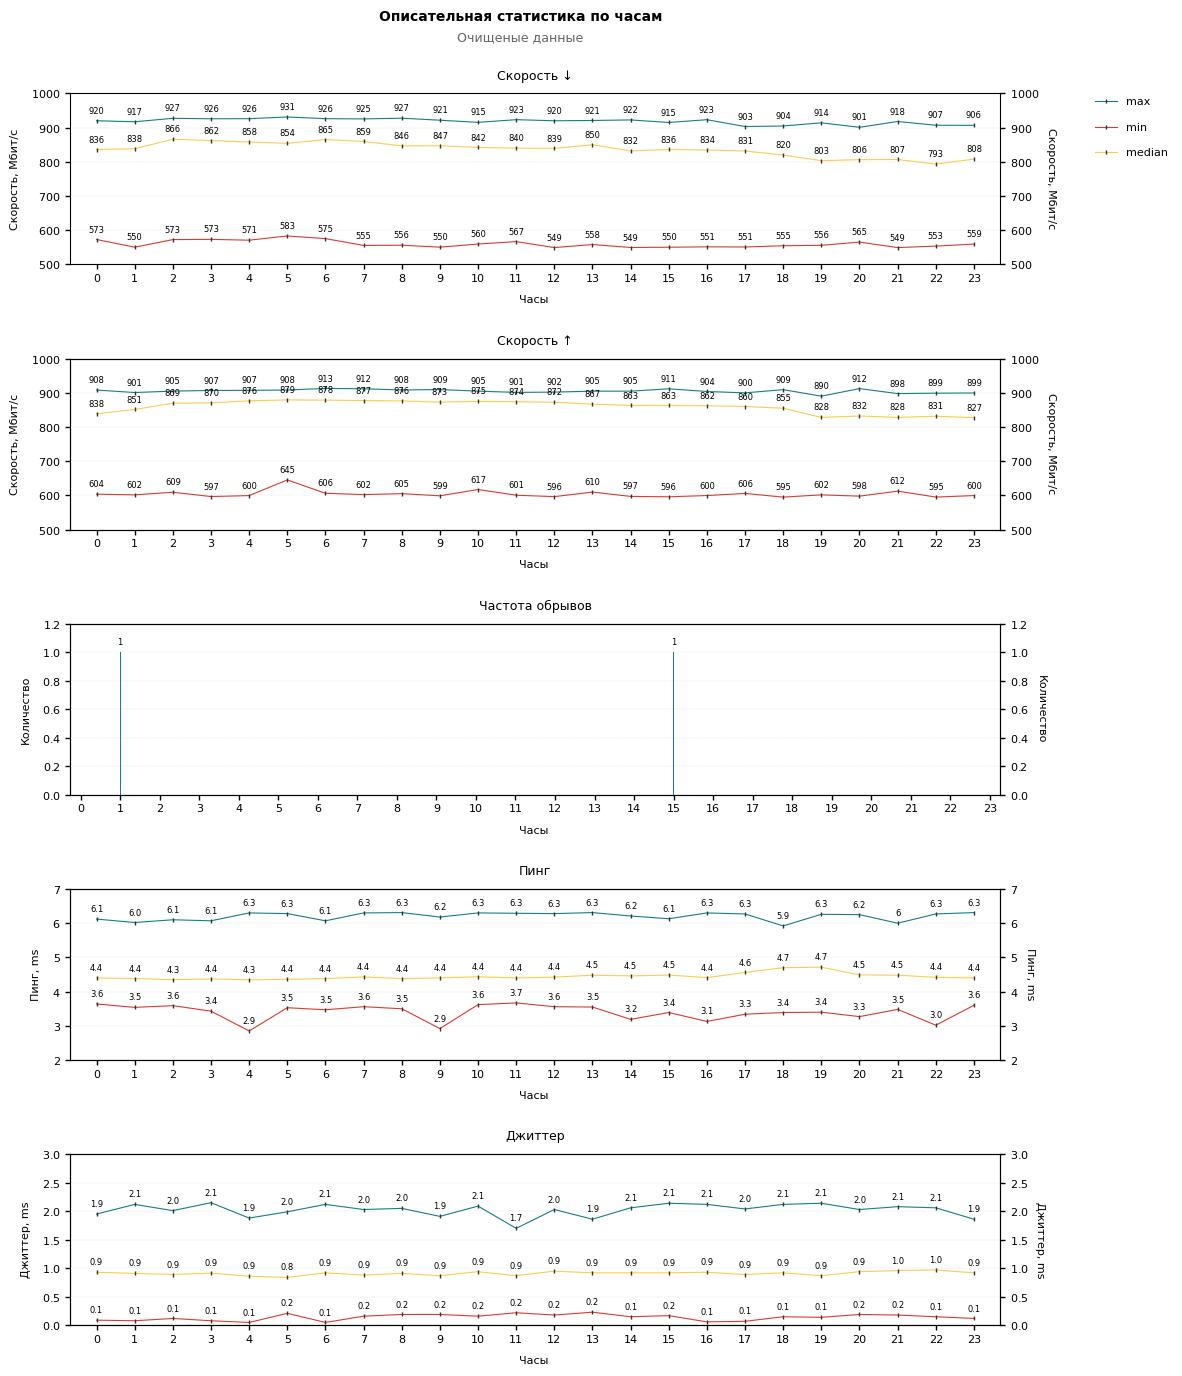

In [48]:
get_metrics_chart(
    desc_stat_per_hour_df_cleaned, 
    title='Описательная статистика по часам',
    suptitle='Очищеные данные',
    period=get_index_from_multi(desc_stat_per_hour_df_cleaned.index),
    # frame=[7, 1],
    # kinds=[['bar', 'plot'],['bar', 'plot'],'bar','plot','plot'],
    frame=[5, 1],
    kinds=['plot','plot','bar','plot','plot'],
    stat_fn_def=['max', 'min', 'median'],
    axhline_def=[],
    cls='12x16 t-ol sp-hs0.55', 
    chart_kws=dict(
        xlabel='Часы',
        legend_num=0,
        # color={'download': [0, 1, 3], 'packet_loss': 2, 'connection_lost': 2},
        color={'connection_lost': 0},
        legend_patch=[],
        ylim=dict(download=(500, 1000), upload=(500, 1000), jitter=(0, 3), connection_lost=(0, 1.05)),
        tpl='bar_00a lg_02f sbplot_plot_00 mr_04t mr_00|',
        cls='twx bar-5xs bar-lbn mr-not0 mr-f1-1f mr-tom ln-m',
    )
)

Статистика по времени суток

In [49]:
desc_stat_per_period_df_cleaned = get_metrics_per_period_table(df, reindex={'new_idx': ['Утро', 'День', 'Вечер', 'Ночь'], 'level': 'time'}, outliers=outliers, skip_outliers=['packet_loss', 'connection_lost'])
desc_stat_per_period_df = get_metrics_per_period_table(df, reindex={'new_idx': ['Утро', 'День', 'Вечер', 'Ночь'], 'level': 'time'})

display_grid(
    [desc_stat_per_period_df_cleaned],
    grid=[1, 2],
    caption='ОБЩАЯ СТАТИСТИКА ПО ВРЕМЕНИ СУТОК',
    supcaption=['Без выбросов (глобальных)'],
    format=True,
    is_flat_th=True,
)

time,metrics,min,max,mean,median,mode,count,sum
Утро,download,550.40,930.82,819.97,850.44,898.77,2 423,nan
Утро,upload,598.82,912.61,857.43,875.94,885.89,2 265,nan
Утро,ping,2.92,6.31,4.48,4.40,4.45,2 128,nan
Утро,jitter,0.05,2.12,0.92,0.90,0.65,2 280,nan
Утро,packet_loss,0.00,0.00,0.00,0.00,0.00,2 487,nan
Утро,connection_lost,0.00,0.00,0.00,0.00,0.00,2 487,0.00
День,download,549.22,922.90,809.16,838.65,834.24,1 726,nan
День,upload,595.93,911.46,828.68,866.07,873.22,1 541,nan
День,ping,3.13,6.31,4.49,4.45,4.74,1 588,nan
День,jitter,0.06,2.14,0.95,0.93,1.00,1 624,nan


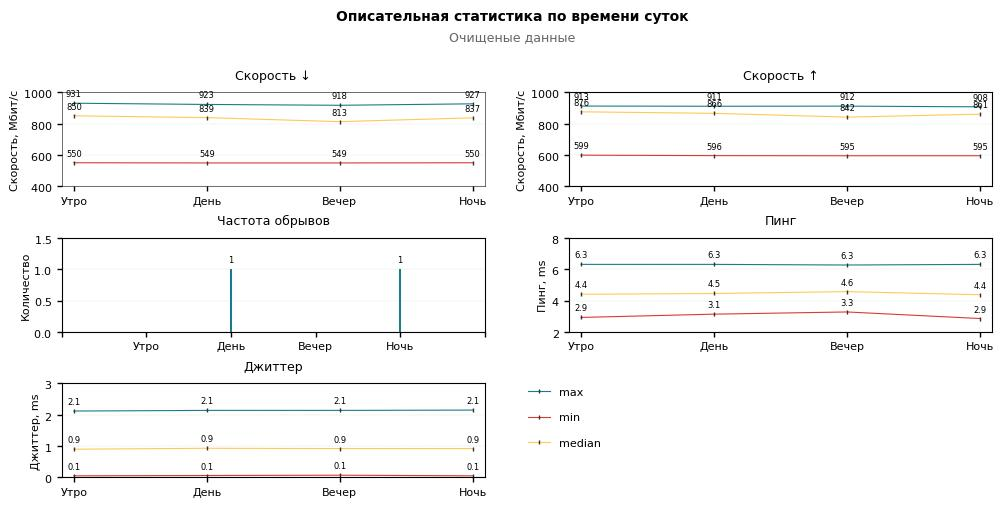

In [50]:
get_metrics_chart(
    desc_stat_per_period_df_cleaned, 
    title='Описательная статистика по времени суток',
    suptitle='Очищеные данные',
    period=get_index_from_multi(desc_stat_per_period_df_cleaned.index),
    frame=[3, 2],
    kinds=['plot','plot','bar','plot','plot'],
    stat_fn_def=['max', 'min', 'median'],
    axhline_def=[],
    cls='12x5 t-ol sp-ws0.2 sp-hs0.55',
    chart_kws=dict(
        xticks=4,
        legend_num=4,
        # color={'download': [0, 1, 3], 'packet_loss': 2, 'connection_lost': 2},
        color={'connection_lost': 0},
        legend_patch=[],
        ylim=dict(download=(500, 1000), upload=(500, 1000), jitter=(0, 3), connection_lost=(0, 1.05)),
        tpl='bar_00a lg_02f sbplot_plot_00 mr_04t mr_00|',
        cls='0x0 bar-5xs bar-lbn mr-not0 mr-f1-1f mr-tom ln-m gr-y y-hac yl-p2xs t-o6xl t-fw4 t-fsm lg-m7xl lg-pts lg-ptlw2xs lg-col1',
    )
)

Статистика по дням недели

In [51]:
desc_stat_per_weekday_df_cleaned = get_metrics_per_period_table(df, group_index='day_name_abbr', set_axis='day', reindex={'new_idx': ['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс'], 'level': 'day'}, outliers=outliers, skip_outliers=['packet_loss', 'connection_lost'])
desc_stat_per_weekday_df = get_metrics_per_period_table(df, group_index='day_name_abbr', set_axis='day', reindex={'new_idx': ['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс'], 'level': 'day'})

display_grid(
    [desc_stat_per_weekday_df_cleaned],
    grid=[1, 2],
    caption='ОБЩАЯ СТАТИСТИКА ПО ДНЯМ НЕДЕЛИ',
    supcaption=['Без выбросов (глобальных)'],
    format=True,
    is_flat_th=True,
)

day,metrics,min,max,mean,median,mode,count,sum
пн,download,552.11,927.63,819.80,842.02,792.21,1 015,nan
пн,upload,595.93,912.61,833.82,868.15,778.80,944,nan
пн,ping,2.85,6.31,4.41,4.34,4.87,906,nan
пн,jitter,0.08,2.12,0.94,0.91,0.63,1 009,nan
пн,packet_loss,0.00,0.00,0.00,0.00,0.00,1 101,nan
пн,connection_lost,0.00,0.00,0.00,0.00,0.00,1 101,0.00
вт,download,549.19,925.55,807.90,840.10,724.27,1 044,nan
вт,upload,595.45,908.99,844.91,871.27,871.27,981,nan
вт,ping,3.50,6.30,4.51,4.51,4.60,955,nan
вт,jitter,0.05,2.09,0.95,0.92,0.68,1 000,nan


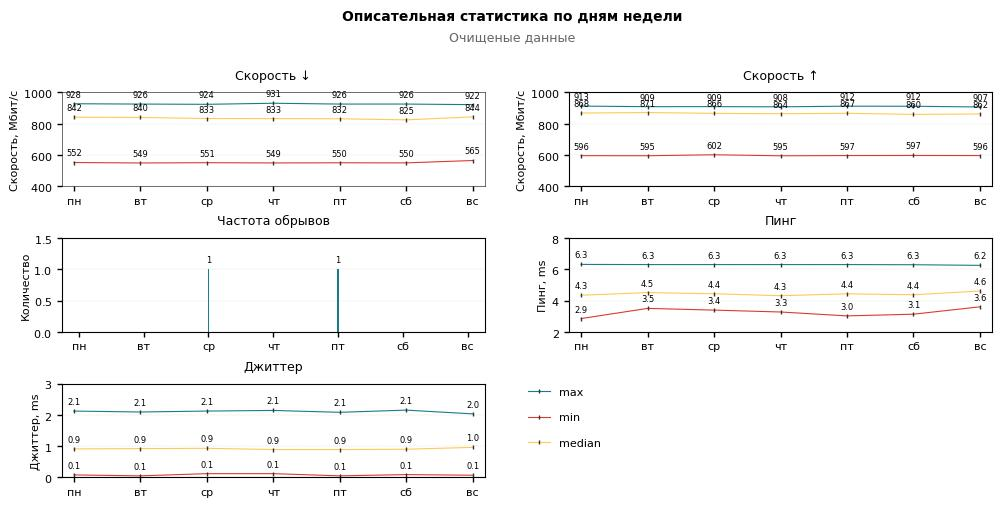

In [52]:
get_metrics_chart(
    desc_stat_per_weekday_df_cleaned, 
    title='Описательная статистика по дням недели',
    suptitle='Очищеные данные',
    period=get_index_from_multi(desc_stat_per_weekday_df_cleaned.index),
    frame=[3, 2],
    kinds=['plot','plot','bar','plot','plot'],
    stat_fn_def=['max', 'min', 'median'],
    axhline_def=[],
    cls='12x5 t-ol sp-ws0.2 sp-hs0.55',
    chart_kws=dict(
        # xticks=4,
        legend_num=4,
        # color={'download': [0, 1, 3], 'packet_loss': 2, 'connection_lost': 2},
        color={'connection_lost': 0},
        legend_patch=[],
        ylim=dict(download=(500, 1000), upload=(500, 1000), jitter=(0, 3), connection_lost=(0, 1.05)),
        tpl='bar_00a lg_02f sbplot_plot_00 mr_04t mr_00|',
        cls='0x0 bar-5xs bar-lbn mr-not0 mr-f1-1f mr-tom ln-m gr-y y-hac yl-p2xs t-o6xl t-fw4 t-fsm lg-m7xl lg-pts lg-ptlw2xs lg-col1',
    )
)

Статистика по дням

In [53]:
desc_stat_per_day_df_cleaned = get_metrics_per_period_table(df, group_index='day', set_axis='day', outliers=outliers, skip_outliers=['packet_loss', 'connection_lost'])
desc_stat_per_day_df = get_metrics_per_period_table(df, group_index='day', set_axis='day')

display_grid(
    [desc_stat_per_day_df_cleaned],
    grid=[1, 2],
    caption='ОБЩАЯ СТАТИСТИКА ПО ДНЯМ',
    supcaption=['Без выбросов (глобальных)'],
    format=True,
)

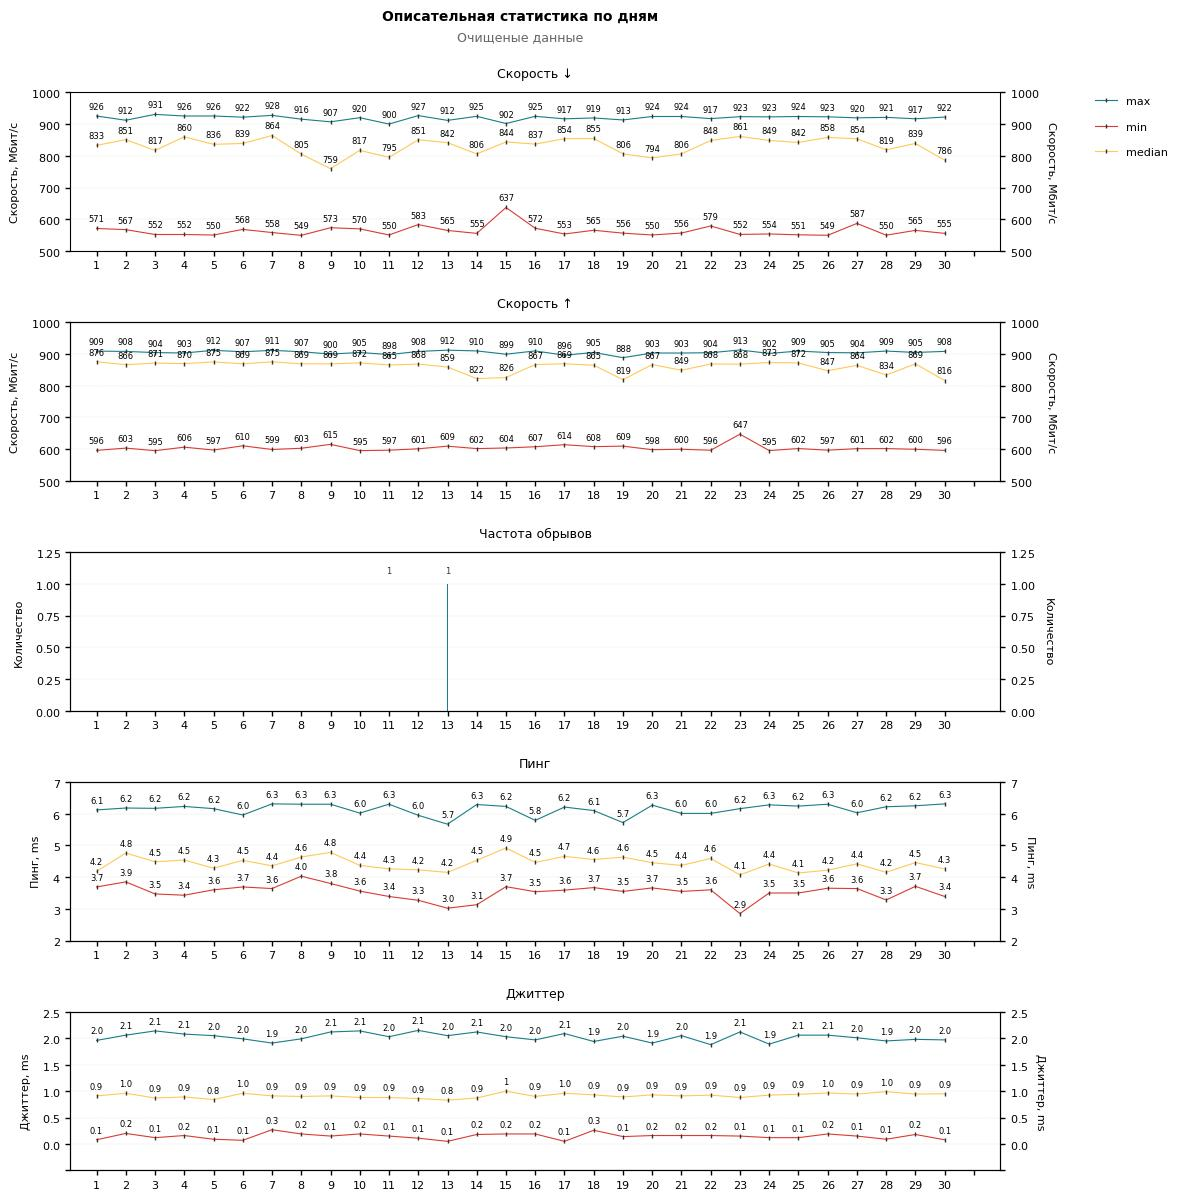

In [54]:
get_metrics_chart(
    desc_stat_per_day_df_cleaned, 
    title='Описательная статистика по дням',
    suptitle='Очищеные данные',
    period=get_index_from_multi(desc_stat_per_day_df_cleaned.index),
    frame=[5, 1],
    kinds=['plot','plot','bar','plot','plot'],
    stat_fn_def=['max', 'min', 'median'],
    axhline_def=[],
    cls='12x14 t-ol sp-hs0.45', 
    chart_kws=dict(
        # xlabel='Дни',
        legend_num=0,
        # color={'download': [0, 1, 3], 'packet_loss': 2, 'connection_lost': 2},
        color={'connection_lost': 0},
        legend_patch=[],
        # xticks=dict(connection_lost=range(1,31)),
        xlim=dict(default=(1, 31), connection_lost=(1, 30)),
        ylim=dict(download=(500, 1000), upload=(500, 1000), connection_lost=(0, 1.2)),
        tpl='bar_00a lg_02f sbplot_plot_00 mr_04t mr_00|',
        cls=dict(
            default='twx mr-not0 mr-f1-1f mr-tom ln-m', 
            connection_lost='twx bar-5xs bar-fn0 mr-tn'
        ),
    )
)

**Предварительно можно утверждать, что метрики скорости имеют высокие значения, а метрики задержек низкие не зависимо от времени суток, дня недели или дня месяца.** 

Исследуем зависимость каждой метрики более детально и ответим на поставленные вопросы.

Предварительно посмотрим взаимосвязь всех метрик построив матрицу корреляции и матрицу диаграмм рассеяния

In [55]:
# Очищенные
display_grid(
    [corrmatrix(df, ['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], ['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], outliers=outliers, skip_outliers=['server_distance', 'time_period_num', 'weekday', 'hour', 'day'])],
    grid=[1, 2],
    caption='МАТРИЦА КОРРЕЛЯЦИИ',
    supcaption=['Глобальная очистка'],
    format=True,
)
display_grid(
    [corrmatrix(df, ['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], ['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], mask=gr_outliers_fix, skip_outliers=['server_distance', 'time_period_num', 'weekday', 'hour', 'day'])],
    grid=[1, 2],
    caption='МАТРИЦА КОРРЕЛЯЦИИ',
    supcaption=['Очистка по серверам'],
    format=True,
)
display_grid(
    [corrmatrix(df, ['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], ['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], mask=gr_outliers_fix, skip_outliers=['server_distance', 'time_period_num', 'weekday', 'hour', 'day'])],
    grid=[1, 2],
    caption='МАТРИЦА КОРРЕЛЯЦИИ',
    supcaption=['Сырые данные'],
    format=True,
)

,download,upload,ping,jitter,server_distance,time_period_num,weekday,hour,day
download,1.00,0.13,-0.10,-0.03,-0.29,-0.09,-0.01,-0.15,0.03
upload,0.13,1.00,-0.04,-0.03,-0.10,-0.12,-0.04,-0.20,-0.09
ping,-0.10,-0.04,1.00,0.13,0.16,0.06,0.07,0.04,-0.05
jitter,-0.03,-0.03,0.13,1.00,0.09,0.03,0.00,0.05,0.04
server_distance,-0.29,-0.10,0.16,0.09,1.00,0.12,-0.00,0.06,0.03
time_period_num,-0.09,-0.12,0.06,0.03,0.12,1.00,-0.01,0.61,-0.00
weekday,-0.01,-0.04,0.07,0.00,-0.00,-0.01,1.00,-0.01,0.05
hour,-0.15,-0.20,0.04,0.05,0.06,0.61,-0.01,1.00,-0.01
day,0.03,-0.09,-0.05,0.04,0.03,-0.00,0.05,-0.01,1.00


,download,upload,ping,jitter,server_distance,time_period_num,weekday,hour,day
download,1.00,0.41,-0.47,-0.18,-0.48,-0.11,0.06,-0.15,0.02
upload,0.41,1.00,-0.65,-0.28,-0.66,-0.18,0.03,-0.18,-0.03
ping,-0.47,-0.65,1.00,0.34,0.90,0.08,-0.02,0.06,0.01
jitter,-0.18,-0.28,0.34,1.00,0.29,0.08,-0.04,0.05,0.03
server_distance,-0.48,-0.66,0.90,0.29,1.00,0.12,-0.00,0.06,0.03
time_period_num,-0.11,-0.18,0.08,0.08,0.12,1.00,-0.01,0.61,-0.00
weekday,0.06,0.03,-0.02,-0.04,-0.00,-0.01,1.00,-0.01,0.05
hour,-0.15,-0.18,0.06,0.05,0.06,0.61,-0.01,1.00,-0.01
day,0.02,-0.03,0.01,0.03,0.03,-0.00,0.05,-0.01,1.00


,download,upload,ping,jitter,server_distance,time_period_num,weekday,hour,day
download,1.00,0.41,-0.47,-0.18,-0.48,-0.11,0.06,-0.15,0.02
upload,0.41,1.00,-0.65,-0.28,-0.66,-0.18,0.03,-0.18,-0.03
ping,-0.47,-0.65,1.00,0.34,0.90,0.08,-0.02,0.06,0.01
jitter,-0.18,-0.28,0.34,1.00,0.29,0.08,-0.04,0.05,0.03
server_distance,-0.48,-0.66,0.90,0.29,1.00,0.12,-0.00,0.06,0.03
time_period_num,-0.11,-0.18,0.08,0.08,0.12,1.00,-0.01,0.61,-0.00
weekday,0.06,0.03,-0.02,-0.04,-0.00,-0.01,1.00,-0.01,0.05
hour,-0.15,-0.18,0.06,0.05,0.06,0.61,-0.01,1.00,-0.01
day,0.02,-0.03,0.01,0.03,0.03,-0.00,0.05,-0.01,1.00


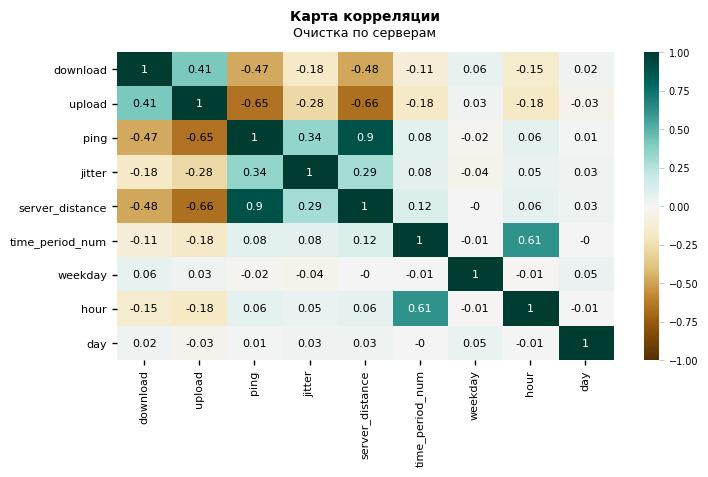

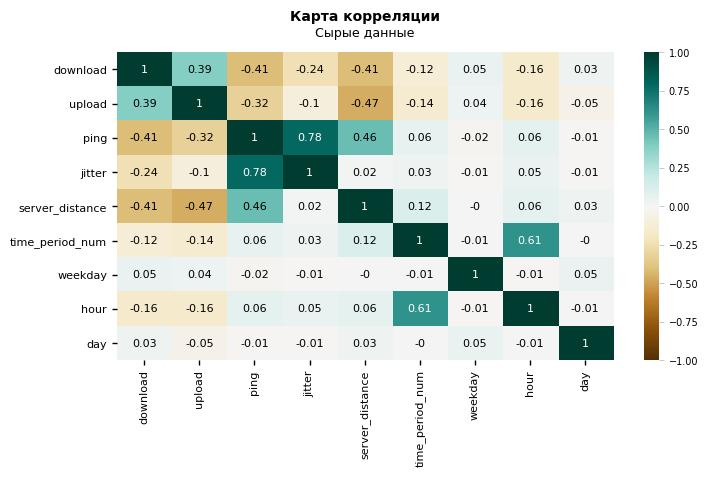

In [56]:
heatmap( 
    corrmatrix(df, ['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], ['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], mask=gr_outliers_fix, skip_outliers=['server_distance', 'time_period_num', 'weekday', 'hour', 'day']),
    title='Карта корреляции',
    suptitle='Очистка по серверам',
    xticklabels=['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'],
    yticklabels=['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'],
    tpl='hm_02',
    cls='8x4 cm-4 xtl-r90',
)
heatmap( 
    corrmatrix(df, ['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], ['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day']),
    title='Карта корреляции',
    suptitle='Сырые данные',
    xticklabels=['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'],
    yticklabels=['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'],
    tpl='hm_02',
    cls='8x4 cm-4 xtl-r90',
)

**Матрица корреляции показывает, что скорость зависит от пинга и расстояния до сервера. Пинг связан с джиттером и расстоянием до сервера. Данные коэффициенты имеют максимальные значения. Однако характер и сила взаимосвязи разная. Связь метрик с временными интервалами (время суток, день недели, час, день) минимальна или отсутствует.**

Визуализируем корреляцию построив графики

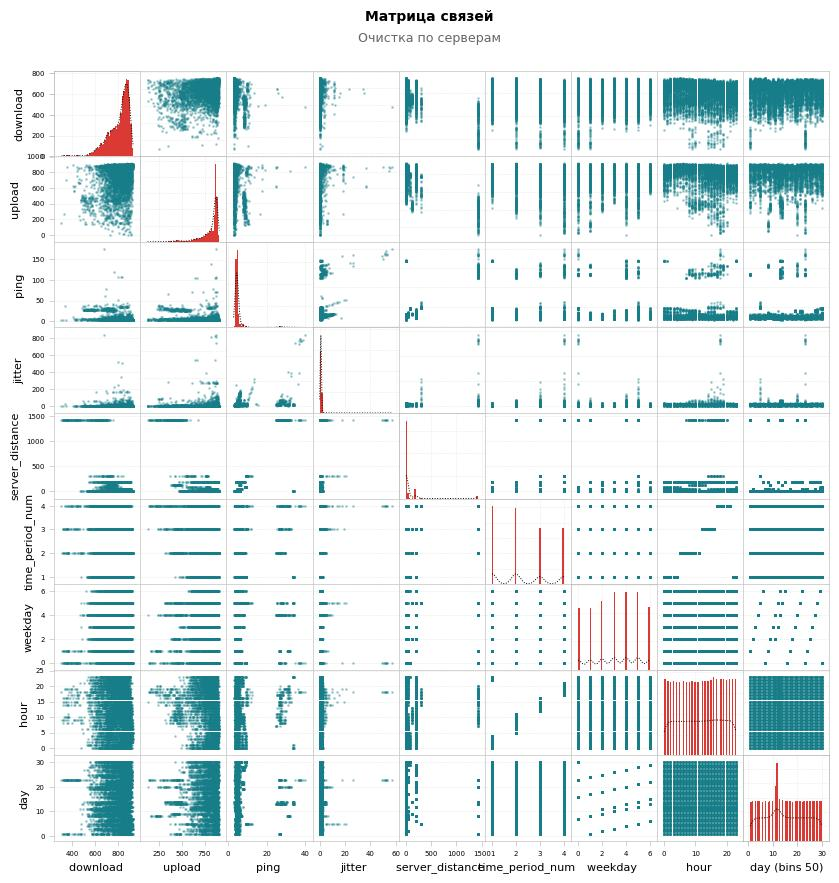

In [57]:
cscatter_matrix(
    data=[{'data': df[['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day']],
         'tpl': 'sm_01',
         'cls': '0x0 gr-y gr-a04 lg-n ln-s1 xl-pxl yl-pxl ytl-r0 xmg-10 ymg-10 fig-n', # ytl-r90
        }, {'data': df[['download', 'upload', 'ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day']],
         'tpl': 'sm_01 hist_01',
         'cls': '0x0 gr gr-a04 ax-a04 xt-a04 yt-a04 bns50 xl-pxl yl-pxl ytl-r0 kde ln-c1 lg-n xmg-10 ymg-10 fig-n', #ax-xlcmn 
        }],
    # df[['download', 'upload', 'ping']], 
    title='Матрица связей',
    suptitle='Очистка по серверам',
    # diag_kind='kdeplot',
    diag_kind='shist',
    mask=gr_outliers_fix,
    # tpl='sm_01',
    cls='10x10 t-o2m st-a06 sp-wsn sp-hsn'
)

**Матрица рассеивания показывает, что связь пинга и джиттера имеет положительный линейный характер.** 

При увеличении одного параметра увеличивается второй.

**Матрицы корреляции и диаграмм рассеивания показывают зависимость метрик от расстояния до сервера.**

Расстояние до сервера имеет прямую дискретную связь с пингом. На графиках видно, что при максимальном удалении сервера (~1500 единиц) пинг стабильно высокий (свыше 100 мс).

Из-за роста пинга на удаленных серверах (`server_distance ~1500`) максимальные планки скоростей `Download` и `Upload` заметно ниже, чем на близких серверах.

**Связь метрик с временными интервалами (время суток, день недели, час, день) минимальна или близка к нулю.** 

Метрики скорости и пинга распределены по часам и периодам суток относительно равномерно. Явных критических просадок скорости в определенные часы на графиках не выделяется, плотность распределения высоких скоростей сохраняется в течение суток.

#### Выводы

- Основываясь на полученных общих статистических данных и графиках, предварительно можно утверждать, что метрики скорости имеют высокие значения, а метрики задержек низкие не зависимо от времени суток, дня недели или дня месяца.
- Матрицы корреляции и диаграмм рассеивания показывают зависимость метрик от расстояния до сервера. Связь метрик с временными интервалами (время суток, день недели, час, день) минимальна или близка к нулю.

### 4.2. Скорость скачивания (`Download, D`) и загрузки (`Upload, U`) <a id="p42"></a>

#### 4.2.1. Графики скорости

Построим графики скоростей за весь период исследования. Т.к. количество данных большое, визуализируем медианы метрик по часам

In [58]:
metric_per_hour_df = pd.concat(
    [
        clean_outliers(df, mask=gr_outliers_fix['download']).pivot_table(index=['day', 'hour'], values=['download'], aggfunc=['median']).set_axis(['download'], axis=1),
        clean_outliers(df, mask=gr_outliers_fix['upload']).pivot_table(index=['day', 'hour'], values=['upload'], aggfunc=['median']).set_axis(['upload'], axis=1),
        clean_outliers(df, mask=gr_outliers_fix['ping']).pivot_table(index=['day', 'hour'], values=['ping'], aggfunc=['median']).set_axis(['ping'], axis=1),
        clean_outliers(df, mask=gr_outliers_fix['jitter']).pivot_table(index=['day', 'hour'], values=['jitter'], aggfunc=['median']).set_axis(['jitter'], axis=1),
        df.query('connection_lost == 0').pivot_table(index=['day', 'hour'], values=['packet_loss'], aggfunc=['mean']).set_axis(['packet_loss'], axis=1),
        df.pivot_table(index=['day', 'hour'], values=['connection_lost'], aggfunc=['sum']).set_axis(['connection_lost'], axis=1),
    ],
    axis=1,
    join='inner'
)

display(
    set_caption(
        print_rows(metric_per_hour_df, 3, mode='headtail', to_html=True),
        caption='МЕДИАНЫ МЕТРИК',
        supcaption='по часам',
        is_flat_th=True
    )
)

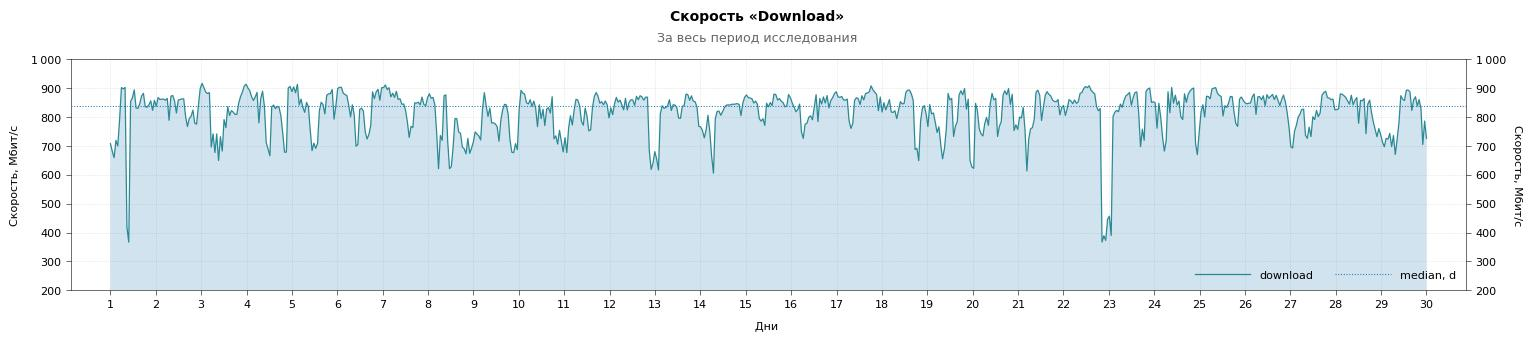

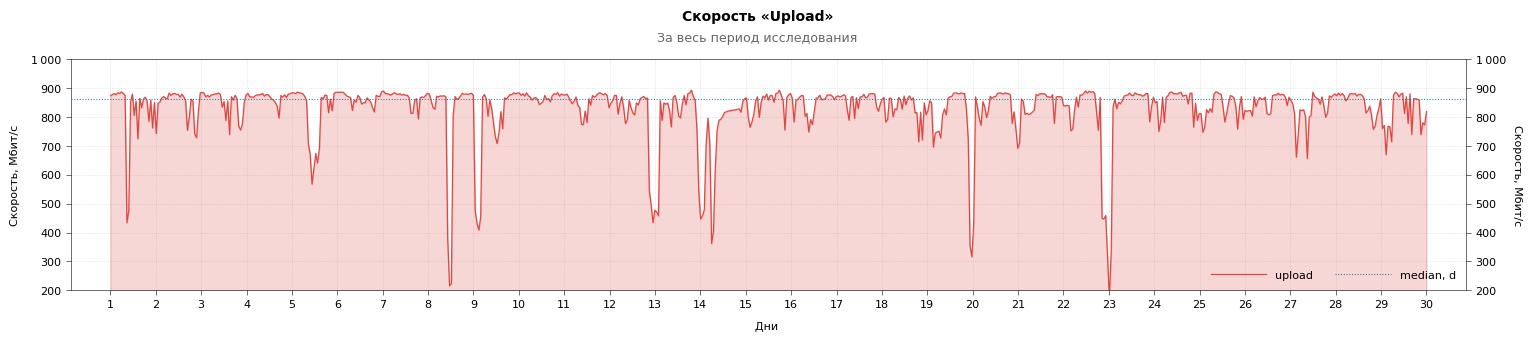

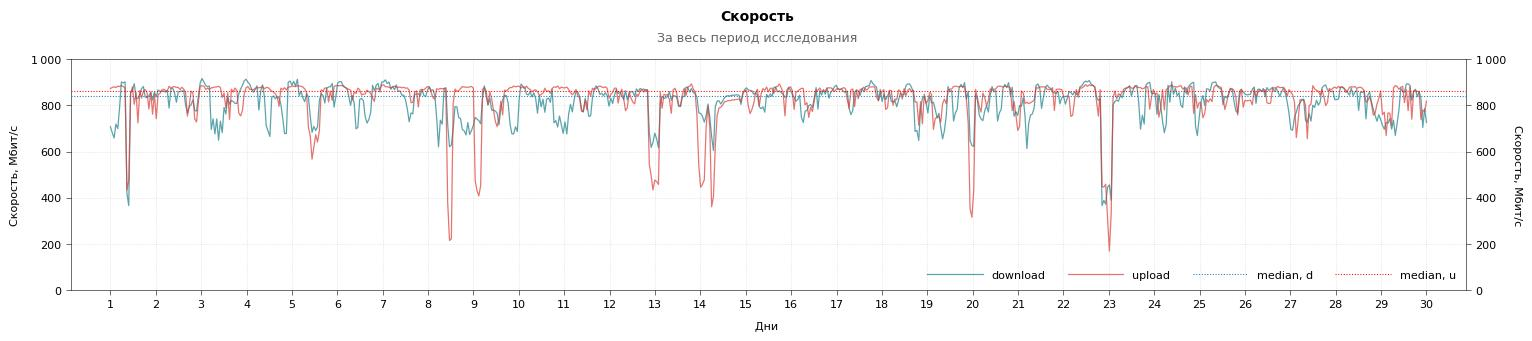

In [59]:
metric_per_hour_df_noindex = metric_per_hour_df.reset_index(drop=True)

plot(
    metric_per_hour_df_noindex, 
    y='download', 
    xlabel='Дни', 
    ylabel='Скорость, Мбит/с', 
    title='Скорость «Download»', 
    suptitle='За весь период исследования', 
    ylim=(200,950),
    xticklabels=get_index_from_multi(metric_per_hour_df.index), 
    xticks=30,
    xlim='trim',
    # xticklabelunits=len(get_index_from_multi(metric_per_hour_df.index, 0)) + 1, 
    fill_between={'x': metric_per_hour_df_noindex.index, 'y2': 0, 'y': metric_per_hour_df_noindex['download']}, 
    axhline=[{'y': metric_per_hour_df['download'].median(), 'label': 'median, d'}], 
    tpl='plot_01a lg_01g',
    cls='18x3 gr t-o2xs ln-a09 ln-l y-ths ax-ylcmn ax-xlcln xmg-3',
)

plot(
    metric_per_hour_df_noindex, 
    y='upload', 
    xlabel='Дни', 
    ylabel='Скорость, Мбит/с', 
    title='Скорость «Upload»', 
    suptitle='За весь период исследования', 
    ylim=(200,950), 
    xticklabels=get_index_from_multi(metric_per_hour_df.index), 
    xticks=30,
    xlim='trim', 
    # xticklabelunits=len(get_index_from_multi(metric_per_hour_df.index, 0)) + 1, 
    fill_between={'x': metric_per_hour_df_noindex.index, 'y2': 0, 'y': metric_per_hour_df_noindex['upload'], 'color':1}, 
    axhline=[{'y': metric_per_hour_df['upload'].median(), 'label': 'median, d'}], 
    tpl='plot_01a lg_01g',
    cls='18x3 gr t-o2xs ln-a09 ln-c1 ln-l y-ths ax-ylcmn ax-xlcln xmg-3',
)

plot(
    metric_per_hour_df, 
    y=['download', 'upload'], 
    xlabel='Дни', 
    ylabel='Скорость, Мбит/с', 
    title='Скорость', 
    suptitle='За весь период исследования',
    axhline=[{'y': metric_per_hour_df['download'].median(), 'label': 'median, d'}, {'y': metric_per_hour_df['upload'].median(), 'color': 'r', 'label': 'median, u'}],
    xticklabels=get_index_from_multi(metric_per_hour_df.index),
    xticks=30,
    xlim='trim',
    tpl='plot_01a lg_01g',
    cls='18x3 gr t-o2xs ln-a07 ln-l ln-ct ax-ylcmn ax-xlcln y-ths xmg-3'
)

#### 4.2.2. Взаимосвязь метрики

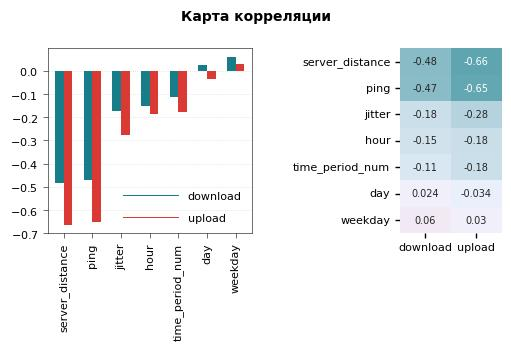

In [60]:
gsubplots(
    data=[
        {'data': corrmatrix(df, ['ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], ['download', 'upload'], mask=gr_outliers_fix, skip_outliers=['server_distance', 'time_period_num', 'weekday', 'hour', 'day']).sort_values(by='download'), 
         'tpl': 'bar_01 lg_01f',
         'cls': '0x0 y-plain ax-r90 lg-br t-ol t-m2 lg-col1 lg-pth0.7 lg_lh_s ln-ct fig-n',
        }, 
        {'data': corrmatrix(df, ['ping', 'jitter', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], ['download', 'upload'], mask=gr_outliers_fix, skip_outliers=['server_distance', 'time_period_num', 'weekday', 'hour', 'day']).sort_values(by='download'),  
         # 'cmap': [0, 5, 1], 
         'tpl': 'hm_01',
         'cls': '0x0 t-ol t-m2 cm-1 ax-r90 hm-afsxs fig-n',
        },
    ],
    frame=[1,3],
    frame_cells=[[0,[0,2]], [0,2]],
    kinds=['bar', 'sheatmap'],
    title='Карта корреляции', 
    tpl='sbplot_01',
    cls='5x3 t-o3xl sp-ws0.25'
)

Карта корреляции подтверждает рание выводы, что скорость более всего зависит от расстояния до сервера и пинга. С другими параметрами скорость не имеет выраженной линейной связи. Причина в широкополосном доступе, который свел зависимость метрик к минимуму.

Изучим детальнее зависимость скорости от расстояния до сервера `server_distance`.

Визуализируем зависимости и частотность 

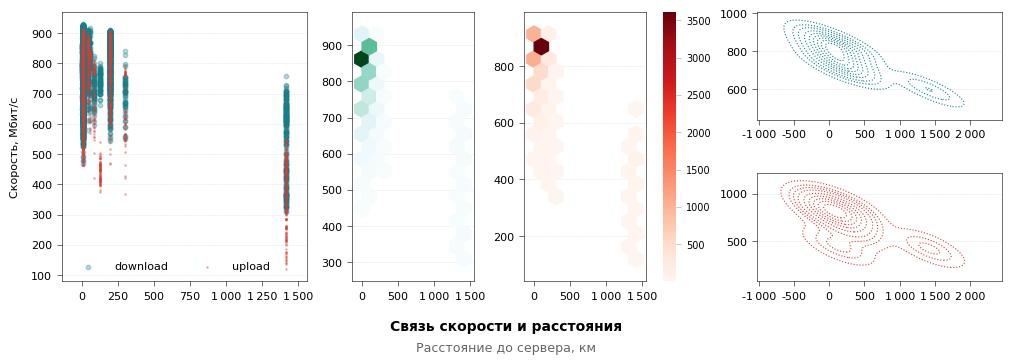

In [61]:
gsubplots(
    frame=[2,6],
    frame_cells=[[[0,2],[0,2]], [[0,2],[2,3]], [[0,2],[3,4]], [0,[4,6]], [1,[4,6]]],
    kinds=[['scatter', 'scatter'], 'hexbin', 'hexbin', 'kdeplot', 'kdeplot'],
    data=[
        [{'data': clean_outliers(df, mask=gr_outliers_fix['download']), 
         'x': 'server_distance', 'y': 'download',  
         'ylabel': 'Скорость, Мбит/с',
         'label': 'download',
         'tpl': 'scat_01',
         'cls': '0x0 x-ths ln-s10 xlm-trm xmg-10 fig-n'
        }, {'data': clean_outliers(df, mask=gr_outliers_fix['upload']), 
         'x': 'server_distance', 'y': 'upload',  
         'ylabel': 'Скорость, Мбит/с',
         'label': 'upload',
         'tpl': 'scat_01',
         'cls': '0x0 x-ths ln-s1 ln-c1 xlm-trm xmg-10 lg-bl fig-n'
        }],
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']), 
         'x': 'server_distance', 'y': 'download',
         'xticks': 4,
         'gridsize': (7, 9),
         'tpl': 'hb_01',
         'cls': '0x0 x-ths ax-lcmn hb-m1 xlm-trm xmg-10 ymg-10 cb-n fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['upload']), 
         'x': 'server_distance', 'y': 'upload', 
         'xticks': 4,
         'cmap': 'Reds',
         'gridsize': (7, 9),
         'tpl': 'hb_01',
         'cls': '0x0 x-ths ax-lcmn hb-m1 xlm-trm xmg-10 ymg-10 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']).pivot_table(index='server_distance', values='download', aggfunc='median').reset_index(), 
         'x': 'server_distance',
         'y': 'download',
         'label': 'download',
         'tpl': 'plot_01 ln-01d',
         'cls': '0x0 x-ths ax-ylcmn xlm-trm lg-tr xmg-5 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['upload']).pivot_table(index='server_distance', values='upload', aggfunc='median').reset_index(),
         'x': 'server_distance',
         'y': 'upload', 
         'label': 'upload',
         'tpl': 'plot_01 ln-01d',
         'cls': '0x0 x-ths ln-c1 xlm-trm lg-tr xmg-5 fig-n'
        }
    ],
    title='Связь скорости и расстояния', 
    suptitle='Расстояние до сервера, км',
    tpl='sbplot_01',
    cls='10x3 t-o10xxs t-bc sp-ws0.05 sp-hs0.05'
)

**Видна закономерность – с возрастанием расстояния, уменьшается скорость. В самой плотной области с наиболее частыми сочетаниями скорости и расстояния с максимальной скоростью 850-900 Мбит/с и минимальным расстоянием до 5 км. Данные с расстоянием 1400 км имеют низкую частоту, а в интервале 300-1000 км отсутствуют вовсе.**

Однако неболшая отрицательная величина коэффициента корреляции Пирсона `-0.48— -0.66` говорит о наличии не сильной обратной связи. Кроме того, выборка не равномерна. Количество измерений с большим расстоянием значительно меньше, и недостаточно для статистически значимых выводов, а значения расстояний в интервале 300-1000 отсутствуют вовсе.

### 4.3. Пинг (`Ping, P`) и джиттер (`Jitter, J`) <a id="p43"></a>

#### 4.3.1. Графики пинга и джитера

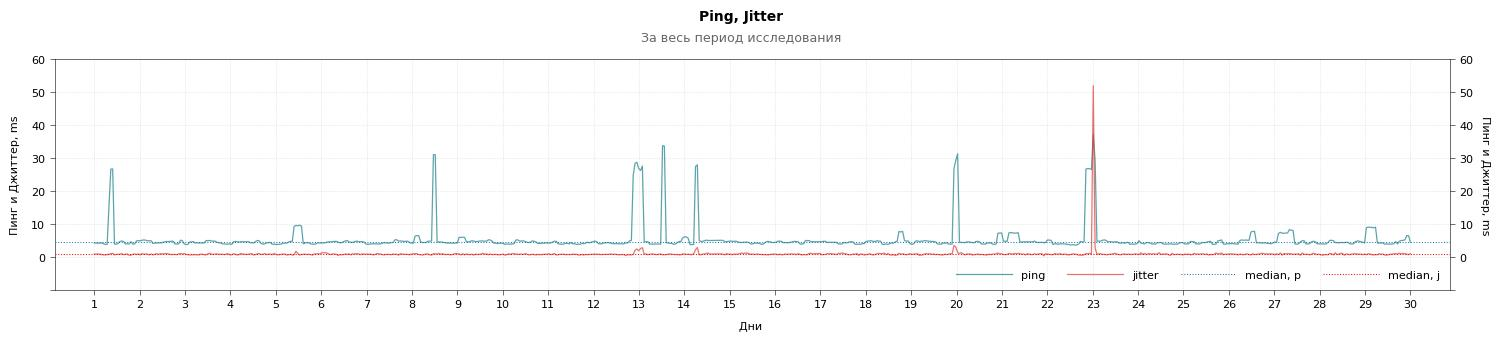

In [62]:
metric_per_hour_df_noindex = metric_per_hour_df.reset_index(drop=True)

plot(
    metric_per_hour_df, 
    y=['ping', 'jitter'], 
    xlabel='Дни', 
    ylabel='Пинг и Джиттер, ms', 
    title='Ping, Jitter', 
    suptitle='За весь период исследования',
    xticklabels=get_index_from_multi(metric_per_hour_df.index), 
    xticks=30,
    xlim='trim',
    axhline=[{'y': metric_per_hour_df['ping'].median(), 'label': 'median, p'}, {'y': metric_per_hour_df['jitter'].median(), 'color': 'r', 'label': 'median, j'}], 
    tpl='plot_01a lg_01g',
    cls='18x3 gr ytl-0 t-o2xs ln-a07 ln-ct ln-l y-ths ax-ylcmn ax-xlcln xmg-3', # xlm-trm ymg-5
)

#### 4.3.2. Взаимосвязь метрики

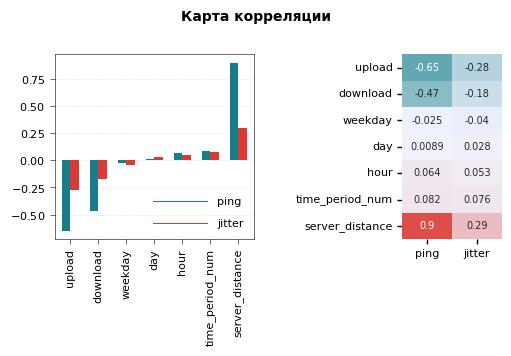

In [63]:
gsubplots(
    data=[
        {'data': corrmatrix(df, ['download', 'upload', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], ['ping', 'jitter'], mask=gr_outliers_fix, skip_outliers=['server_distance', 'time_period_num', 'weekday', 'hour', 'day']).sort_values(by='ping'), 
         'tpl': 'bar_01 lg_01f', 
         'cls': '0x0 y-plain ax-r90 lg-br t-ol t-m2 lg-col1 lg-pth0.7 lg_lh_s ln-ct fig-n',
        }, 
        {'data': corrmatrix(df, ['download', 'upload', 'server_distance', 'time_period_num', 'weekday', 'hour', 'day'], ['ping', 'jitter'], mask=gr_outliers_fix, skip_outliers=['server_distance', 'time_period_num', 'weekday', 'hour', 'day']).sort_values(by='jitter'), 
         # 'cmap': [0, 5, 1], 
         'tpl': 'hm_01',
         'cls': '0x0 t-ol t-m2 cm-1 ax-r90 hm-afsxs fig-n',
        },
    ],
    frame=[1,3],
    frame_cells=[[0,[0,2]], [0,2]],
    kinds=['bar', 'sheatmap'],
    title='Карта корреляции', 
    tpl='sbplot_01',
    cls='5x3 t-oxl sp-ws0.25'
)

Расстояние до сервера имеет прямую линейную связь с пингом.

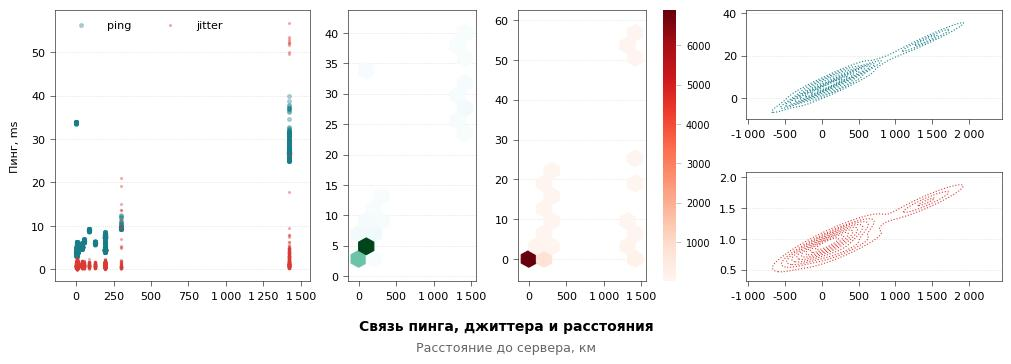

In [64]:
gsubplots(
    frame=[2,6],
    frame_cells=[[[0,2],[0,2]], [[0,2],[2,3]], [[0,2],[3,4]], [0,[4,6]], [1,[4,6]]], 
    kinds=[['scatter', 'scatter'], 'hexbin', 'hexbin', 'kdeplot', 'kdeplot'], 
    data=[
        [{'data': clean_outliers(df, mask=gr_outliers_fix['ping']), 
         'x': 'server_distance', 'y': 'ping', 
         'label': 'ping',
         'tpl': 'scat_01',
         'cls': '0x0 x-ths ln-s7 xlm-trm xmg-10 fig-n'
        }, {'data': clean_outliers(df, mask=gr_outliers_fix['jitter']), 'x': 'server_distance', 'y': 'jitter',  
         'ylabel': 'Пинг, ms',
         'label': 'jitter',
         'tpl': 'scat_01',
         'cls': '0x0 x-ths ln-s2 ln-c1 xlm-trm xmg-10 lg-tl fig-n'
        }],
        {'data': clean_outliers(df, mask=gr_outliers_fix['ping']), 
         'x': 'server_distance', 'y': 'ping',
         'xticks': 4,
         'gridsize': (7, 9),
         'tpl': 'hb_01',
         'cls': '0x0 x-ths ax-lcmn hb-m1 xlm-trm xmg-10 ymg-10 cb-n fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['jitter']), 
         'x': 'server_distance', 'y': 'jitter', 
         'xticks': 4,
         'cmap': 'Reds',
         'gridsize': (7, 9),
         'tpl': 'hb_01',
         'cls': '0x0 x-ths ax-lcmn hb-m1 xlm-trm xmg-10 ymg-10 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['ping']).pivot_table(index='server_distance', values='ping', aggfunc='median').reset_index(), 
         'x': 'server_distance',
         'y': 'ping',
         'label': 'ping',
         'tpl': 'plot_01 ln-01d',
         'cls': '0x0 x-ths ax-ylcmn xlm-trm lg-tr xmg-5 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['jitter']).pivot_table(index='server_distance', values='jitter', aggfunc='median').reset_index(),
         'x': 'server_distance',
         'y': 'jitter',
         'tpl': 'plot_01 ln-01d',
         'cls': '0x0 x-ths ln-c1 xlm-trm lg-tr xmg-5 fig-n'
        }
    ],
    title='Связь пинга, джиттера и расстояния', 
    suptitle='Расстояние до сервера, км',
    tpl='sbplot_01',
    cls='10x3 t-o10xxs t-bc sp-ws0.05 sp-hs0.05'
)

**Видна четкая линейная связь – с возрастанием расстояния, увеличивается пинг. В самой плотной области с наиболее частыми сочетаниями пинга и расстояния — пинг около 5 мс и минимальное расстояние до 5 км. Данные с расстоянием 1400 км имеют низкую частоту, а в интервале 300-1000 км отсутствуют вовсе.**

### 4.4. Потеря пакетов (`Loss, L`) и частота обрывов (`Disconnects, Dc`)<a id="p44"></a>

In [65]:
display(df[(df['connection_lost'] > 0) | (df['packet_loss'] > 0)])

,timestamp,ping,jitter,download,upload,packet_loss,connection_lost,connection_recovered,connection_error,server_id,server_name,server_city,server_sponsor,server_host,server_distance,day,month,year,day_name,day_name_abbr,weekday,is_weekend,hour,server_id_change,time_period,time_period_num,download_rating,upload_rating,ping_rating,jitter_rating,packet_loss_rating,connection_lost_rating,metrics
16,2025-06-11 15:57:05,3.81,0.85,63.08,0.00,100,1,False,Unknown,25330,Ekaterinburg,Ekaterinburg,TTK Ural,speedtest.uralttk.ru:8080,4.36,11,6,2025,Среда,ср,2,0,15,1,День,3,2,1,2.00,1.00,NaN,2,metric
403,2025-06-13 01:32:40,4.09,0.87,107.42,0.00,100,1,False,Ok,5844,Ekaterinburg,Ekaterinburg,DOM.RU,ookla.ekat.ertelecom.ru:8080,4.36,13,6,2025,Пятница,пт,4,0,1,5,Ночь,1,2,1,2.00,1.00,NaN,2,metric


Общее количество измерений с обрывом соединения и потерей пакетов всего 2. Это говорит о стабильности соединения.

### 4.5. Проверка гипотез<a id="p45"></a>

Цель исследования включает проверку гипотезы: 
- Скорость интернет-соединения зависит от времени суток.

А также ответа на вопрос:
- В какое время суток показатели метрик самые высокие и низкие?
- В какой час суток показатели метрик самые высокие и низкие?
- В какой день недели показатели метрик самые высокие и низкие?

>Считается, что скорость интернет-соединения может зависеть от времени суток. В часы пик, когда большое количество пользователей одновременно выходит в сеть, скорость может снижаться из-за перегрузки каналов и оборудования:
>- В вечернее время, когда люди возвращаются домой и начинают активно пользоваться интернетом, сетевые каналы могут перегружаться, что приводит к снижению скорости;
>- Ночью и утром интернетом пользуется меньшее количество пользователей, поэтому нагрузка на сеть меньше и скорость выше. Нагрузка меньше всего во второй половине ночи, под утро, когда все полуночники спят, а жаворонки ещё не проснулись.
>
>Также некоторые провайдеры могут предоставлять разные скорости в разное время суток, например, более низкую скорость в ночное время, когда спрос на интернет меньше.
>
>Однако у хороших провайдеров, имеющих запас по скорости в часы наибольшей нагрузки (ЧНН), различия значений скорости в разное время суток незначительны или отсутствуют.

Для проверки гипотезы рассчитаем абсолютную и процентную разницу медиан скорости по времени суток. Для этого найдем минимальные и максимальные значения

In [66]:
desc_stat_per_period_df_gr_cleaned = get_metrics_per_period_table(df, reindex={'new_idx': ['Утро', 'День', 'Вечер', 'Ночь'], 'level': 'time'}, mask=gr_outliers_fix, skip_outliers=['packet_loss', 'connection_lost'])

def get_diff_values(data, metric, col='median'):
    '''
    :example:
    `get_diff_values(desc_stat_per_period_df.data, ['download', 'upload'])`
    //=> [{'metrics': 'download',
           'time_min': 'сб',
           'min': 816.89,
           'time_max': 'вт',
           'max': 857.74,
           'diff_mbps': 40.85,
           'diff_perc': 4.76},
          {'metrics': 'upload',
           'time_min': 'сб',
           'min': 822.29,
           'time_max': 'вт',
           'max': 869.075,
           'diff_mbps': 46.79,
           'diff_perc': 5.38}]
    '''
    diff = []
    for m in metric if isinstance(metric, list) else [metric]:
        idx = [v for v in data.index if m in v]
        # min_max_df = data.loc[idx][col].groupby('metrics').agg(['min', 'max'])
        metric_df = data.loc[idx][col]
        diff += [{
            'metrics': m,
            'time_min': metric_df.idxmin()[0],
            'min': metric_df.min(),
            'time_max': metric_df.idxmax()[0],
            'max': metric_df.max(),
            'diff_mbps': round(metric_df.max() - metric_df.min(), 2), 
            'diff_perc': round(100 - metric_df.min() / metric_df.max() * 100, 2)
        }]
        
    return diff if isinstance(metric, list) else diff[0]

display(    
    set_caption(
        pd.DataFrame(get_diff_values(desc_stat_per_period_df_gr_cleaned, ['download', 'upload'])),
        caption='Разница медиан скорости по времени суток', 
        supcaption='Очищенные (по серверам)',
        format=True,
        # is_flat_th=True
    ),
)

,metrics,time_min,min,time_max,max,diff_mbps,diff_perc
0,download,Вечер,810.64,Утро,848.87,38.23,4.50
1,upload,Вечер,829.12,Утро,874.71,45.59,5.21


**Расчеты показывают, что минимальные показатели скорости наблюдались `вечером`, а максимальные `утром`.** 
Данные значения не учитывают разное географическое расположение серверов (*).

```
(*) Утилита `speedtest` лежащая в основе модуля собирающего данные имеет особенность, связанную с тем, что периодически меняется список доступных серверов из которых выбирается лучший. И случается так, что в списке присутствуют только сервера из других регионов, удаленных географически. На таких серверах cкорость и другие метрики значительно ниже. Это влияет на показатели.
```

Исключим из расчетов удаленные сервера, на которых проводились измерения в вечерний и утренний периоды времени.

In [67]:
display_grid(
    [
    set_caption(
        print_value_counts(df, 'server_distance', normalize=True, prec=1, perc=True, sort_index=True, cut_last=True, to_html=True),
        caption='Расстояние', 
        supcaption='до сервера, %',
        is_flat_th=True
    ),
    set_caption(
        clean_outliers(df, mask=gr_outliers_fix['download'])
        .query('time_period == "Вечер"')
        .pivot_table(index=['server_sponsor', 'server_city', 'server_distance', 'time_period'], values='download', aggfunc=['median', 'count'])
        .set_axis(['median', 'count'], axis=1)
        .sort_values(by='median')
        .head(10),
        caption='TOP-10 СЕРВЕРОВ', 
        supcaption='с мин. скоростью скачивания вечером',
        format=True,
        is_flat_th=True
    ),
    set_caption(
        clean_outliers(df, mask=gr_outliers_fix['download'])
        .query('time_period == "Утро"')
        .pivot_table(index=['server_sponsor', 'server_city', 'server_distance', 'time_period'], values='download', aggfunc=['median', 'count'])
        .set_axis(['median', 'count'], axis=1)
        .sort_values(by='median')
        .head(10),
        caption='TOP-10 СЕРВЕРОВ', 
        supcaption='с мин. скоростью скачивания утром',
        format=True,
        is_flat_th=True
    ),
    set_caption(
        clean_outliers(df, mask=gr_outliers_fix['upload'])
        .query('time_period == "Вечер"')
        .pivot_table(index=['server_sponsor', 'server_city', 'server_distance', 'time_period'], values='upload', aggfunc=['median', 'count'])
        .set_axis(['median', 'count'], axis=1)
        .sort_values(by='median')
        .head(10),
        caption='TOP-10 СЕРВЕРОВ', 
        supcaption='с мин. скоростью загрузки вечером',
        format=True,
        is_flat_th=True
    ),
    set_caption(
        clean_outliers(df, mask=gr_outliers_fix['upload'])
        .query('time_period == "Утро"')
        .pivot_table(index=['server_sponsor', 'server_city', 'server_distance', 'time_period'], values='upload', aggfunc=['median', 'count'])
        .set_axis(['median', 'count'], axis=1)
        .sort_values(by='median')
        .head(10),
        caption='TOP-10 СЕРВЕРОВ', 
        supcaption='с мин. скоростью загрузки утром',
        format=True,
        is_flat_th=True
    )
    ],
    grid=[1,5]
)

server_sponsor,server_city,server_distance,time_period,median,count
Марьино.net,Moscow,1 419.61,Вечер,428.14,33
Polycomm,Moscow,1 419.61,Вечер,624.28,31
team-host ltd,Moscow,1 419.61,Вечер,629.87,30
OOO Pozitiv Telecom,Tyumen,297.50,Вечер,704.26,24
IS-Telecom,Chelyabinsk,193.01,Вечер,731.19,18
Convex,Asbest,52.38,Вечер,732.73,16
Beeline Mobile,Ekaterinburg,4.36,Вечер,755.65,166
TTK Ural,Ekaterinburg,4.36,Вечер,797.61,315
t2 Russia,Chelyabinsk,192.20,Вечер,803.74,144
t2 Russia,Ekaterinburg,4.36,Вечер,810.53,151


In [68]:
desc_stat_per_period_df_sd_cleaned = get_metrics_per_period_table(df.query('server_distance < 80'), reindex={'new_idx': ['Утро', 'День', 'Вечер', 'Ночь'], 'level': 'time'}, outliers=outliers, skip_outliers=['packet_loss', 'connection_lost'])
desc_stat_per_period_df_gr_sd_cleaned = get_metrics_per_period_table(df.query('server_distance < 80'), reindex={'new_idx': ['Утро', 'День', 'Вечер', 'Ночь'], 'level': 'time'}, mask=gr_outliers_fix, skip_outliers=['packet_loss', 'connection_lost'])

display(    
    set_caption(
        pd.DataFrame(get_diff_values(desc_stat_per_period_df_gr_sd_cleaned, ['download', 'upload'])),
        caption='Разница медиан скорости по времени суток', 
        supcaption='Очищенные (по серверам)',
        format=True,
        # is_flat_th=True
    ),
)

,metrics,time_min,min,time_max,max,diff_mbps,diff_perc
0,download,Вечер,819.22,Утро,855.02,35.80,4.19
1,upload,Вечер,840.29,Утро,875.89,35.60,4.06


**Разница в `4.19%` и `4.06%` между утренней и вечерней медианой скорости технически является незначительной для интернет-сетей и с высокой вероятностью может быть вызвана погрешностью измерений или случайными колебаниями.**

Проверим гипотезу, проведем стат. тесты.

In [69]:
display_grid(
    [
        print_stat_test(clean_outliers(df, mask=gr_outliers_fix['download']).query('time_period == "Вечер"')['download'], clean_outliers(df, mask=gr_outliers_fix['download']).query('time_period == "Утро"')['download'], to_html=True),
        print_effect_size(clean_outliers(df, mask=gr_outliers_fix['download']).query('time_period == "Вечер"')['download'], clean_outliers(df, mask=gr_outliers_fix['download']).query('time_period == "Утро"')['download'], to_html=True)
    ],
    grid=[1, 2],
    title='СТАТ. ТЕСТЫ',
    format=True,
    vspace=35
)

<div style="font-size: 0.8em; padding: 1.2em 0 0.8em; font-weight: 700; text-align: center">СТАТ. ТЕСТЫ</div><div style="display:flex"><div style="margin: 0px 0 0 0px">


| <span style="white-space: nowrap;">Mann-Whitney</span> |  |
|:---|:---|
| U-статистика | 1591990.50 |
| p-value | 0.0000 |
| Вывод | Разница статистически значима, отвергаем нулевую гипотезу |
    

</div><div style="margin: 0px 0 0 35px">


| Cliff's Delta |  |
|:---|:---|
| Размер эффекта | -0.2679 |
| Вывод | Эффект слабый |
    

</div></div>

Разница между утром и вечером статистически значима (`p-value` критически мало), а размер эффекта `Cliff's Delta` равный `-0.268` классифицируется как `слабый/умеренный` (`small-to-medium`). Это означает, что вечернее снижение скорости — не случайный шум, а стабильный системный процесс (нагрузка на сеть растет).
Однако с точки зрения пользовательского опыта разницы нет. Снижение медианы с `855 Мбит/с` до `819 Мбит/с` пользователь заметить не сможет, так как для любого тяжелого контента скоростей хватает с огромным запасом.

Медиана часто маскирует локальные проблемы. Проверим скрытые аномалии:
1. «Тяжелые хвосты» (10 перцентиль). Посмотрим на 10-й перцентиль (худшая скорость). Возможно, медиана упала всего на `4.19%`, но у `10%` вечерних показателей скорость упала на `50%`.
2. Дисперсию (разброс) и стандартное отклонение. Вечером разброс скоростей обычно гораздо шире, чем утром, из-за неравномерной нагрузки по домам/квартирам. Если вечернее отклонение сильно выше утреннего, значит, вечерний трафик стал нестабильным и рваным.

In [70]:
display_grid(
    [
        print_adv_describe(
            [
                clean_outliers(df, mask=gr_outliers_fix['download']).query('time_period == "Утро" and server_distance < 80'),
                clean_outliers(df, mask=gr_outliers_fix['download']).query('time_period == "Вечер" and server_distance < 80'),
            ],
            'download', 
            colnames=['Утро', 'Вечер'],
            to_html=True
        ),
        print_adv_describe(
            [
                clean_outliers(df, mask=gr_outliers_fix['upload']).query('time_period == "Утро" and server_distance < 80'),
                clean_outliers(df, mask=gr_outliers_fix['upload']).query('time_period == "Вечер" and server_distance < 80'),
            ],
            'upload', 
            colnames=['Утро', 'Вечер'],
            to_html=True
        ),
    ],
    grid=[1, 2],
    caption=['DOWNLOAD', 'UPLOAD'],
    format=True,
    vspace=35
)


,Утро,Вечер
Медиана (p50),855.02,819.22
Среднее,826.11,797.69
Дисперсия (Var),6679.74,5972.87
Ср. квадр. отклон. (Std),81.73,77.28
p10 (Худшие 10%),703.74,682.15
p90 (Лучшие 10%),904.42,876.21
,Утро,Вечер
Медиана (p50),875.89,840.29
Среднее,855.78,803.34
Дисперсия (Var),3559.03,7444.26


Скорость «download»

* Параллельное ухудшение: Падение медианы на `4.19%` сопровождается пропорциональным снижением всех перцентилей (p10 просел на `3.0%`, p90 на `3.1%`). Падение составляет всего `3%`. Сеть не «ложится» и не уходит в «перегруз».

* Сохранение кучности: Дисперсия и стандартное отклонение вечером даже ниже, чем утром (`77.28` против `81.73`). Наблюдается равномерная нагрузка (общий овербукинг), из-за чего скорость предсказуемо опускается на `~4%`, но соединение не начинает «скакать», а работает даже более «кучно». Обычно при перегрузках дисперсия растет (появляется хаос).

Скорость «upload»:

Несмотря на то, что медианы скоростей упали почти одинаково (`~4%`), результаты расчетов на Upload принципиально иные:

* Аномалия нижнего порога (p10): Лучшие `10%` замеров (p90) почти не изменились (`-1.5%`), а худшие `10%` замеров (p10) обвалились на `15%` (с `788.86` до `670.65` Мбит/с).

* Двукратный рост нестабильности: Значительный рост дисперсии (с `3559` до `7444`) и Std (с `59` до `86`) указывает на хаотичность вечернего Upload. Утром скорость предсказуема, вечером разброс значений резко увеличивается. Вечернее среднее (`803.34`) падает ниже медианы (`840.29`). Это маркер асимметрии распределения — «тяжелого левого хвоста». Т.е. в вечерней выборке множество резких, точечных просадок скорости Upload, которые утянули среднее значение вниз.

Посмотрим в какой час суток показатели метрик самые высокие и низкие соответственно

In [71]:
display(    
    set_caption(
        pd.DataFrame(get_diff_values(desc_stat_per_hour_df_cleaned, ['download', 'upload'])),
        caption='Разница медиан скорости по часам', 
        supcaption='Очищенные (по серверам)',
        format=True,
        # is_flat_th=True
    ),
)

,metrics,time_min,min,time_max,max,diff_mbps,diff_perc
0,download,22,793.08,2,865.67,72.59,8.39
1,upload,23,827.38,5,879.16,51.78,5.89


И в какой день недели

In [72]:
display(    
    set_caption(
        pd.DataFrame(get_diff_values(desc_stat_per_weekday_df_cleaned, ['download', 'upload'])),
        caption='Разница медиан скорости по дням недели', 
        supcaption='Очищенные (по серверам)',
        format=True,
        # is_flat_th=True
    ),
)

,metrics,time_min,min,time_max,max,diff_mbps,diff_perc
0,download,сб,824.65,вс,843.64,18.99,2.25
1,upload,сб,859.55,вт,871.27,11.72,1.35


Расчеты показали, что минимальные и максимальные показатели скорости наблюдались:
- `вечером` `минимальные`, а `утром` `максимальные`;
-  вечером в `22 и 23 часа` `минимальные`, а ночью в интервале с `2 до 5 часов` `максимальные`;
-  в `сб` `минимальные`, а во `вт` `максимальные`.

Иследуем линейную связь данных показателей. Построим графики зависимости скорости от времени и диаграмму для отображения частотности

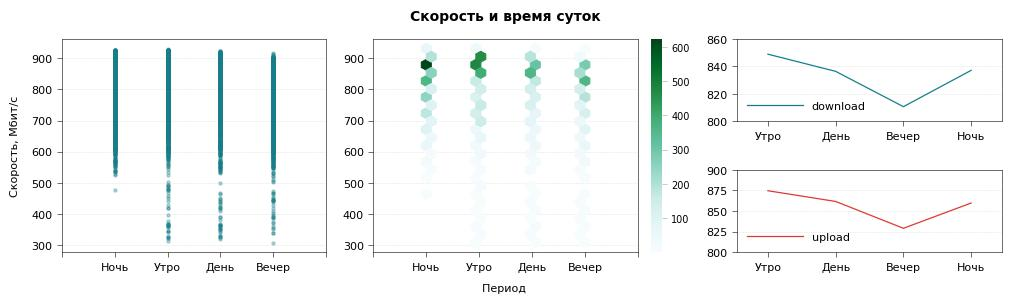

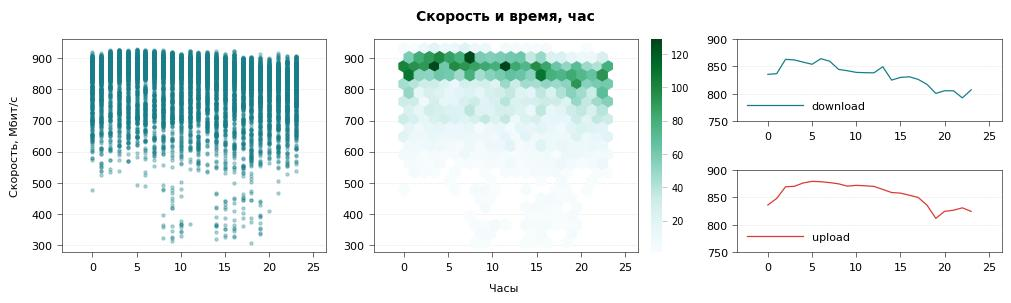

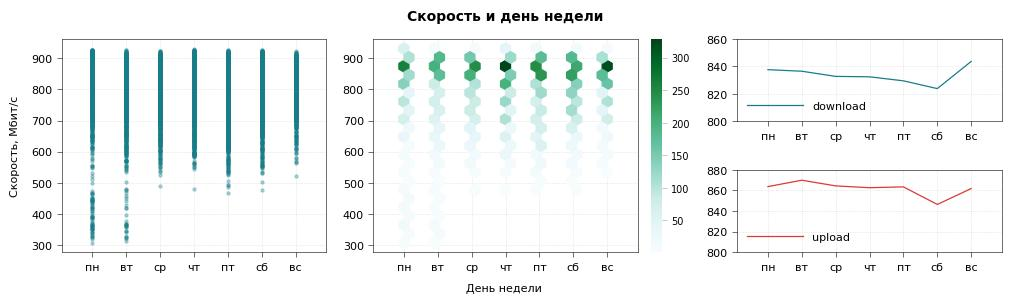

In [73]:
gsubplots(
    frame=[2,3],
    frame_cells=[[[0,2],0], [[0,2],1], [0,2], [1,2]],
    kinds=['scatter', 'hexbin', 'plot', 'plot'],
    data=[
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']), 'x': 'time_period_num', 'y': 'download', 
         'xticklabels': ['', 'Ночь', 'Утро', 'День', 'Вечер'], 
         'ylabel': 'Скорость, Мбит/с', 
         'tpl': 'scat_01',
         'cls': '0x0 x-ths ln-s5 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']), 'x': 'time_period_num', 'y': 'download', 
         # 'kind': 'hexbin',  
         'xticklabels': ['', 'Ночь', 'Утро', 'День', 'Вечер'], 
         'xlabel': 'Период', 
         'title': 'Скорость и время суток', 
         'gridsize': (16, 12),
         'tpl': 'hb_01',
         'cls': '0x0 x-ths t-ol hb-m1 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']).pivot_table(index='time_period', values='download', aggfunc='median').reindex(['Утро', 'День', 'Вечер', 'Ночь']), 
         'xticklabels': ['Утро', 'День', 'Вечер', 'Ночь'],
         # 'xlim': (0, 3),
         'ylim': (800, 860),
         'tpl': 'plot_01',
         'cls': '0x0 x-ths ln-l lg-bl xmg-15 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['upload']).pivot_table(index='time_period', values='upload', aggfunc='median').reindex(['Утро', 'День', 'Вечер', 'Ночь']), 
         'xticklabels': ['Утро', 'День', 'Вечер', 'Ночь'], 
         # 'xlim': (0, 3),
         'ylim': (800, 900),
         'yticks': 4,
         'tpl': 'plot_01',
         'cls': '0x0 x-ths ln-l ln-c1 lg-bl ax-ylcmn xmg-15 fig-n'
        },
    ],
    tpl='sbplot_01',
    cls='10x3 sp-ws0.05'
)

gsubplots(
    frame=[2,3],
    frame_cells=[[[0,2],0], [[0,2],1], [0,2], [1,2]],
    kinds=['scatter', 'hexbin', 'plot', 'plot'],
    data=[
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']), 'x': 'hour', 'y': 'download', 
         'ylabel': 'Скорость, Мбит/с', 
         'tpl': 'scat_01',
         'cls': '0x0 x-ths xtl-0 xmg-15 ln-s5 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']), 'x': 'hour', 'y': 'download', 
         # 'kind': 'hexbin', 
         'xlabel': 'Часы',
         'title': 'Скорость и время, час', 
         # 'xlim': (0, 25),
         # 'gridsize': (6, 4),
         'tpl': 'hb_01',
         'cls': '0x0 x-ths t-ol hb-m1 xmg-15 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']).pivot_table(index='hour', values='download', aggfunc='median'), 
         'ylim': (750, 900),
         # 'yticks': 4,
         'tpl': 'plot_01',
         'cls': '0x0 x-ths ln-l lg-bl xmg-15 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['upload']).pivot_table(index='hour', values='upload', aggfunc='median'), 
         'ylim': (750, 900),
         # 'yticks': 4,
         'tpl': 'plot_01',
         'cls': '0x0 x-ths ln-l ln-c1 lg-bl xmg-15 fig-n'
        },
    ],
    tpl='sbplot_01',
    cls='10x3 sp-ws0.05'
)

gsubplots(
    frame=[2,3],
    frame_cells=[[[0,2],0], [[0,2],1], [0,2], [1,2]],
    kinds=['scatter', 'hexbin', 'plot', 'plot'],
    data=[
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']), 'x': 'weekday', 'y': 'download', 
         'xticklabels': ['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс'],  
         'xticks': range(0, 9),
         # 'xticklabelstrip': 'right',
         'ylabel': 'Скорость, Мбит/с', 
         'tpl': 'scat_01',
         'cls': '0x0 gr x-ths ln-s5 xmg-15 fig-n' # xtl-spr 
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']), 'x': 'weekday', 'y': 'download', 
         'xticklabels': ['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс'],
         'xticks': range(0, 9),
         # 'xticklabelstrip': 'right',
         # 'kind': 'hexbin', 
         'xlabel': 'День недели', 
         'title': 'Скорость и день недели', 
         # 'gridsize': (12, 8),
         'tpl': 'hb_01',
         'cls': '0x0 gr x-ths t-ol hb-m1 xmg-15 fig-n'
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['download']).pivot_table(index='weekday', values='download', aggfunc='median'), 
         'xticklabels': ['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс'],
         'xticks': range(0, 9),
         # 'xticklabelstrip': 'right',
         'ylim': (800, 860),
         # 'yticks': 4,
         'tpl': 'plot_01',
         'cls': '0x0 gr x-ths ln-l lg-bl ax-ylcmn xmg-15 fig-n' # xtl-spr
        },
        {'data': clean_outliers(df, mask=gr_outliers_fix['upload']).pivot_table(index='weekday', values='upload', aggfunc='median'), 
         'xticklabels': ['пн', 'вт', 'ср', 'чт', 'пт', 'сб', 'вс'],
         'xticks': range(0, 9),
         'ylim': (800, 880),
         'yticks': 4,
         # 'xticklabelstrip': 'right',
         'tpl': 'plot_01',
         'cls': '0x0 gr x-ths ln-l ln-c1 lg-bl ax-ylcmn xmg-15 fig-n' # xtl-spr 
        },
    ],
    tpl='sbplot_01',
    cls='10x3 sp-ws0.05'
)

**Графики подтверждают расчеты и выводы. В вечерние часы и по субботам  показатели минимальные, а в утренние и по вторникам максимальные. В ночные и утренние часы самые плотные области с максимальной скоростью 850-920 Мбит/с.**

Однако минимальные величины коэффициента корреляции Пирсона говорят о слабой обратной связи. Вероятно, связь не линейного характера. Как уже было сказано ранее, широкополосный доступ нивелирует зависимость метрик.

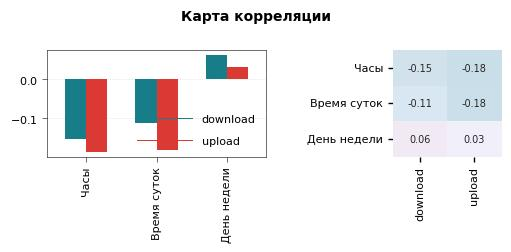

In [74]:
gsubplots(
    data=[
        {'data': corrmatrix(df, ['time_period_num', 'hour', 'weekday'], ['download', 'upload'], mask=gr_outliers_fix, skip_outliers=['time_period_num', 'hour', 'weekday']).sort_values(by='download'), 
         'xticklabels': ['Часы', 'Время суток', 'День недели'],
         'tpl': 'bar_01 lg_01f',
         'cls': '0x0 y-plain ax-r90 lg-br t-ol t-m2 lg-col1 lg-pth0.7 lg_lh_s ln-ct fig-n',
        }, 
        {'data': corrmatrix(df, ['time_period_num', 'hour', 'weekday'], ['download', 'upload'], mask=gr_outliers_fix, skip_outliers=['time_period_num', 'hour', 'weekday']).sort_values(by='upload'), 
         # 'cmap': [0, 5, 1], 
         'yticklabels': ['Часы', 'Время суток', 'День недели'],
         'tpl': 'hm_01',
         'cls': '0x0 t-ol t-m2 cm-1 xtl-r90 hm-afsxs fig-n',
        },
    ],
    frame=[1,3],
    frame_cells=[[0,[0,2]], [0,2]],
    kinds=['bar', 'sheatmap'],
    title='Карта корреляции', 
    tpl='sbplot_01',
    cls='5x2 t-ol sp-ws0.25'
)

#### Выводы

Проверка гипотезы показала:
1. Скорость интернет-соединения `зависит` от времени суток.

   Гипотеза подтвердилась. `Минимальные` показатели скорости наблюдались `вечером`, а `максимальные утром`. Высокая статистическая значимость (p-value близкое к 0) доказывает, что разница между утренней и вечерней скоростью не является случайным шумом или погрешностью измерений. Фактор времени суток оказывает реальное влияние на канал. Однако падение медиан на `~4%` и размер эффекта `-0.27` говорят о том, что общее `падение скорости` канала в «час пик» `незначительно` и `незаметно` для пользователя, благодаря запасу пропускной способности.


   В вечернее время зафиксирована скрытая аномалия на Upload: скорость падает из-за высокой вариативности (рост дисперсии в 2 раза) и локальных просадок (p10 падает на 15%). Это указывает на периодическую кратковременную загрузку обратного канала на оборудовании провайдера (например, соседи по дому начинают что-то активно загружать в сеть).

3. В какое время суток показатели метрик самые высокие и низкие соответственно?
  Расчеты показывают, что низкие показатели скорости наблюдались `вечером`, а высокие `утром`. Разница в интервале `4-5%`.

4. В какой час суток показатели метрик самые высокие и низкие соответственно?
  Минимальные показатели скорости наблюдались `вечером в 22 и 23 часа`, а максимальные `ночью в интервале с 2 до 5 часов`. Разница составила `~6-8%`.

5. В какой день недели показатели метрик самые высокие и низкие соответственно?
  Минимальные показатели скорости наблюдались по `сб`, а максимальные по `вт`. Разница составила `~2%`.

Минимальные величины коэффициента корреляции Пирсона говорят об очень слабой связи. Широкополосный доступ нивелирует зависимость метрик.

## 5. Оценка качества и стабильности интернет-соединения<a id="p5"></a>

Цель исследования — провести оценку стабильности и качества интернет-соединения путем сбора, анализа и оценки данных его ключевых метрик:
1. Скорость скачивания (Download, D) и загрузки (Upload, U).
2. Пинг (Ping, P).
3. Джиттер (Jitter, J).
4. Потеря пакетов (Loss, L).
5. Частота обрывов (Disconnects, Dc).

Объект исследования - гигабитный тариф с заявленной скоростью 1000 Мбит/с, и проводным Ethernet типом подключения.

>Что считать стабильным и качественным интернет соединением:
>- **Высокая и стабильная скорость.**
Соединение должно обеспечивать высокие показатели и отсутствие колебаний скорости, например, при просмотре онлайн-видео или видео-конференции. В зависимости от тарифа и типа подключения устройства (Wi-Fi, Ethernet) показатели хорошей скорости могут различаться. Например, для 100 мегабитного тарифа и Wi-Fi подключения, 30-80 Мбит/с считается хорошей скоростью, а для 1000 мегабитного и проводного подключения, отличная скорость 800-950 Мбит/с. 
>- **Низкий пинг.**
   Пинг меньше 20 мс считается хорошим. Низкий пинг критичен, например, для для онлайн-игр или трейдинга.
>- **Низкий джиттер.**
>- **Низкий процент потери пакетов.** 
>- **Отсутствие обрывов.**
>Стабильное соединение должно обеспечивать бесперебойную работу, без прерываний.

Для достижения цели исследования проанализируем частные и общую оценки ключевых метрик, характеризующих качество и стабильность интернет-соединения:
1. Рассчитаем частные оценки ключевых показателей интернет-соединения.
2. Используя композитный (составной) индекс, объединим ключевые метрики в одну общую оценку.

Для начала посмотрим частные оценки ключевых метрик. Для этого воспользуемся шкалами оценок, созданными на этапе категоризации данных

In [75]:
display(df[['download_rating', 'upload_rating', 'ping_rating', 'jitter_rating', 'packet_loss_rating', 'connection_lost_rating']].head(3))

,download_rating,upload_rating,ping_rating,jitter_rating,packet_loss_rating,connection_lost_rating
0,6,5,2.00,2.00,1.00,1
1,5,5,2.00,2.00,1.00,1
2,6,6,2.00,1.00,1.00,1


name,median,count,share
Идеально,865.48,5 265,62.1%
Отлично,725.65,3 118,36.8%
Хорошо,393.68,97,1.1%
name,median,count,share
Идеально,872.91,5 917,72.3%
Отлично,733.22,1 937,23.7%
Хорошо,439.13,280,3.4%
name,median,count,share
Идеально,4.48,7 912,96.4%
Хорошо,27.78,277,3.4%


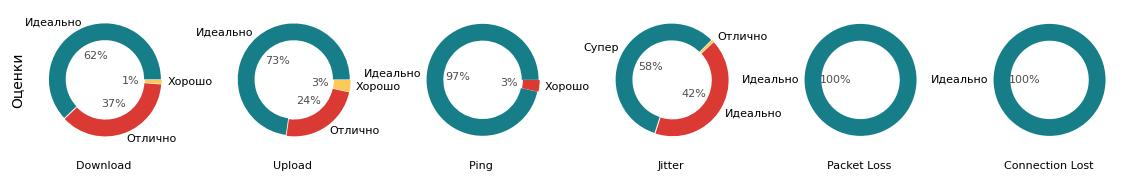

In [76]:
def get_rating_metrics(data, metric, rating_key, idx='name'):
    res = (
        data
        .merge(_rating_df[rating_key], left_on=f'{metric}_rating', right_on='id', how='inner')
        # .query(good_data_query.get(metric) or 'index==index')
        # .pivot_table(index=[idx], values=metric, aggfunc=['median', 'count'])
        .groupby(idx)[metric].agg(median='median', count='count', pct=lambda x: len(x) / len(data) * 100)
        .query('pct > 0.5')   
        .set_axis(['median', 'count', 'share'], axis=1).sort_values(by='count', ascending=False)
    )
    res['share'] = res['share'].map('{:.1f}%'.format)
    return res

# Таблицы
display_grid(
    [
    set_caption(
        get_rating_metrics(clean_outliers(df, mask=gr_outliers_fix['download']), 'download', 'speed'),
        caption='Download',
        format=True,
        is_flat_th=True
    ),
    set_caption(
        get_rating_metrics(clean_outliers(df, mask=gr_outliers_fix['upload']), 'upload', 'speed'),
        caption='Upload', 
        format=True,
        is_flat_th=True
    ),
    set_caption(
        get_rating_metrics(clean_outliers(df, mask=gr_outliers_fix['ping']), 'ping', 'ping'),
        caption='Ping', 
        format=True,
        is_flat_th=True
    ),
    set_caption(
        get_rating_metrics(clean_outliers(df, mask=gr_outliers_fix['jitter']), 'jitter', 'jitter'),
        caption='Jitter', 
        format=True,
        is_flat_th=True
    ),
    set_caption(
        get_rating_metrics(df, 'packet_loss', 'packet_loss'),
        caption='Packet Loss', 
        format=True,
        is_flat_th=True
    ),
    set_caption(
        get_rating_metrics(df, 'connection_lost', 'connection_lost'),
        caption='Connection Loss', 
        format=True,
        is_flat_th=True
    ),
    ],
    title='ОЦЕНКИ МЕТРИК',
    grid=[1,6],
    vspace=15
)

subplots(
    data=[
        {'data': get_rating_metrics(clean_outliers(df, mask=gr_outliers_fix['download']), 'download', 'speed'), 
         'y': 'count',
         'ylabel': 'Оценки',
         'xlabel': 'Download', 
         'tpl': 'pie_02e',
         'cls': '0x0 yl-pm yl-fsl t-oxl t-m3.2 fig-n'
        }, 
        {'data': get_rating_metrics(clean_outliers(df, mask=gr_outliers_fix['upload']), 'upload', 'speed'), 
         'y': 'count',
         'xlabel': 'Upload', 
         'tpl': 'pie_02e',
         'cls': '0x0 t-oxl t-m3.2 fig-n'
        }, 
        {'data': get_rating_metrics(clean_outliers(df, mask=gr_outliers_fix['ping']), 'ping', 'ping'), 
         'y': 'count',
         'xlabel': 'Ping', 
         'tpl': 'pie_02e',
         'cls': '0x0 t-oxl t-m3.2 fig-n'
        }, 
        {'data': get_rating_metrics(clean_outliers(df, mask=gr_outliers_fix['jitter']), 'jitter', 'jitter'), 
         'y': 'count',
         'xlabel': 'Jitter', 
         'tpl': 'pie_02e',
         'cls': '0x0 t-oxl t-m3.2 pie-sa45 fig-n'
        }, 
        {'data': get_rating_metrics(clean_outliers(df, mask=gr_outliers_fix['packet_loss']), 'packet_loss', 'packet_loss'), 
         'y': 'count',
         'xlabel': 'Packet Loss', 
         'tpl': 'pie_02e',
         'cls': '0x0 t-oxl t-m3.2 fig-n'
        }, 
        {'data': get_rating_metrics(clean_outliers(df, mask=gr_outliers_fix['connection_lost']), 'connection_lost', 'connection_lost'), 
         'y': 'count',
         'xlabel': 'Connection Lost', 
         'tpl': 'pie_02e',
         'cls': '0x0 t-oxl t-m3.2 fig-n'
        }, 
    ],
    frame=[1,6],
    kinds='pie',
    tpl='sbplot_01',
    cls='14x4 sp-ws0.35'
)

**Все метрики имеют высокие оценки `Идеально` и `Отлично`, редко `Хорошо`. Это характеризует уровень качества и стабильности интернет-соединения как `Высокий`.**

Для общей оценки качества и стабильности интернет-соединения воспользуемся композитным (составным) индексом, который объединит ключевые метрики в одну общую оценку.

Для объединения основных метрик в единую оценку необходимо нормализовать их значения.

### 5.1. Нормализация показателей<a id="p51"></a>

Нормализуем показатели приведением к шкале `0–1`, где `1` – наилучшее значение. Воспользуемся методом максимального и минимального абсолютного масштабирования.

Для скорость скачивания (`Download, D`) и загрузки (`Upload, U`), (чем больше, тем лучше):

$$
    D_{norm}=\frac{D-D_{min}}{D_{max}-D_{min}}, U_{norm}=\frac{U-U_{min}}{U_{max}-U_{min}},
$$

где $D_{min/max}, U_{min/max}$ – минимально/максимально возможные значения.

Для пинга (`Ping, P`), джиттера (`Jitter, J`), (чем меньше, тем лучше):

$$
    P_{norm}=\frac{P_{max}-P}{P_{max}-P_{min}}, J_{norm}=\frac{J_{max}-J}{J_{max}-J_{min}}
$$

где $P_{min/max}, J_{min/max}$ – минимально/максимально возможные значения.

Для потери пакетов (`Loss, L`) и частоты обрывов (`Disconnects, Dc`), (чем меньше, тем лучше):

$$
    L_{norm}=1-\frac{L}{100}, Dc_{norm}=\frac{1}{1+Dc},
$$

In [77]:
def normalize(metric, v, max_v=None, min_v=None):
    '''
    Нормализует значения метрик по методу максимального и минимального масштабирования. 

    :param str metric: Ключ метрики
    :param int|float v: Значение метрики
    :param int|float max_v: Максимальное значение метрики из выборки
    :param int|float min_v: Минимальное значение метрики из выборки
    '''
    if metric in ['ping', 'jitter']:
        # Все значения выше max_v станут равны max_v
        # return (max_v - v.clip(upper=max_v)) / (max_v - min_v)
        return (max_v - v.clip(None, max_v)) / (max_v - min_v)
    elif metric == 'connection_lost':
        return v.astype(int) ^ 1
    elif metric == 'packet_loss':
        return 1 - v / 100

    # return (v.clip(lower=min_v) - min_v) / (max_v - min_v)
    return (v.clip(min_v) - min_v) / (max_v - min_v)
    
def add_normalize_cols(
    data, 
    metrics=['download', 'upload', 'ping', 'jitter', 'packet_loss', 'connection_lost'], 
    axis=1, 
    norm_col_value='median', 
    norm_col_name=None,
    outliers=None,
    mask=None,
    skip_outliers=[]
):
    '''
    Добавляет столбец с нормализоваными значениями метрик.
    
    :param dataframe data: Таблица данных
    :param list metrics: Список метрик для нормализации. По-умолчанию, ['download', 'upload', 'ping', 'jitter', 'packet_loss', 'connection_lost'].
    :param int axis: Горизонтальная или вертикальная таблица: 0 - верт., метрики в строках; 1 - гориз., метрики в столбцах. 
    Например, axis=1, columns = ['download_norm', 'upload_norm', …], rows = [0, 1, 2, …].
    axis=0, columns = 'norm', rows = ['download', 'upload', …]
    :param str norm_col_value: Название столбца со значеними метрик для нормализации. По-умолчанию, `median`. Используется с `axis=0` для вертикальных таблиц. Если таблица горизонтальная `axis=1`, используется дефолтное название `f'{metric}_norm'` 
    :param str norm_col_name: Название столбца с нормализованными значеними метрик. По-умолчанию, `None`. В этом случае столбцу присваивается название `f'{metric}_norm'`  
    :param dict outliers: словарь с параметрами выбросов для фильтрации
    :param series|dict mask: маска выбросов для фильтрации
    :param list skip_outliers: список метрик для пропуска фильтрации
    '''
    for v in set_list(metrics):
        data_cleaned = clean_outliers_by_mask(data, column=v, outliers=outliers, mask=mask, skip_outliers=skip_outliers)[v] if axis == 1 else data
        # data_cleaned = filter_good_data(data_cleaned, good_data_query, v)[v] if axis == 1 else data_cleaned
        data.loc[data[v].index if axis == 1 else v, norm_col_name if norm_col_name else f'{v}_norm'] = normalize(
            v, 
            data[v] if axis == 1 else data[norm_col_value][v], 
            data_cleaned.max() if axis == 1 else data_cleaned['max'][v], 
            data_cleaned.min() if axis == 1 else data_cleaned['min'][v],
        )

    return data

In [78]:
df = add_normalize_cols(df, mask=gr_outliers_fix, skip_outliers=['packet_loss', 'connection_lost'])
print_rows(df, 3, ['download_norm', 'upload_norm', 'ping_norm', 'jitter_norm', 'packet_loss_norm', 'connection_lost_norm'])

,download_norm,upload_norm,ping_norm,jitter_norm,packet_loss_norm,connection_lost_norm
0,0.85,0.76,0.94,0.98,1.00,1.00
1,0.64,0.62,0.95,0.98,1.00,1.00
2,0.87,0.97,0.97,0.99,1.00,1.00


### 5.2. Оценка качества соединения<a id="p52"></a>

Общий индекс качества $Q$ рассчитаем как взвешенную сумму нормализованных показателей:

$$
Q=w_{D}*D_{norm}+w_{U}*U_{norm}+w_{P}*P_{norm}+w_{J}*J_{norm}+w_{L}*L_{norm}+w_{Dc}*Dc_{norm},
$$

где:
- $w$ – весовые коэффициенты, отражающие важность каждого параметра.

```
Однако данная аддитивная формула имеет критический нюанс, а именно эффект маскировки проблем. В линейной сумме высокий показатель одной метрики может полностью перекрыть (замаскировать) провал другой. 

Например, высокая скорость с D norm = 1.0 и обрывы соединения каждые 5 минут Dc norm = 0.0. Если у скорости вес 0.5, а у обрывов 0.1, то итоговый балл получится высоким (около 80-90%), хотя пользоваться таким интернетом физически невозможно.
```

Улучшим формулу добавив коэффициент-блокиратор (штраф) вместо обычных слагаемых для критических метрик: обрывы связи $Dc$ и потерю пакетов $L$ вынесем множителем-штрафом к итоговой сумме

$$
Q = \text{Penalty}(Dc, L) \times \left( w_D \cdot D_{norm} + w_U \cdot U_{norm} + w_P \cdot P_{norm} + w_J \cdot J_{norm} \right),
$$

Итоговая формула:

$$Q = P \times Q_{base},$$ 
где:

- $Q_{base}$ — базовая сумма основных метрик (скорость и задержка),
- $P$ — штрафной коэффициент (от 0 до 1), рассчитывается на основе потерь пакетов ($L$) и обрывов ($Dc$).

**Расчет базовой части $Q_{base}$**:

В базовой части оставим только метрики, которые определяют «комфорт» работы в стабильной сети

$$Q_{base} = w_D \cdot D_{norm} + w_U \cdot U_{norm} + w_P \cdot P_{norm} + w_J \cdot J_{norm}$$ 

Сумма их весов равна `1`: `$w_D + w_U + w_P + w_J = 1$`.

**Расчет системы штрафов $P$ (Penalty)**:

В основе две критические метрики: потеря пакетов ($L$, %) и частота обрывов ($Dc$, раз/час).

$$P = P_{L} \times P_{Dc}$$ 

Для расчета каждого штрафа используем экспоненциальную функцию. Она прощает мелкие погрешности, но жестко реагирует на серьезные сбои.

**Расчет штрафа за потерю пакетов ($P_{L}$)**:

$$P_{L} = e^{-k_1 \times L},$$ 

где:
- $L$ — текущий процент потери пакетов,
- $k_1$ — коэффициент жесткости.

При $k_1 = 0.5$:
- Потери 0% $\to e^0 = \mathbf{1.0}$ (нет штрафа).
- Потери 1% $\to e^{-0.5} = \mathbf{0.60}$ (оценка качества падает на 40%).
- Потери 5% $\to e^{-2.5} = \mathbf{0.08}$ (штраф съедает 92% оценки, интернет непригоден).

**Расчет штрафа за обрывы ($P_{Dc}$)**:

$$P_{Dc} = e^{-k_2 \times Dc},$$ 

где:
- $Dc$ — количество обрывов за час,
- $k_2$ — коэффициент жесткости.

При $k_2 = 1.2$:
- Обрывов 0 $\to e^0 = \mathbf{1.0}$ (нет штрафа).
- 1 обрыв $\to e^{-1.2} = \mathbf{0.30}$ (оценка падает на 70%, так как обрыв — это критично).
- 2 обрыва $\to e^{-2.4} = \mathbf{0.09}$ (оценка падает до минимума).

Составим таблицы весов метрик и коэффициентов жесткости

| Метрика | Вес ($w$) | Примечание |
|---|---|---|
| Download    | 0.25 | Важен для пользователей, скачивающих данные, просмотра видео |
| Upload	    | 0.25 | Важен для стриминга, видеозвонков |
| Ping	    | 0.25 | Критичен для онлайн-игр, VoIP |
| Jitter	    | 0.25 | Влияет на плавность связи |

В сумме все весовые коэффициенты дают 1.

| Метрика | Коэф. ($k$) | Примечание |
|---|---|---|
| Loss	    | -0.5 | Высокие потери ухудшают качество |
| Disconnects	| -1.2 | Частые обрывы делают соединение нестабильным |

In [79]:
quality_metric_weights = {
    'download': 0.25, 
    'upload': 0.25, 
    'ping': 0.25, 
    'jitter': 0.25,
}
quality_metric_penalty = {
    'packet_loss': -0.5, 
    'connection_lost': -1.2
}

def calc_Qm(metric, v):
    '''
    Расчитывает и возвращает индекс качества метрики. 
    Индекс расчитывается как произведение 
    нормализованного значения метрики и ее веса.

    :param str metric: Ключ метрики
    :param int|float v: Значение метрики
    '''
    return quality_metric_weights[metric] * v
    
def calc_Pm(metric, v):
    '''
    Расчитывает и возвращает величину штрафа метрики. 
    Расчитывается как экспоненциальная функция произведения 
    значения метрики и коэффициент жесткости.

    :param str metric: Ключ метрики
    :param int|float v: Значение метрики
    '''
    return np.exp(quality_metric_penalty[metric] * v)
    
def calc_P(
    data_row, 
    metrics, 
    axis=1,
    penalty_col_name=None
):
    '''
    Расчитывает и возвращает штрафной коэффициент. 
    Расчитывается как произведение коэффициентов метрик.
    
    :param dataframe data_row: Таблица данных
    :param list metrics: Список метрик для расчета штрафного коэффициента
    :param int axis: Горизонтальная или вертикальная таблица: 0 - верт., метрики в строках; 1 - гориз., метрики в столбцах. 
    Например, axis=1, columns = ['packet_loss', …], rows = [0, 1, 2, …].
    axis=0, columns = 'median', rows = ['packet_loss', …]
    '''
    p = 1
    for v in set_list(metrics):
        p *= calc_Pm(v, data_row[v] if axis == 1 else data_row.loc[v, penalty_col_name or 'median'])

    return p

def calc_Qbase(
    data_row, 
    metrics, 
    axis=1, 
    norm_col_name=None
):
    '''
    Расчитывает и возвращает базовый индекс качества. 
    Расчитывается как сумма индексов качества основных метрик.
    
    :param dataframe data_row: Таблица данных
    :param list metrics: Список метрик для расчета индекса качества
    :param int axis: Горизонтальная или вертикальная таблица: 0 - верт., метрики в строках; 1 - гориз., метрики в столбцах. 
    Например, axis=1, columns = ['download_norm', 'upload_norm', …], rows = [0, 1, 2, …].
    axis=0, columns = 'norm', rows = ['download', 'upload', …]
    :param str norm_col_name: Название столбца с нормализованными значеними метрик. По-умолчанию, `None` (`norm`)
    '''
    q_base = 0
    for v in set_list(metrics):
        q_base += calc_Qm(v, data_row[norm_col_name or 'norm' if norm_col_name else f'{v}_norm'] if axis == 1 else data_row.loc[v, norm_col_name or 'norm'])

    return q_base

def calc_Q(
    data_row, 
    qb_metrics=['download', 'upload', 'ping', 'jitter'], 
    p_metrics=['packet_loss', 'connection_lost'], 
    axis=1, 
    norm_col_name=None,
    penalty_col_name=None
):
    '''
    Расчитывает и возвращает общий индекс качества. 
    Расчитывается как произведение индекса качества основных метрик и штрафного коэффициента.
    
    :param dataframe data_row: Таблица данных
    :param list qb_metrics: Список основных метрик для расчета базового индекса качества
    :param list p_metrics: Список критичных метрик для расчета штрафного коэффициента
    :param int axis: Горизонтальная или вертикальная таблица: 0 - верт., метрики в строках; 1 - гориз., метрики в столбцах. 
    Например, axis=1, columns = ['download_norm', 'upload_norm', …], rows = [0, 1, 2, …].
    axis=0, columns = 'norm', rows = ['download', 'upload', …]
    :param str norm_col_name: Название столбца с нормализованными значеними метрик. По-умолчанию, `None` (`norm`)
    :param str penalty_col_name: Название столбца со значеними метрик. По-умолчанию, `None` (`median`)
    
    :example:
    `calc_Q(df)` //=> 0.75
    `calc_Q(desc_stat_df, axis=0, norm_col_name='norm')` //=> 0.75
    '''
    q_base = calc_Qbase(data_row, qb_metrics, axis, norm_col_name)
    p = calc_P(data_row, p_metrics, axis, penalty_col_name)

    return p * q_base

def add_quality_cols(data, **kwargs):
    '''
    Добавляет столбец с индексом качества.
    
    :param dataframe data: Таблица данных
    :param list metrics: Список метрик для расчетов. По-умолчанию, ['download', 'upload', 'ping', 'jitter', 'packet_loss', 'connection_lost'].
    :param int axis: Горизонтальная или вертикальная таблица: 0 - верт., метрики в строках; 1 - гориз., метрики в столбцах. 
    Например, axis=1, columns = ['download_norm', 'upload_norm', …], rows = [0, 1, 2, …].
    axis=0, columns = 'norm', rows = ['download', 'upload', …]
    :param str norm_col_name: Название столбца с нормализованными значеними метрик. По-умолчанию, `None`
    :param str col_value: Название столбца с расчитаными значениями качества. По-умолчанию, `None` (`quality`) 
    '''
    if kwargs.get('axis') == 0:
        data[kwargs.get('col_name') or 'quality'] = data.apply(lambda row: calc_Pm(row.name, row[kwargs.get('penalty_col_name') or 'median']) if row.name in ['packet_loss', 'connection_lost'] else calc_Qm(row.name, row[kwargs.get('norm_col_name') or 'norm']), axis=1)
    else:
        data[kwargs.get('col_name', 'quality')] = calc_Q(data, **kwargs)
         
    return data

In [80]:
df = add_quality_cols(df)
df['quality'] = pd.to_numeric(df['quality'], errors='coerce')
print_rows(df, 3, ['download_norm', 'upload_norm', 'ping_norm', 'jitter_norm', 'packet_loss_norm', 'connection_lost_norm', 'quality'])

,download_norm,upload_norm,ping_norm,jitter_norm,packet_loss_norm,connection_lost_norm,quality
0,0.85,0.76,0.94,0.98,1.00,1.00,0.88
1,0.64,0.62,0.95,0.98,1.00,1.00,0.80
2,0.87,0.97,0.97,0.99,1.00,1.00,0.95


Создадим категории оценок, добавим градации шкалы

In [81]:
# Разметка категорий качества
# bins включает нижнюю границу [ и исключает верхнюю )
# bins = [0.0, 0.3, 0.5, 0.75, 0.95, 1.01] # 1.01 чтобы включить чистую единицу
# labels = ['Плохое', 'Удовл.', 'Хорошее', 'Отличное', 'Идеальное']
# df['quality_cat'] = pd.cut(df['quality'], bins=bins, labels=labels, right=False)

def get_quality_category(r):
    '''
    ОЦЕНКА    КАЧЕСТВО
    0.95–1.0  идеальное
    0.75–0.95 отличное
    0.5–0.75  хорошее
    0.3–0.5   удовлетворительное
    <0.3      плохое
    '''
    if r < 0.3:
        return 'Плохое'
    elif r < 0.5:
        return 'Удовл.'
    elif r < 0.75:
        return 'Хорошее'
    elif r < 0.95:
        return 'Отличное'
    else:
        return 'Идеальное'

df['quality_cat'] = df['quality'].apply(get_quality_category)
print_rows(df, 5, ['download', 'upload', 'ping', 'jitter', 'packet_loss', 'connection_lost', 'quality', 'quality_cat'])

,download,upload,ping,jitter,packet_loss,connection_lost,quality,quality_cat
0,839.52,720.94,5.08,1.11,0,0,0.88,Отличное
1,704.23,611.95,4.82,1.08,0,0,0.80,Отличное
2,847.74,889.70,4.09,0.65,0,0,0.95,Отличное
3,889.37,875.95,3.89,0.64,0,0,0.96,Идеальное
4,832.71,877.71,4.11,0.76,0,0,0.94,Отличное


Посмотрим характерные значения оценок качества

In [82]:
display(
    set_caption(
        print_describe(df, 'quality', prec=2, to_html=True, cut_last=True),
        supcaption='Оценки качества', 
        caption='ХАРАКТЕРНЫЕ ЗНАЧЕНИЯ', 
        format=True,
        is_flat_th=True
    )
)

Среднее `0.87` и медиана `0.91` находятся в разумных пределах.

,median,count,share
Отличное,0.90,6 334,73.1%
Идеальное,0.96,1 509,17.4%
Хорошее,0.68,590,6.8%
Удовл.,0.45,176,2.0%
Плохое,0.15,56,0.6%

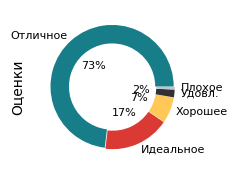

In [83]:
quality_cat_df = (
    df
    .groupby('quality_cat')['quality'].agg(median='median', count='count', pct=lambda x: len(x) / len(df) * 100)
    # .pivot_table(index=['quality_cat'], values='quality', aggfunc=['median', 'count',])
    .query('pct > 0.5')
    .set_axis(['median', 'count', 'share'], axis=1)
    .sort_values(by='count', ascending=False)
)
quality_cat_df.index.name = ''
quality_cat_df['share'] = quality_cat_df['share'].map('{:.1f}%'.format)


base64 = pie(
    quality_cat_df, 
    y='count',
    ylabel='Оценки', 
    tpl='pie_02e', 
    cls='3x2 yl-pm yl-fsl pie-aa0 fig-base64'
)

display_grid(
    [quality_cat_df, f'<img src="data:image/png;base64,{base64}">'],
    grid=[1,2],
    vspace=15,
    caption=['ОЦЕНКИ КАЧЕСТВА', ''],
    supcaption=' ',
    format=True,
    is_flat_th=True
)

**Суммарно оценки категории «Идеальное» и «Отличное» составляют `90.5%` от всей выборки. Общая оценка сети: `высокая стабильность` (90.5% нормы).** Это говорит о том, что в подавляющем большинстве случаев сеть работает великолепно и справляются с нагрузкой. Медиана для «Идеального» `0.96` показывает, что сеть способна выдавать практически свой технологический максимум. Наличие просадок категории «Удовлетворительно» и «Плохо» в сумме дают всего `2.6%`.

Проанализируем замеры с низкой оценкой. Считаем сбоем все замеры, у которых оценка ниже `0.5` («Удовлетворительно» и «Плохо»)

In [84]:
df['is_fault'] = df['quality'] < 0.5
# Подсчет длительности непрерывных сбоев
# Создаем уникальный ID для каждой непрерывной сессии сбоя
# (считает группы идущих подряд True в колонке is_fault)
df['fault_session_id'] = (df['is_fault'] != df['is_fault'].shift()).cumsum()

Посмотрим «сбойные» сервера и распределение сбоев по часам суток

In [85]:
display_grid(
    [
    # Группируем по часам и считаем количество сбоев за каждый час
    set_caption(
        df.groupby('hour')['is_fault'].sum().rename('count').sort_values(ascending=False).head(5),
        # df.groupby('hour').agg(count=('is_fault', 'sum'), server=('server_distance', lambda x: list(x.unique().tolist()))).sort_values(by='count', ascending=False).head(5),
        caption='ТОП-5', 
        supcaption='Сбойные часы', 
        format=True,
        is_flat_th=True
    ),
    # Группируем по серверам
    set_caption(
        df[df['is_fault']].groupby(['server_city', 'server_distance'])['is_fault'].sum().rename('count').sort_values(ascending=False).head(5),
        caption='ТОП-5', 
        supcaption='Сбойные сервера', 
        format=True,
        is_flat_th=True
    ),
    # Считаем длительность каждой сессии (количество замеров в ней)
    # умножаем размер группы на 5 минут (интервал замеров)
    set_caption(
        df[df['is_fault']].groupby(['fault_session_id', 'server_distance']).size().mul(5).rename('minute').sort_values(ascending=False).head(5),
        # df.groupby('hour').agg(count=('is_fault', 'sum'), server=('server_distance', lambda x: list(x.unique().tolist()))).sort_values(by='count', ascending=False).head(5),
        caption='ТОП-5', 
        supcaption='Длительность сбоев', 
        format=True,
        is_flat_th=True
    )
    ],
    grid=[1,3],
    vspace=25,
)

Данные показали, что низкие оценки это в большинстве своем не сбои канала связи, а особенности сбора данных. Большая часть замеров с низкими оценками сделана на удаленных серверах. Исключение составляют локальные сервера с расстоянием `4.37`. Изучим их.

In [86]:
display_grid(
    [
    # Группируем по серверам
    set_caption(
        df[(df['is_fault']) & (df['server_distance'] < 5)].groupby(['server_id', 'server_sponsor'])['is_fault'].sum().rename('count').sort_values(ascending=False).head(10),
        caption='СЕРВЕРА, 4.37 км', 
        supcaption='Кол-во сбоев',
        format=True,
        is_flat_th=True
    ),
    # Группируем по часам и считаем количество сбоев за каждый час
    set_caption(
        # df[df['server_distance'] < 5].groupby('hour')['is_fault'].sum().rename('count').sort_values(ascending=False).head(10),
        df[df['server_distance'] < 5].groupby('hour').agg(count=('is_fault', 'sum'), server_count=('server_id', lambda x: len(x.unique().tolist()))).sort_values(by='count', ascending=False).head(5),
        caption='ЧАСЫ СБОЕВ', 
        supcaption='Кол-во сбоев', 
        format=True,
        is_flat_th=True
    ),
    # Считаем длительность каждой сессии (количество замеров в ней)
    # умножаем размер группы на 5 минут (интервал замеров)
    set_caption(
        df[(df['is_fault']) & (df['server_distance'] < 5)].groupby(['fault_session_id', 'server_id']).size().mul(5).rename('minute').sort_values(ascending=False).head(7),
        # df.groupby('hour').agg(count=('is_fault', 'sum'), server=('server_distance', lambda x: list(x.unique().tolist()))).sort_values(by='count', ascending=False).head(5),
        supcaption='Сервер, минуты', 
        caption='ДЛИТЕЛЬНОСТЬ СБОЕВ', 
        format=True,
        is_flat_th=True
    )
    ],
    grid=[1,3],
    vspace=15,
)

server_id,server_sponsor,count
5 681,MOTIV,20
5 844,DOM.RU,13
6 616,t2 Russia,9
28 792,Rostelecom,9
69 510,Beeline Mobile,7
25 330,TTK Ural,4
28 672,GreenLine,1
hour,count,server_count
20,12,7
22,8,7


1. Зафиксированные сбои ближайших серверов происходят в определенные пероды `15-18` и `20-23` часов. Пик (`12 сбоев`) приходится на `20` часов. Это классический профиль вечернего пика нагрузки сети (prime time) — конец рабочего дня и вечернее время, когда пользователи массово потребляют трафик. В часы пик нагрузка растет на всех серверах в регионе. Поэтому список доступных серверов в утилите часто меняется — серверы «отваливаются» из-за переполнения пула подключений. Алгоритм автовыбора Speedtest хаотично перебирал оставшиеся в сети удаленные или менее производительные сервера и переключал замеры на них.

2. Замеры велись с шагом в `5` минут. Значения длительности `10`, `15` или `30` минут означают, что низкие оценки фиксировались ровно `2`, `3` или `6` замеров подряд. Если кратковременный всплеск нагрузки на сервере длился всего `6-7` минут, но попал на стык двух замеров, мы увидим «сбой длительностью `10` минут». Сеть не «лежала» — утилита фиксировала идущие подряд неудачные циклы автоматического выбора сервера.

Исключим удаленные сервера из выборки, чтобы очистить индекс качества от этого влияния и оценить его корректно.

,median,count,share
Отличное,0.90,6 334,73.1%
Идеальное,0.96,1 509,17.4%
Хорошее,0.68,590,6.8%
Удовл.,0.45,176,2.0%
Плохое,0.15,56,0.6%

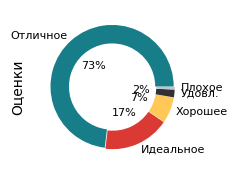

,median,count,share
Отличное,0.90,6 334,75.4%
Идеальное,0.96,1 509,18.0%
Хорошее,0.70,479,5.7%

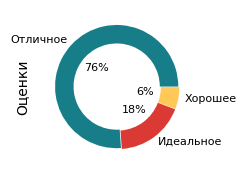

In [87]:
quality_cat_local_df = (
    df[df['server_distance'] < 1000]
    .groupby('quality_cat')['quality'].agg(median='median', count='count', pct=lambda x: len(x) / len(df[df['server_distance'] < 1000]) * 100)
    # .pivot_table(index=['quality_cat'], values='quality', aggfunc=['median', 'count',])
    .query('pct > 0.5')
    .set_axis(['median', 'count', 'share'], axis=1)
    .sort_values(by='count', ascending=False)
)
quality_cat_local_df.index.name = ''
quality_cat_local_df['share'] = quality_cat_local_df['share'].map('{:.1f}%'.format)

base64_local = pie(
    quality_cat_local_df, 
    y='count',
    ylabel='Оценки', 
    tpl='pie_02e', 
    cls='3x2 yl-pm yl-fsl pie-aa0 fig-base64'
)

display_grid(
    [quality_cat_df, f'<img src="data:image/png;base64,{base64}">'],
    grid=[1,2],
    vspace=15,
    caption=['ОЦЕНКИ КАЧЕСТВА', 'ОЦЕНКИ ДО'],
    supcaption=['С удаленными серверами', ' '],
    format=True,
    is_flat_th=True
)

display_grid(
    [quality_cat_local_df, f'<img src="data:image/png;base64,{base64_local}">'],
    grid=[1,4],
    vspace=15,
    caption=['ОЦЕНКИ КАЧЕСТВА', 'ОЦЕНКИ ПОСЛЕ'],
    supcaption=['Без удаленных серверов', ' '],
    format=True,
    is_flat_th=True
)

### Выводы<a id="p53"></a>

1. Высокие частные оценки метрик характеризует уровень качества и стабильности интернет-соединения как `Высокий`.
2. Общая оценка сети: `высокая стабильность`. Суммарно оценки категории «Идеальнo» и «Отлично» составляют `93.4%` от всей выборки. 
3. Низкие оценки `2.6%` — это артефакт методологии тестирования, а не реальные проблемы с качеством интернета. 
4. Интервал в `5 минут` в сочетании с алгоритмом автовыбора Speedtest в вечерние часы создавал «эффект домино»: временная недоступность одного популярного локального сервера заставляла утилиту переключаться по менее качественным или удаленным узлам в течение нескольких циклов замеров (`10–30 минут`), маскируя перебор серверов под сетевой сбой.

<!-- **Итоговая оценка качества соединения**

Оценка качества соединения отражает обобщённые результаты показателей, влияющих на стабильность сетевого соединения. Оценка представлена в виде шкалы от 0 до 100, где более высокие значения означают лучшее качество:

- 95 и выше — Отлично: Качество соединения не влияет на игровой процесс, а сбои случаются редко.
- 80-94 — Хорошо: Качество соединения вряд ли будет часто влиять на игру.
- 65-79 — Нормально: Качество соединения может негативно влиять на игровой процесс по сети, а сбои могут случаться чаще.
- 0-64 — Плохо: Качество соединения, скорее всего, будет негативно влиять на игровой процесс по сети, а сбои будут длиться дольше. -->

## Итоги исследования <a id="conclusion"></a>

В рамках данного проекта был исследован датасет данных метрик интернет-соединения гигабитного тарифа с заявленной скоростью 1000 Мбит/с, и проводным Ethernet типом подключения.

Цель исследования:

Провести оценку стабильности и качества интернет-соединения путем сбора, анализа и оценки данных его ключевых метрик:

- скорость скачивания и загрузки,
- пинг,
- джиттер,
- потеря пакетов,
- частота обрывов.

Дополнительно проверить гипотезу:
1. Скорость интернет-соединения зависит от времени суток.

И ответить на вопросы:
- В какое время суток, час, день недели показатели метрик самые высокие и низкие соответственно?

Исследование проходило в шесть этапов:

1. Сбор данных.
2. Обзор данных. 
3. Предобработка данных. 
4. Анализ метрик.
5. Оценка качества и стабильности интернет-соединения.
6. Подведение итогов исследования.

В ходе проведенного исследования установили, что общая оценка стабильности и качества интернет-соединения соответствует `высокому уровню`.

Исследование показало, что: 

1. Частные оценки метрик характеризует их уровень как `Высокий`.
2. Суммарно общие оценки категории «Идеальнo» и «Отлично» составляют `93.4%` от всей выборки. 
3. Низкие оценки «Удовл.» и «Плохо», составляющие `2.6%` — это артефакт методологии тестирования, а не реальные проблемы с качеством интернета. 
4. Интервал в `5 минут` в сочетании с алгоритмом автовыбора Speedtest в вечерние часы создавал «эффект домино»: временная недоступность одного популярного локального сервера заставляла утилиту переключаться по менее качественным или удаленным узлам в течение нескольких циклов замеров (`10–30 минут`), маскируя перебор серверов под сетевой сбой.

Это говорит о том, что в подавляющем большинстве случаев сеть работает безупречно и справляются с нагрузкой. Медиана для «Идеального» `0.96` показывает, что сеть способна выдавать свой технологический максимум.

Проверили гипотезу и установили:

1. Скорость интернет-соединения `зависит` от времени суток.

   Гипотеза подтвердилась. `Минимальные` показатели скорости наблюдались `вечером`, а `максимальные утром`. Высокая статистическая значимость (p-value близкое к 0) доказывает, что разница между утренней и вечерней скоростью не является случайным шумом или погрешностью измерений. Фактор времени суток оказывает реальное влияние на канал. Однако падение медиан на `~4%` и размер эффекта `-0.27` говорят о том, что общее `падение скорости` канала в «час пик» `незначительно` и `незаметно` для пользователя, благодаря запасу пропускной способности.

   В вечернее время зафиксирована скрытая аномалия на Upload: скорость падает из-за высокой вариативности (рост дисперсии в 2 раза) и локальных просадок (p10 падает на 15%). Это указывает на периодическую кратковременную загрузку обратного канала на оборудовании провайдера (например, соседи по дому начинают что-то активно загружать в сеть).

2. Ответили на вопросы:
- В какое время суток показатели метрик самые высокие и низкие соответственно?
  Расчеты показывают, что низкие показатели скорости наблюдались `вечером`, а высокие `утром`. Разница в интервале `4-5%`.

- В какой час суток показатели метрик самые высокие и низкие соответственно?
  Минимальные показатели скорости наблюдались `вечером в 22 и 23 часа`, а максимальные `ночью в интервале с 2 до 5 часов`. Разница составила `~6-8%`.

- В какой день недели показатели метрик самые высокие и низкие соответственно?
  Минимальные показатели скорости наблюдались по `сб`, а максимальные по `вт`. Разница составила `~2%`.

Минимальные величины коэффициента корреляции Пирсона говорят об очень слабой связи метрик с временными периодами. Широкополосный доступ нивелирует зависимость.